# 🍊 전국 32개 공영도매시장 3대 감귤 품종(`하우스감귤`, `조생귤`, `천혜향`) & 판매량 상위 5대 판매단위(`kind`) 가격·판매량 예측 AI (GPU 가속 & 기상 융합)

본 프로그램은 **`data\data1.csv`**, **`data\data2.csv`**(전국 32개 공영도매시장 경매 원본: 2018~2026년, 총 343,241건)와 **`data\forecast.csv`**(기상청 기상 관측 데이터: 2018~2026년)를 결합하여 다음과 같이 구성됩니다:

1. **예측 대상 3대 품종 (`TARGET_VARIETIES`)**: **`하우스감귤`**, **`조생귤`**, **`천혜향`**에 대해서만 가격(`price`) 및 판매량(`volume`) 예측을 수행합니다.
2. **나머지 품종의 전체 물량 피처 활용**: `기타감귤`, `비가림감귤`, `레드향`, `황금향`, `극조생감귤`, `온주` 등 나머지 19개 품종은 예측 대상에서 제외하고, **해당일의 전국 전체 감귤 총 거래물량(`all_citrus_total_kg`) 및 타 품종 물량 비중(`other_citrus_kg`, `other_citrus_share`)** 데이터로만 집계하여 시장 공급 압력 피처로 활용합니다.
3. **판매량 상위 5가지 판매단위(`Transaction Unit`) 예측**:
   - **하우스감귤 상위 5대 판매단위**: `3kg상자`, `5kg상자`, `3kg파렛트`, `6kg상자`, `0.5kg상자`
   - **조생귤 상위 5대 판매단위**: `5kg상자`, `10kg상자`, `5kg파렛트`, `5kg.`, `7.5kg상자`
   - **천혜향 상위 5대 판매단위**: `3kg상자`, `9kg상자`, `10kg상자`, `5kg상자`, `3kg파렛트`
4. **활용 모델**: `XGBoost (GPU)`, `LightGBM`, `TFT (PyTorch CUDA)`, `Ensemble` 및 **특정 기준일 이후 1주일간 최고 가격·물량 Top-2 날짜 예측**

## 0. 필수 라이브러리 설치 및 GPU 환경 설정
필요한 패키지가 설치되어 있지 않다면 아래 코드를 실행하거나 터미널에서 pip install -r requirements.txt를 실행하세요.
(NVIDIA GPU 환경인 경우 CUDA 호환 PyTorch 설치 권장)

In [1]:
# 1) requirements.txt를 통한 의존성 일괄 설치 (필요시 주석 해제)
# !pip install -r requirements.txt

# 2) 개별 패키지 설치 가이드 (NVIDIA GPU CUDA 12.8 예시)
# !pip install torch --index-url https://download.pytorch.org/whl/cu128
# !pip install numpy pandas matplotlib seaborn scikit-learn xgboost lightgbm lightning pytorch-forecasting

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb
import torch

warnings.filterwarnings('ignore')

# 한글 폰트 및 시각화 기본 설정 (Windows Malgun Gothic 우선 적용)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'Malgun Gothic' if os.name == 'nt' else 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False


# ==========================================
# GPU 가속 환경 감지 및 모델별 디바이스 설정
# ==========================================
USE_CUDA = torch.cuda.is_available()
device = torch.device('cuda' if USE_CUDA else 'cpu')
if USE_CUDA:
    torch.backends.cudnn.benchmark = True
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"[PyTorch GPU 활성화] 디바이스: {device} ({gpu_name}, VRAM: {vram_gb:.1f} GB, CUDA: {torch.version.cuda})")
else:
    print(f"[PyTorch 디바이스] {device} (CUDA 미감지 - GPU 사용 시 CUDA 지원 PyTorch 설치 필요)")

# XGBoost GPU 지원 여부 확인 (tree_method='hist', device='cuda')
def get_xgb_gpu_params():
    try:
        _test_m = xgb.XGBRegressor(tree_method='hist', device='cuda', n_estimators=1)
        _test_m.fit(np.zeros((4, 2)), np.zeros(4))
        print("[XGBoost GPU 활성화] tree_method='hist', device='cuda'")
        return {'tree_method': 'hist', 'device': 'cuda'}
    except Exception as e:
        print(f"[XGBoost CPU 모드] GPU 비활성 ({e})")
        return {'tree_method': 'hist', 'device': 'cpu', 'n_jobs': -1}

# LightGBM 디바이스 설정 (USE_LGB_GPU=True 설정 시 GPU 시도, 실패 시 CPU 멀티코어 자동 폴백)
def get_lgb_gpu_params(try_gpu=False):
    if try_gpu:
        for dev in ['cuda', 'gpu']:
            try:
                _test_m = lgb.LGBMRegressor(device=dev, n_estimators=1, verbose=-1)
                _test_m.fit(np.random.randn(10, 2), np.random.randn(10))
                print(f"[LightGBM GPU 활성화] device='{dev}'")
                return {'device': dev, 'n_jobs': -1}
            except Exception:
                continue
    print("[LightGBM 고속 병렬 모드] device='cpu', n_jobs=-1 (Windows 기본 패키지는 CMake GPU 빌드가 비활성화되어 있어 멀티코어 병렬 학습 적용)")
    return {'device': 'cpu', 'n_jobs': -1}

XGB_DEVICE_PARAMS = get_xgb_gpu_params()
LGB_DEVICE_PARAMS = get_lgb_gpu_params()

[PyTorch 디바이스] cpu (CUDA 미감지 - GPU 사용 시 CUDA 지원 PyTorch 설치 필요)
[XGBoost GPU 활성화] tree_method='hist', device='cuda'
[LightGBM 고속 병렬 모드] device='cpu', n_jobs=-1 (Windows 기본 패키지는 CMake GPU 빌드가 비활성화되어 있어 멀티코어 병렬 학습 적용)


## 1. `data1.csv`, `data2.csv`, `forecast.csv` 로드 및 3대 예측 품종(`하우스감귤`, `조생귤`, `천혜향`) · 전체 시장 물량 전처리
- **예측 대상 한정 (`하우스감귤`, `조생귤`, `천혜향`)**:
  - 전체 22개 감귤류 품종 중 **`하우스감귤`**, **`조생귤`**, **`천혜향`** 3개 품종만 예측 대상으로 분리하고, 각 품종별 **누적 판매량 상위 5가지 판매단위(`Transaction Unit`)**를 선별합니다.
- **나머지 품종 → 해당일 전체 물량 데이터(`all_citrus_total_kg`, `other_citrus_kg`)로만 활용**:
  - `기타감귤`, `비가림감귤`, `레드향`, `황금향`, `극조생감귤`, `온주` 등 나머지 품종들은 해당일의 **전국 전체 감귤 총 물량(`all_citrus_total_kg`)** 및 **기타 품종 합산 물량(`other_citrus_kg`)**으로만 집계하여 예측 모델의 시장 물량 입력 피처로 사용합니다.

In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd

TARGET_VARIETIES = ['하우스감귤', '조생귤', '천혜향']

def parse_weight_kg(kind_str):
    s = str(kind_str).strip()
    m_kg = re.search(r"(\d+(?:\.\d+)?)\s*kg", s, re.IGNORECASE)
    if m_kg:
        return float(m_kg.group(1))
    m_g = re.search(r"(\d+(?:\.\d+)?)\s*g", s, re.IGNORECASE)
    if m_g:
        return float(m_g.group(1)) / 1000.0
    return 5.0

def load_and_preprocess_weather_data(weather_path=r"data\forecast.csv"):
    candidates = [
        Path(weather_path),
        Path("data/forecast.csv"),
        Path("../data/forecast.csv")
    ]
    target_path = next((p for p in candidates if p.exists()), None)
    if target_path is None:
        raise FileNotFoundError(f"날씨 데이터 파일을 찾을 수 없습니다: {weather_path}")
        
    print(f"기상청 날씨 데이터 로드 경로: {target_path.resolve()}")
    for enc in ['cp949', 'euc-kr', 'utf-8', 'utf-8-sig']:
        try:
            wdf = pd.read_csv(target_path, encoding=enc)
            break
        except UnicodeDecodeError:
            continue
            
    wdf.columns = [c.strip() for c in wdf.columns]
    date_col = next((c for c in wdf.columns if c in ['일시', 'date', 'DATE']), wdf.columns[0])
    wdf['date'] = pd.to_datetime(wdf[date_col], errors='coerce')
    wdf = wdf.dropna(subset=['date']).copy()
    
    temp_col = next((c for c in wdf.columns if '기온' in c), None)
    rain_dur_col = next((c for c in wdf.columns if '강수' in c and '계속' in c), None)
    rain_max_col = next((c for c in wdf.columns if '최다' in c and '강수' in c), None)
    sun_col = next((c for c in wdf.columns if '일조' in c), None)
    snow_col = next((c for c in wdf.columns if '적설' in c), None)
    
    wdf['temp'] = pd.to_numeric(wdf[temp_col], errors='coerce') if temp_col else np.nan
    wdf['rain_dur'] = pd.to_numeric(wdf[rain_dur_col], errors='coerce').fillna(0.0) if rain_dur_col else 0.0
    wdf['rain_peak'] = pd.to_numeric(wdf[rain_max_col], errors='coerce').fillna(0.0) if rain_max_col else 0.0
    wdf['sun_hr'] = pd.to_numeric(wdf[sun_col], errors='coerce') if sun_col else np.nan
    wdf['is_snow'] = (pd.to_numeric(wdf[snow_col], errors='coerce') > 0).astype(int) if snow_col else 0
    
    wx_daily = wdf.groupby('date', as_index=False).agg(
        wx_temp_mean=('temp', 'mean'),
        wx_temp_max=('temp', 'max'),
        wx_temp_min=('temp', 'min'),
        wx_rain_dur=('rain_dur', 'mean'),
        wx_rain_dur_max=('rain_dur', 'max'),
        wx_rain_peak=('rain_peak', 'max'),
        wx_sun_hr=('sun_hr', 'mean'),
        wx_is_snow=('is_snow', 'max')
    ).sort_values('date').reset_index(drop=True)
    
    full_dates = pd.date_range(wx_daily['date'].min(), wx_daily['date'].max(), freq='D')
    wx_daily = wx_daily.set_index('date').reindex(full_dates).rename_axis('date').reset_index()
    
    wx_daily[['wx_temp_mean', 'wx_temp_max', 'wx_temp_min', 'wx_sun_hr']] = (
        wx_daily[['wx_temp_mean', 'wx_temp_max', 'wx_temp_min', 'wx_sun_hr']].interpolate().bfill().ffill()
    )
    wx_daily[['wx_rain_dur', 'wx_rain_dur_max', 'wx_rain_peak', 'wx_is_snow']] = (
        wx_daily[['wx_rain_dur', 'wx_rain_dur_max', 'wx_rain_peak', 'wx_is_snow']].fillna(0.0)
    )
    
    wx_daily['wx_is_rainy'] = ((wx_daily['wx_rain_dur'] > 0.5) | (wx_daily['wx_rain_peak'] > 0.5)).astype(int)
    wx_daily['wx_temp_spread'] = wx_daily['wx_temp_max'] - wx_daily['wx_temp_min']
    wx_daily['wx_temp_diff_1'] = wx_daily['wx_temp_mean'].diff(1).fillna(0.0)
    wx_daily['wx_temp_diff_3'] = wx_daily['wx_temp_mean'].diff(3).fillna(0.0)
    wx_daily['wx_temp_diff_7'] = wx_daily['wx_temp_mean'].diff(7).fillna(0.0)
    
    for lag in [1, 2, 3, 7]:
        wx_daily[f'wx_temp_lag_{lag}'] = wx_daily['wx_temp_mean'].shift(lag)
        wx_daily[f'wx_rain_dur_lag_{lag}'] = wx_daily['wx_rain_dur'].shift(lag)
        wx_daily[f'wx_sun_lag_{lag}'] = wx_daily['wx_sun_hr'].shift(lag)
        
    for w in [3, 7, 14, 30, 60]:
        wx_daily[f'wx_temp_rmean_{w}'] = wx_daily['wx_temp_mean'].rolling(w, min_periods=1).mean()
        wx_daily[f'wx_sun_rsum_{w}'] = wx_daily['wx_sun_hr'].rolling(w, min_periods=1).sum()
        wx_daily[f'wx_rain_rsum_{w}'] = wx_daily['wx_rain_dur'].rolling(w, min_periods=1).sum()
        wx_daily[f'wx_rain_peak_rmax_{w}'] = wx_daily['wx_rain_peak'].rolling(w, min_periods=1).max()
        
    wx_daily['wx_temp_anomaly_3_30'] = wx_daily['wx_temp_rmean_3'] - wx_daily['wx_temp_rmean_30']
    wx_daily = wx_daily.bfill().ffill()
    return wx_daily

def load_and_preprocess_data(
    data1_path=r"data\data1.csv",
    data2_path=r"data\data2.csv",
    weather_path=r"data\forecast.csv",
    top_n_kinds=5
):
    '''
    data1.csv, data2.csv 및 forecast.csv를 로드하여:
    - 예측 대상 품종은 하우스감귤, 조생귤, 천혜향 3개 품종으로 한정하고,
    - 나머지 19개 품종은 해당일의 전체 물량(all_citrus_total_kg, other_citrus_kg) 데이터로만 집계하여 피처로 활용합니다.
    '''
    p1 = Path(data1_path)
    p2 = Path(data2_path)
    if not p1.exists() or not p2.exists():
        raise FileNotFoundError(f"경매 데이터 원본 파일을 찾을 수 없습니다: {p1}, {p2}")
        
    print(f"경매 데이터 로드: {p1.name} + {p2.name} 전국 32개 도매시장 경매 통합 중...")
    df1 = pd.read_csv(p1, low_memory=False)
    df2 = pd.read_csv(p2, low_memory=False)
    comb = pd.concat([df1, df2], ignore_index=True)
    comb.columns = [c.strip() for c in comb.columns]
    comb['date'] = pd.to_datetime(comb['DATE'], errors='coerce')
    comb['Variety'] = comb['Variety'].astype(str).str.strip()
    comb['Transaction Unit'] = comb['Transaction Unit'].astype(str).str.strip()
    comb['Grade'] = comb['Grade'].astype(str).str.strip()
    
    for c in ['Average Price', 'Total Trading Volume', 'Total Trading Value']:
        if not pd.api.types.is_numeric_dtype(comb[c]):
            comb[c] = comb[c].astype(str).str.replace(',', '', regex=False).str.strip()
        comb[c] = pd.to_numeric(comb[c], errors='coerce')
        
    comb = comb[(comb['Total Trading Volume'] > 0) & (comb['Total Trading Value'] > 0)].dropna(subset=['date']).copy()
    print(f"전국 32개 도매시장 유효 경매: {len(comb):,}건 ({comb['date'].min().date()} ~ {comb['date'].max().date()})")
    
    # 1. 해당일의 전국 전체 감귤 물량 및 나머지 품종(하우스감귤·조생귤·천혜향 외 19개 품종) 물량만 일별 집계
    comb['is_target_var'] = comb['Variety'].isin(TARGET_VARIETIES)
    comb['other_var_kg'] = np.where(~comb['is_target_var'], comb['Total Trading Volume'], 0.0)
    comb['josaeng_kg'] = np.where(comb['Variety'] == '조생귤', comb['Total Trading Volume'], 0.0)
    comb['cheonhyehyang_kg'] = np.where(comb['Variety'] == '천혜향', comb['Total Trading Volume'], 0.0)
    comb['house_kg'] = np.where(comb['Variety'] == '하우스감귤', comb['Total Trading Volume'], 0.0)
    
    f_daily = comb.groupby('date', as_index=False).agg(
        raw_all_citrus_kg=('Total Trading Volume', 'sum'),
        raw_all_citrus_rev=('Total Trading Value', 'sum'),
        raw_other_citrus_kg=('other_var_kg', 'sum'),
        raw_field_josaeng_kg=('josaeng_kg', 'sum'),
        raw_field_geukjosaeng_kg=('other_var_kg', 'sum'),  # EDA 호환용(나머지 품종 전체 물량)
        raw_field_onju_kg=('cheonhyehyang_kg', 'sum'),    # EDA 호환용(천혜향 물량)
        raw_house_kg=('house_kg', 'sum'),
        raw_field_active_types=('Variety', 'nunique')
    ).sort_values('date').reset_index(drop=True)
    
    # 타 품종(하우스감귤 외 전체 물량 = 조생귤 + 천혜향 + 나머지 품종 전체 물량)
    f_daily['raw_field_total_kg'] = f_daily['raw_all_citrus_kg'] - f_daily['raw_house_kg']
    f_daily['raw_field_total_rev'] = f_daily['raw_all_citrus_rev']
    f_daily['raw_field_unit_price'] = f_daily['raw_all_citrus_rev'] / (f_daily['raw_all_citrus_kg'] + 1e-8)
    f_daily['raw_field_active'] = (f_daily['raw_field_total_kg'] > 0).astype(float)
    
    full_dates = pd.date_range(comb['date'].min(), comb['date'].max(), freq='D')
    f_daily = f_daily.set_index('date').reindex(full_dates).rename_axis('date').reset_index()
    zero_cols = [
        'raw_all_citrus_kg', 'raw_all_citrus_rev', 'raw_other_citrus_kg',
        'raw_field_total_kg', 'raw_field_total_rev',
        'raw_field_josaeng_kg', 'raw_field_geukjosaeng_kg', 'raw_field_onju_kg',
        'raw_house_kg', 'raw_field_active_types', 'raw_field_active'
    ]
    f_daily[zero_cols] = f_daily[zero_cols].fillna(0.0)
    f_daily['raw_field_unit_price'] = f_daily['raw_field_unit_price'].ffill(limit=14).fillna(0.0)
    
    # 해당일의 전체 물량 및 나머지 품종 물량 피처 (field_* 네이밍으로 모델 입력에 결합)
    f_daily['field_all_citrus_today_kg'] = f_daily['raw_all_citrus_kg']
    f_daily['field_other_citrus_today_kg'] = f_daily['raw_other_citrus_kg']
    f_daily['field_other_citrus_share_today'] = f_daily['raw_other_citrus_kg'] / (f_daily['raw_all_citrus_kg'] + 1e-8)
    f_daily['field_log_all_citrus_today'] = np.log1p(f_daily['raw_all_citrus_kg'])
    f_daily['field_log_other_citrus_today'] = np.log1p(f_daily['raw_other_citrus_kg'])
    
    f_daily['field_is_active_lag1'] = f_daily['raw_field_active'].shift(1).fillna(0.0)
    f_daily['field_active_days_7'] = f_daily['raw_field_active'].shift(1).rolling(7, min_periods=1).sum().fillna(0.0)
    f_daily['field_active_days_14'] = f_daily['raw_field_active'].shift(1).rolling(14, min_periods=1).sum().fillna(0.0)
    
    for lag in [1, 2, 3, 7, 14]:
        f_daily[f'field_prev_kg_{lag}'] = f_daily['raw_all_citrus_kg'].shift(lag).fillna(0.0)
        f_daily[f'field_prev_up_{lag}'] = f_daily['raw_field_unit_price'].shift(lag).fillna(0.0)
        f_daily[f'field_other_prev_kg_{lag}'] = f_daily['raw_other_citrus_kg'].shift(lag).fillna(0.0)
        
    for w in [3, 7, 14, 30]:
        f_daily[f'field_kg_rmean_{w}'] = f_daily['raw_all_citrus_kg'].shift(1).rolling(w, min_periods=1).mean().fillna(0.0)
        f_daily[f'field_up_rmean_{w}'] = f_daily['raw_field_unit_price'].shift(1).rolling(w, min_periods=1).mean().fillna(0.0)
        f_daily[f'field_other_kg_rmean_{w}'] = f_daily['raw_other_citrus_kg'].shift(1).rolling(w, min_periods=1).mean().fillna(0.0)
        
    f_daily['field_josaeng_kg_rmean_7'] = f_daily['raw_field_josaeng_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    f_daily['field_geukjosaeng_kg_rmean_7'] = f_daily['raw_other_citrus_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    f_daily['field_onju_kg_rmean_7'] = f_daily['raw_field_onju_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    
    f_daily['field_log_kg_lag1'] = np.log1p(f_daily['field_prev_kg_1'])
    f_daily['field_log_kg_rmean_7'] = np.log1p(f_daily['field_kg_rmean_7'])
    f_daily['field_log_kg_rmean_14'] = np.log1p(f_daily['field_kg_rmean_14'])
    
    # 2. 하우스감귤 전국 전체 시장 일별·판매단위(Transaction Unit)별 집계 (섹션 1~9 메인 판매단위 예측용)
    ht_raw = comb[comb['Variety'] == '하우스감귤'].copy()
    df = ht_raw.groupby(['date', 'Transaction Unit'], as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum'),
        market_count=('Wholesale Market', 'nunique'),
        Grade=('Grade', 'first')
    ).sort_values(['Transaction Unit', 'date']).reset_index(drop=True)
    
    df['kind'] = df['Transaction Unit']
    df['type'] = '하우스감귤'
    df['total_kg'] = df['volume']
    df['weight_kg'] = df['kind'].apply(parse_weight_kg)
    df['is_pallet'] = df['kind'].str.contains('파렛트').astype(int)
    df['unit_price'] = (df['total_price'] / df['volume']).round(2)
    df['price'] = (df['unit_price'] * df['weight_kg']).round(2)
    df = df.rename(columns={'total_price': 'total price'})
    
    # 3. 3대 예측 품종(하우스감귤, 조생귤, 천혜향) 원본 집계 테이블 보관
    target3_raw = comb[comb['Variety'].isin(TARGET_VARIETIES)].copy()
    field_raw_df = target3_raw.groupby(['date', 'Variety', 'Transaction Unit'], as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum'),
        market_count=('Wholesale Market', 'nunique'),
        Grade=('Grade', 'first')
    ).sort_values(['Variety', 'date']).reset_index(drop=True)
    field_raw_df['kind'] = field_raw_df['Transaction Unit']
    field_raw_df['type'] = field_raw_df['Variety']
    field_raw_df['total_kg'] = field_raw_df['volume']
    field_raw_df['weight_kg'] = field_raw_df['kind'].apply(parse_weight_kg)
    field_raw_df['unitprice'] = (field_raw_df['total_price'] / field_raw_df['volume']).round(2)
    field_raw_df['price'] = (field_raw_df['unitprice'] * field_raw_df['weight_kg']).round(2)
    field_raw_df = field_raw_df.rename(columns={'total_price': 'total price'})
    
    # 4. 하우스감귤 시장 전체 동향 (과거 시차 피처)
    mkt_daily = df.groupby('date', as_index=False).agg(
        mkt_total_kg=('total_kg', 'sum'),
        mkt_total_rev=('total price', 'sum'),
        mkt_active_kinds=('kind', 'nunique')
    ).sort_values('date').reset_index(drop=True)
    mkt_daily['mkt_unit_price'] = mkt_daily['mkt_total_rev'] / (mkt_daily['mkt_total_kg'] + 1e-8)
    
    for lag in [1, 2, 3, 7, 14]:
        mkt_daily[f'mkt_prev_kg_{lag}'] = mkt_daily['mkt_total_kg'].shift(lag)
        mkt_daily[f'mkt_prev_up_{lag}'] = mkt_daily['mkt_unit_price'].shift(lag)
    for w in [3, 7, 14]:
        mkt_daily[f'mkt_up_rmean_{w}'] = mkt_daily['mkt_unit_price'].shift(1).rolling(w).mean()
        mkt_daily[f'mkt_kg_rmean_{w}'] = mkt_daily['mkt_total_kg'].shift(1).rolling(w).mean()
        mkt_daily[f'mkt_kg_rmed_{w}'] = mkt_daily['mkt_total_kg'].shift(1).rolling(w).median()
    mkt_daily = mkt_daily.bfill()
    
    df = df.merge(mkt_daily, on='date', how='left')
    df['vol_share'] = df['total_kg'] / (df['mkt_total_kg'] + 1e-8)
    df['up_ratio'] = df['unit_price'] / (df['mkt_unit_price'] + 1e-8)
    
    # 5. 기상 데이터 로드 및 병합
    wx_daily = load_and_preprocess_weather_data(weather_path)
    df = df.merge(wx_daily, on='date', how='left')
    
    # 6. 해당일 전체 물량 및 타 품종 물량 피처 병합
    field_merge_cols = ['date'] + [c for c in f_daily.columns if c.startswith('field_')]
    df = df.merge(f_daily[field_merge_cols], on='date', how='left')
    
    # 총 판매량(volume) 합계 기준 상위 top_n_kinds(5가지) 판매단위 선별
    kind_vol_sum = df.groupby('kind')['volume'].sum().sort_values(ascending=False)
    selected_kinds = kind_vol_sum.head(top_n_kinds).index.tolist()
    kind_counts = df['kind'].value_counts()
        
    return df, wx_daily, f_daily, field_raw_df, comb, selected_kinds, kind_counts

raw_df, wx_daily_df, field_daily_df, field_raw_df, all_comb_df, TARGET_KINDS, kind_counts = load_and_preprocess_data(
    data1_path=r"data\data1.csv",
    data2_path=r"data\data2.csv",
    weather_path=r"data\forecast.csv",
    top_n_kinds=5
)
print(f"예측 대상 3대 품종: {TARGET_VARIETIES} | 나머지 19개 품종 → 해당일 전체 물량 피처(field_all_citrus_today_kg 등)로만 활용")
print(f"하우스감귤 판매량 상위 5대 판매단위(TARGET_KINDS): {TARGET_KINDS}")

print("\n=== [3대 예측 품종(하우스감귤, 조생귤, 천혜향) vs 나머지 품종(전체 물량 데이터용) 요약] ===")
var_role_df = all_comb_df.assign(
    구분=np.where(all_comb_df['Variety'].isin(TARGET_VARIETIES), all_comb_df['Variety'] + ' (예측 대상)', '나머지 19개 품종 합계 (전체 물량 피처 전용)')
).groupby('구분', as_index=False).agg(
    원본경매건수=('DATE', 'count'),
    거래일수=('date', 'nunique'),
    누적총물량_톤=('Total Trading Volume', lambda x: round(x.sum() / 1000.0, 1)),
    총거래금액_억원=('Total Trading Value', lambda x: round(x.sum() / 1e8, 1))
).sort_values('누적총물량_톤', ascending=False).reset_index(drop=True)
display(var_role_df)

print("\n=== [하우스감귤 총 판매량 상위 5대 판매단위(kind) 요약] ===")
kind_overview_df = (
    raw_df[raw_df['kind'].isin(TARGET_KINDS)]
    .groupby(['kind', 'weight_kg', 'is_pallet'], as_index=False)
    .agg(
        거래일수=('date', 'count'),
        시작일=('date', lambda x: x.min().date()),
        종료일=('date', lambda x: x.max().date()),
        누적총판매량_톤=('volume', lambda x: round(x.sum() / 1000.0, 1)),
        일평균전국물량_kg=('volume', lambda x: round(x.mean(), 1)),
        전국평균단위가격_원=('price', lambda x: round(x.mean(), 1)),
        전국평균kg단가_원=('unit_price', lambda x: round(x.mean(), 1)),
    )
    .sort_values('누적총판매량_톤', ascending=False)
    .reset_index(drop=True)
)
display(kind_overview_df)

경매 데이터 로드: data1.csv + data2.csv 전국 32개 도매시장 경매 통합 중...
전국 32개 도매시장 유효 경매: 343,047건 (2018-01-02 ~ 2026-11-06)
기상청 날씨 데이터 로드 경로: D:\hongdonjoo\ai\temp\AI\data\forecast.csv
예측 대상 3대 품종: ['하우스감귤', '조생귤', '천혜향'] | 나머지 19개 품종 → 해당일 전체 물량 피처(field_all_citrus_today_kg 등)로만 활용
하우스감귤 판매량 상위 5대 판매단위(TARGET_KINDS): ['3kg상자', '5kg상자', '3kg파렛트', '6kg상자', '0.5kg상자']

=== [3대 예측 품종(하우스감귤, 조생귤, 천혜향) vs 나머지 품종(전체 물량 데이터용) 요약] ===


,구분,원본경매건수,거래일수,누적총물량_톤,총거래금액_억원
0,조생귤 (예측 대상),58762,2671,541899.9,10861.9
1,나머지 19개 품종 합계 (전체 물량 피처 전용),135020,2743,477924.0,10809.4
2,하우스감귤 (예측 대상),108667,2589,104927.8,5017.0
3,천혜향 (예측 대상),40598,1326,67787.9,3706.1



=== [하우스감귤 총 판매량 상위 5대 판매단위(kind) 요약] ===


,kind,weight_kg,is_pallet,거래일수,시작일,종료일,누적총판매량_톤,일평균전국물량_kg,전국평균단위가격_원,전국평균kg단가_원
0,3kg상자,3.0,0,2366,2018-01-15,2026-11-06,38199.0,16145.0,19616.6,6538.9
1,5kg상자,5.0,0,2439,2018-01-02,2026-11-06,31134.3,12765.2,17646.1,3529.2
2,3kg파렛트,3.0,1,1785,2018-01-13,2026-11-06,5791.4,3244.5,19830.2,6610.1
3,6kg상자,6.0,0,1737,2018-02-27,2026-11-06,5411.6,3115.5,34106.7,5684.5
4,0.5kg상자,0.5,0,1472,2018-03-23,2026-11-03,4782.8,3249.2,2987.0,5974.1


## 2. 품목(`kind`)별 시계열, 날씨(`forecast.csv`) 및 노지감귤 대체재(`tangerine.csv`) 탐색적 데이터 분석 (EDA)
주요 `kind`별 하우스감귤 판매가격(`price`)·판매량(`volume`) 추이와 함께, **노지감귤(`조생귤`, `극조생감귤`, `온주`) 출하 물량** 및 **기상 데이터(`평균기온`, `일조시간`)** 간의 계절적 대체·보완 관계를 시각화합니다.

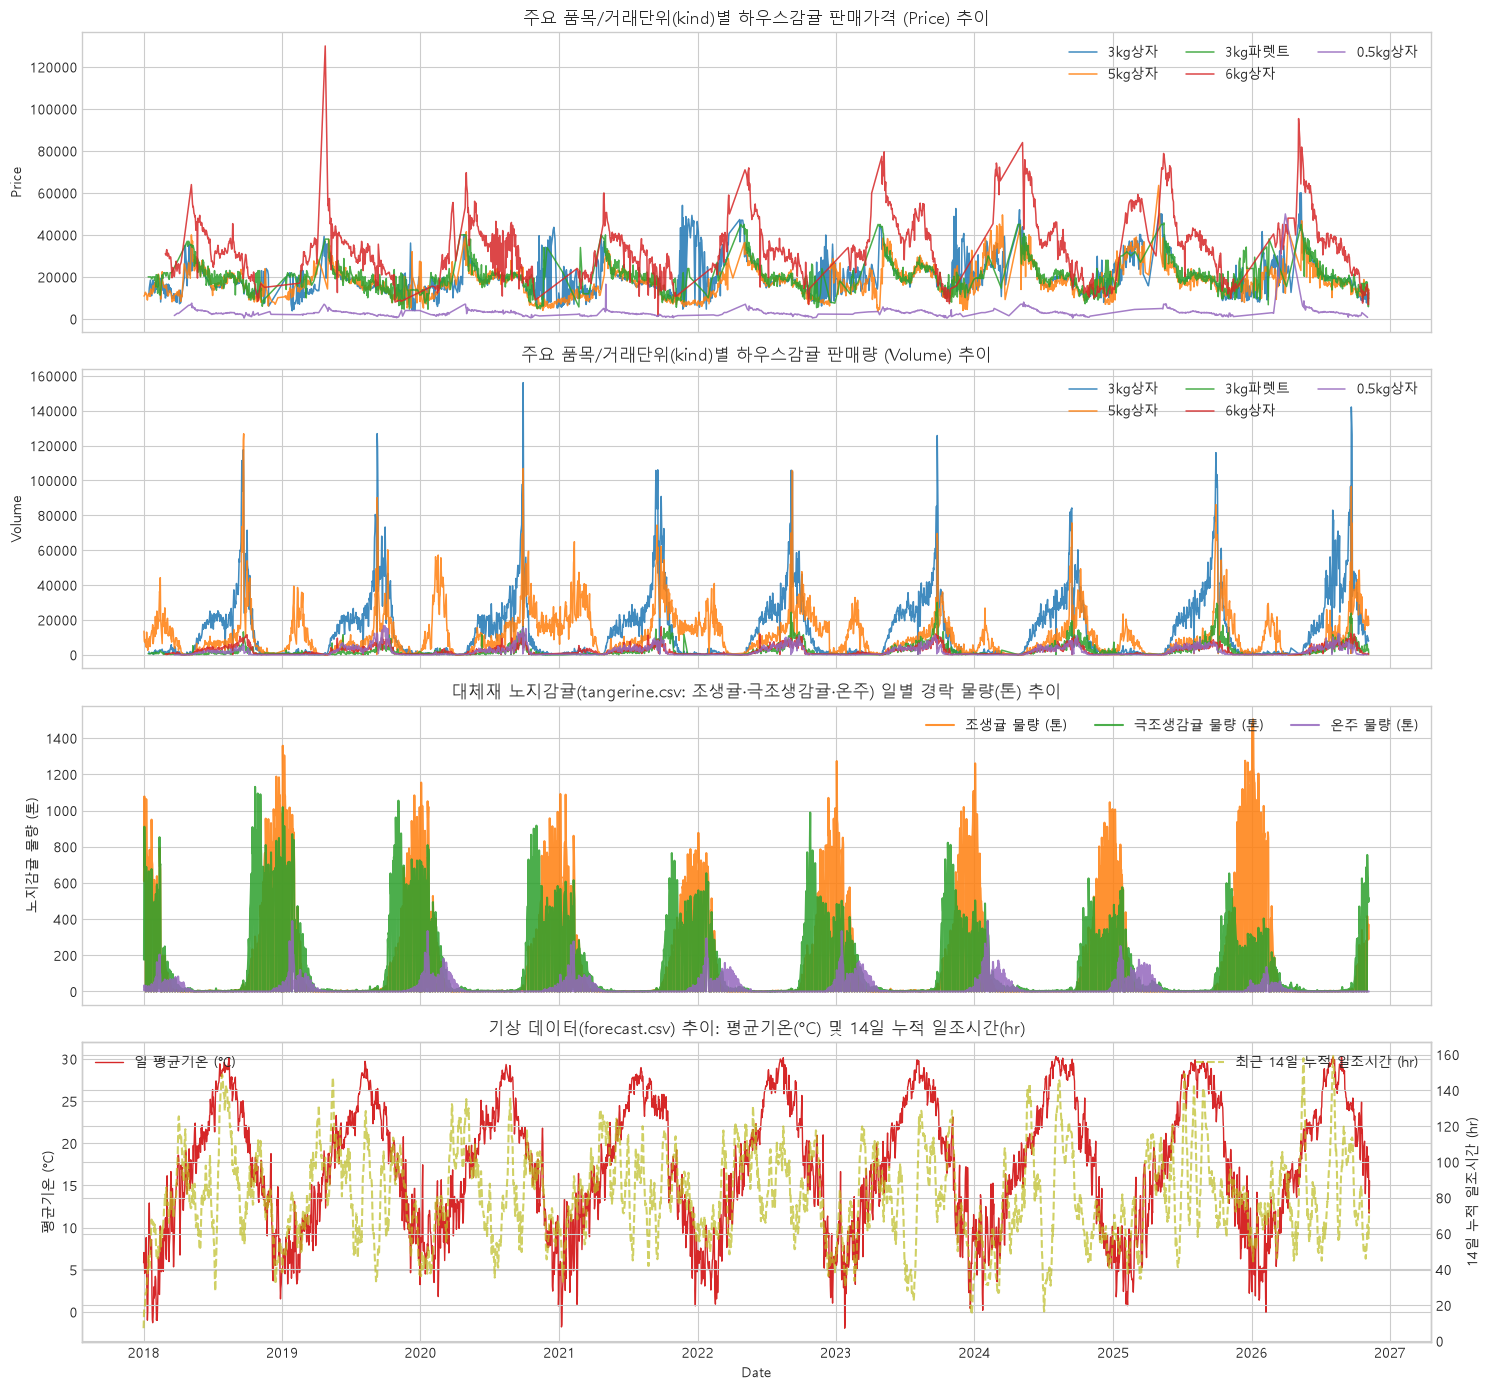

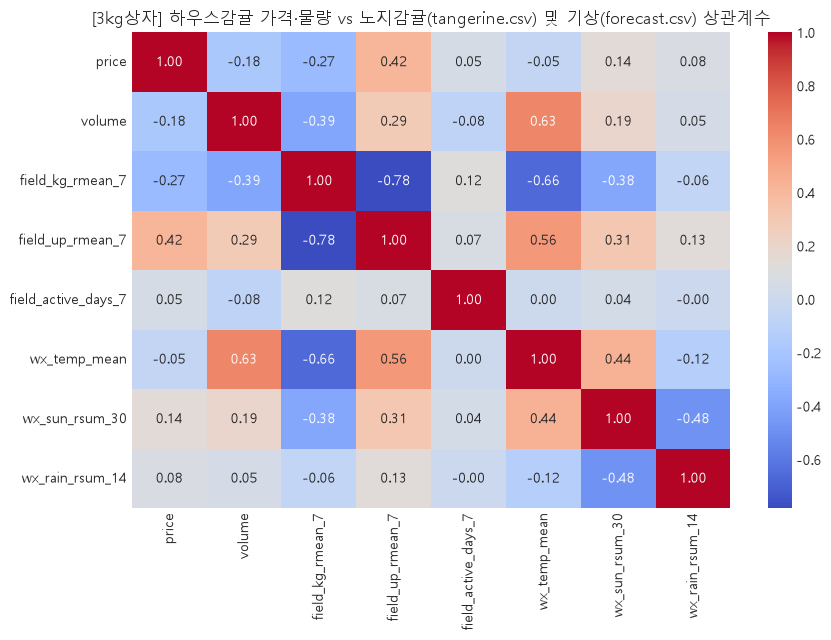

In [3]:
top_plot_kinds = TARGET_KINDS[:6]
sub_eda_df = raw_df[raw_df['kind'].isin(top_plot_kinds)].copy()

fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True)
for k in top_plot_kinds:
    k_df = sub_eda_df[sub_eda_df['kind'] == k]
    axes[0].plot(k_df['date'], k_df['price'], label=k, linewidth=1.1, alpha=0.85)
    axes[1].plot(k_df['date'], k_df['volume'], label=k, linewidth=1.1, alpha=0.85)

axes[0].set_title('주요 품목/거래단위(kind)별 하우스감귤 판매가격 (Price) 추이')
axes[0].set_ylabel('Price')
axes[0].legend(loc='upper right', ncol=3)

axes[1].set_title('주요 품목/거래단위(kind)별 하우스감귤 판매량 (Volume) 추이')
axes[1].set_ylabel('Volume')
axes[1].legend(loc='upper right', ncol=3)

# 노지감귤(조생귤, 극조생감귤, 온주) 품종별 반입 물량(kg) 추이
ax_f = axes[2]
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_josaeng_kg'] / 1000.0, label='조생귤 물량 (톤)', color='tab:orange', alpha=0.85)
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_geukjosaeng_kg'] / 1000.0, label='극조생감귤 물량 (톤)', color='tab:green', alpha=0.85)
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_onju_kg'] / 1000.0, label='온주 물량 (톤)', color='tab:purple', alpha=0.85)
ax_f.set_title('대체재 노지감귤(tangerine.csv: 조생귤·극조생감귤·온주) 일별 경락 물량(톤) 추이')
ax_f.set_ylabel('노지감귤 물량 (톤)')
ax_f.legend(loc='upper right', ncol=3)

# 기상 데이터 추이 (평균기온 및 14일 누적 일조시간)
ax_wx = axes[3]
ax_wx.plot(wx_daily_df['date'], wx_daily_df['wx_temp_mean'], color='tab:red', label='일 평균기온 (°C)', linewidth=1.0)
ax_wx2 = ax_wx.twinx()
ax_wx2.plot(wx_daily_df['date'], wx_daily_df['wx_sun_rsum_14'], color='tab:olive', linestyle='--', label='최근 14일 누적 일조시간 (hr)', alpha=0.7)
ax_wx.set_title('기상 데이터(forecast.csv) 추이: 평균기온(°C) 및 14일 누적 일조시간(hr)')
ax_wx.set_ylabel('평균기온 (°C)')
ax_wx2.set_ylabel('14일 누적 일조시간 (hr)')
ax_wx.set_xlabel('Date')
ax_wx.legend(loc='upper left')
ax_wx2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# 주력 품목(3kg상자) 기준 하우스감귤 가격/물량과 노지감귤·기상 변수 간 상관관계 히트맵
k0_df = raw_df[raw_df['kind'] == TARGET_KINDS[0]]
corr_cols = [
    'price', 'volume',
    'field_kg_rmean_7', 'field_up_rmean_7', 'field_active_days_7',
    'wx_temp_mean', 'wx_sun_rsum_30', 'wx_rain_rsum_14'
]
plt.figure(figsize=(9, 6.5))
sns.heatmap(k0_df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title(f'[{TARGET_KINDS[0]}] 하우스감귤 가격·물량 vs 노지감귤(tangerine.csv) 및 기상(forecast.csv) 상관계수')
plt.tight_layout()
plt.show()

## 3. 노지감귤 대체재(`tangerine.csv`) + 기상 변수(`forecast.csv`) + 시장 연동 시계열 피처 엔지니어링
각 `kind`별로 다음 7가지 핵심 피처 그룹을 생성하여 예측 정확도를 극대화합니다:
1. **노지감귤 대체재 시장 압력 피처 (`tangerine.csv`: 조생귤·극조생감귤·온주)**:
   - 과거 $1, 2, 3, 7, 14$일 노지감귤 총 반입 중량(`field_prev_kg_*`) 및 가중평균 단가(`field_prev_up_*`)
   - 최근 $3, 7, 14, 30$일 노지감귤 이동평균 반입량(`field_kg_rmean_*`), 품종별(`조생귤`, `극조생감귤`, `온주`) 최근 7일 평균 반입량, 최근 7·14일 중 노지감귤 출하일수(`field_active_days_*`)
   - **하우스감귤 vs 노지감귤 교차 대체 비율(`sub_*`)**: 전체 감귤 경락 물량 내 노지감귤 비중(`sub_kg_share_lag1`, `sub_kg_share_rmean7`), 하우스감귤 대비 노지감귤 단가 비율(`sub_up_ratio_lag1`) 및 단가 프리미엄 격차(`sub_up_diff_lag1`)
2. **기상 관측/예보 피처 (`forecast.csv`)**: 평균기온, 강수 계속시간, 최다강수량, 일조시간, 적설 여부 및 단기/중장기 누적·이상기온 파생변수
3. **캘린더 & 설날·추석 명절 특수 피처**: 연/월/일/요일 주기(`sin`, `cos`) + 설날·추석 전후 수요 급증/급감 구간
4. **비연속 거래 공백일(Gap) 및 거래 밀도 피처**: `days_since_last`, `trade_span_7`, `trade_span_14`
5. **품목별 다중 시차(Lag) & 로그 시차 피처**: 과거 $1\sim30$일 가격·판매량 및 `log1p(volume)`
6. **강건 이동 통계(Rolling Median & EMA)**: 스파이크 이상치에 강건한 이동중앙값 및 지수이동평균
7. **하우스감귤 전체 시장 연동(Cross-Kind Implied) 피처**: 전일 하우스감귤 전체 단가·물량 기반 기대치

In [4]:
LUNAR_HOLIDAYS = pd.to_datetime([
    # 2018년 (설날: 2.16, 추석: 9.24)
    "2018-02-16", "2018-09-24",
    # 2019년 (설날: 2.05, 추석: 9.13)
    "2019-02-05", "2019-09-13",
    # 2020년 (설날: 1.25, 추석: 10.01)
    "2020-01-25", "2020-10-01",
    # 2021년 (설날: 2.12, 추석: 9.21)
    "2021-02-12", "2021-09-21",
    # 2022년 (설날: 2.01, 추석: 9.10)
    "2022-02-01", "2022-09-10",
    # 2023년 (설날: 1.22, 추석: 9.29)
    "2023-01-22", "2023-09-29",
    # 2024년 (설날: 2.10, 추석: 9.17)
    "2024-02-10", "2024-09-17",
    # 2025년 (설날: 1.29, 추석: 10.06)
    "2025-01-29", "2025-10-06",
    # 2026년 (설날: 2.17, 추석: 9.25)
    "2026-02-17", "2026-09-25",
    # 2027년 (설날: 2.06, 추석: 9.15 - 미래 확장 대비)
    "2027-02-06", "2027-09-15",
])

def compute_holiday_features(date_series):
    diffs = np.array([(h - date_series).dt.days.values for h in LUNAR_HOLIDAYS])
    pre_holiday = ((diffs >= 0) & (diffs <= 14)).any(axis=0).astype(int)
    post_holiday = ((diffs >= -7) & (diffs < 0)).any(axis=0).astype(int)
    days_near = np.minimum(np.min(np.abs(diffs), axis=0), 60)
    return pre_holiday, post_holiday, days_near

def create_time_series_features_single_kind(df_kind, kind_id=0):
    d = df_kind.sort_values('date').reset_index(drop=True).copy()
    d['kind_id'] = kind_id
    
    # 1. 캘린더 및 설날·추석 명절 피처
    d['year'] = d['date'].dt.year
    d['month'] = d['date'].dt.month
    d['day'] = d['date'].dt.day
    d['dayofweek'] = d['date'].dt.dayofweek
    d['dayofyear'] = d['date'].dt.dayofyear
    d['is_weekend'] = (d['dayofweek'] >= 5).astype(int)
    d['month_sin'] = np.sin(2 * np.pi * d['month'] / 12.0)
    d['month_cos'] = np.cos(2 * np.pi * d['month'] / 12.0)
    d['doy_sin'] = np.sin(2 * np.pi * d['dayofyear'] / 365.25)
    d['doy_cos'] = np.cos(2 * np.pi * d['dayofyear'] / 365.25)
    
    pre_h, post_h, d_hol = compute_holiday_features(d['date'])
    d['is_pre_holiday'] = pre_h
    d['is_post_holiday'] = post_h
    d['days_near_holiday'] = d_hol
    
    # 2. 비연속 거래일(공백일) 및 거래 밀도 피처
    d['days_since_last'] = d['date'].diff().dt.days.fillna(1).clip(1, 90)
    d['trade_span_7'] = (d['date'].shift(1) - d['date'].shift(7)).dt.days.fillna(7).clip(7, 180)
    d['trade_span_14'] = (d['date'].shift(1) - d['date'].shift(14)).dt.days.fillna(14).clip(14, 365)
    
    # 3. 시차(Lag) 및 로그 시차 피처
    for lag in [1, 2, 3, 5, 7, 14, 21, 30]:
        d[f'price_lag_{lag}'] = d['price'].shift(lag)
        d[f'vol_lag_{lag}'] = d['volume'].shift(lag)
        d[f'log_vol_lag_{lag}'] = np.log1p(d['volume'].shift(lag))
        
    # 4. 이동평균(Mean), 이동중앙값(Median), 이동표준편차(Std) 및 지수이동평균(EMA)
    for w in [3, 7, 14, 30]:
        d[f'price_rmean_{w}'] = d['price'].shift(1).rolling(w).mean()
        d[f'price_rmed_{w}'] = d['price'].shift(1).rolling(w).median()
        d[f'price_rstd_{w}'] = d['price'].shift(1).rolling(w).std().fillna(0)
        d[f'vol_rmean_{w}'] = d['volume'].shift(1).rolling(w).mean()
        d[f'vol_rmed_{w}'] = d['volume'].shift(1).rolling(w).median()
        d[f'vol_rstd_{w}'] = d['volume'].shift(1).rolling(w).std().fillna(0)
        
    for span in [2, 3, 5, 7, 14]:
        d[f'price_ema_{span}'] = d['price'].shift(1).ewm(span=span).mean()
        d[f'vol_ema_{span}'] = d['volume'].shift(1).ewm(span=span).mean()
        
    # 5. 하우스감귤 전체 시장 연동(Cross-Kind Market) 점유율 및 기대 가격·물량 피처
    for lag in [1, 2, 3, 7]:
        d[f'vol_share_lag_{lag}'] = d['vol_share'].shift(lag)
        d[f'up_ratio_lag_{lag}'] = d['up_ratio'].shift(lag)
        
    d['vol_share_ema_5'] = d['vol_share'].shift(1).ewm(span=5).mean()
    d['up_ratio_ema_5'] = d['up_ratio'].shift(1).ewm(span=5).mean()
    d['vol_share_rmed_7'] = d['vol_share'].shift(1).rolling(7).median()
    d['up_ratio_rmed_7'] = d['up_ratio'].shift(1).rolling(7).median()
    
    d['implied_price_mkt_lag1'] = d['mkt_prev_up_1'] * d['weight_kg'] * d['up_ratio_ema_5']
    d['implied_price_mkt_rmean3'] = d['mkt_up_rmean_3'] * d['weight_kg'] * d['up_ratio_rmed_7']
    d['implied_vol_mkt_lag1'] = (d['mkt_prev_kg_1'] * d['vol_share_ema_5']) / d['weight_kg']
    d['implied_vol_mkt_rmed7'] = (d['mkt_kg_rmed_7'] * d['vol_share_rmed_7']) / d['weight_kg']
    
    # 6. 노지감귤(조생/극조생/온주) vs 하우스감귤 교차 대체(Substitute) 피처
    d['sub_kg_share_lag1'] = d['field_prev_kg_1'] / (d['mkt_prev_kg_1'] + d['field_prev_kg_1'] + 1e-8)
    d['sub_kg_share_rmean7'] = d['field_kg_rmean_7'] / (d['mkt_kg_rmean_7'] + d['field_kg_rmean_7'] + 1e-8)
    d['sub_kg_share_rmean14'] = d['field_kg_rmean_14'] / (d['mkt_kg_rmean_14'] + d['field_kg_rmean_14'] + 1e-8)
    d['sub_up_ratio_lag1'] = np.where(d['field_prev_up_1'] > 0, d['field_prev_up_1'] / (d['mkt_prev_up_1'] + 1e-8), 0.0)
    d['sub_up_diff_lag1'] = np.where(d['field_prev_up_1'] > 0, d['mkt_prev_up_1'] - d['field_prev_up_1'], 0.0)
    d['sub_field_implied_box_price'] = d['field_up_rmean_7'] * d['weight_kg']
    
    # 7. 기상 상호작용(Weather Interaction) 및 모멘텀 피처
    d['wx_temp_change_since_last'] = d['wx_temp_mean'] - d['wx_temp_mean'].shift(1).fillna(d['wx_temp_mean'])
    d['wx_sun_ratio_7_30'] = (d['wx_sun_rsum_7'] / 7.0) / ((d['wx_sun_rsum_30'] / 30.0) + 0.1)
    d['wx_rain_impact_vol'] = d['vol_ema_3'] * np.exp(-0.03 * d['wx_rain_dur'])
    
    d['price_diff_1'] = d['price'].shift(1) - d['price'].shift(2)
    d['price_ratio_1_7'] = d['price'].shift(1) / (d['price_rmean_7'] + 1e-8)
    d['vol_diff_1'] = d['volume'].shift(1) - d['volume'].shift(2)
    d['vol_ratio_1_7'] = d['volume'].shift(1) / (d['vol_rmean_7'] + 1e-8)
    
    return d.dropna().reset_index(drop=True)

kind_map = {k: idx for idx, k in enumerate(TARGET_KINDS)}
kind_datasets = {}
exclude_cols = [
    'date', 'kind', 'price', 'volume', 'total price',
    'unit_price', 'total_kg', 'mkt_total_kg', 'mkt_total_rev',
    'mkt_unit_price', 'mkt_active_kinds', 'vol_share', 'up_ratio'
]
feature_cols = None

split_summary_rows = []
for k in TARGET_KINDS:
    k_raw = raw_df[raw_df['kind'] == k].copy()
    k_feat = create_time_series_features_single_kind(k_raw, kind_id=kind_map[k])
    if feature_cols is None:
        feature_cols = [c for c in k_feat.columns if c not in exclude_cols]
        
    n_k = len(k_feat)
    tr_end = int(n_k * 0.70)
    va_end = int(n_k * 0.85)
    
    kind_datasets[k] = {
        'raw': k_raw,
        'feat': k_feat,
        'train': k_feat.iloc[:tr_end].copy(),
        'val': k_feat.iloc[tr_end:va_end].copy(),
        'test': k_feat.iloc[va_end:].copy(),
        'train_end': tr_end,
        'val_end': va_end
    }
    split_summary_rows.append({
        'kind': k,
        '전체_피처행수': n_k,
        'Train(70%)': len(kind_datasets[k]['train']),
        'Val(15%)': len(kind_datasets[k]['val']),
        'Test(15%)': len(kind_datasets[k]['test'])
    })

global_train_df = pd.concat([kind_datasets[k]['train'] for k in TARGET_KINDS], ignore_index=True)
global_val_df = pd.concat([kind_datasets[k]['val'] for k in TARGET_KINDS], ignore_index=True)

wx_feat_cols = [c for c in feature_cols if c.startswith('wx_')]
field_feat_cols = [c for c in feature_cols if c.startswith('field_') or c.startswith('sub_')]
print(f"총 피처 개수: {len(feature_cols)}개 (기상 피처 {len(wx_feat_cols)}개 + 노지감귤 대체재 피처 {len(field_feat_cols)}개 포함) | Global Train: {len(global_train_df):,}행")
print(f"노지감귤 대체재 주요 피처: {field_feat_cols}")
display(pd.DataFrame(split_summary_rows))


총 피처 개수: 216개 (기상 피처 49개 + 노지감귤 대체재 피처 47개 포함) | Global Train: 6,752행
노지감귤 대체재 주요 피처: ['field_all_citrus_today_kg', 'field_other_citrus_today_kg', 'field_other_citrus_share_today', 'field_log_all_citrus_today', 'field_log_other_citrus_today', 'field_is_active_lag1', 'field_active_days_7', 'field_active_days_14', 'field_prev_kg_1', 'field_prev_up_1', 'field_other_prev_kg_1', 'field_prev_kg_2', 'field_prev_up_2', 'field_other_prev_kg_2', 'field_prev_kg_3', 'field_prev_up_3', 'field_other_prev_kg_3', 'field_prev_kg_7', 'field_prev_up_7', 'field_other_prev_kg_7', 'field_prev_kg_14', 'field_prev_up_14', 'field_other_prev_kg_14', 'field_kg_rmean_3', 'field_up_rmean_3', 'field_other_kg_rmean_3', 'field_kg_rmean_7', 'field_up_rmean_7', 'field_other_kg_rmean_7', 'field_kg_rmean_14', 'field_up_rmean_14', 'field_other_kg_rmean_14', 'field_kg_rmean_30', 'field_up_rmean_30', 'field_other_kg_rmean_30', 'field_josaeng_kg_rmean_7', 'field_geukjosaeng_kg_rmean_7', 'field_onju_kg_rmean_7', 'field_log_kg

,kind,전체_피처행수,Train(70%),Val(15%),Test(15%)
0,3kg상자,2336,1635,350,351
1,5kg상자,2409,1686,361,362
2,3kg파렛트,1755,1228,263,264
3,6kg상자,1707,1194,256,257
4,0.5kg상자,1442,1009,216,217


## 4. 평가지표 및 예측 정확도(Accuracy) 함수 정의
- **정확도 (`Accuracy(%)`)**: $100 - \text{WAPE}(\%)$ (전체 규모 대비 가중 예측 정확도, 메인 정확도 지표)
- **대칭 정확도 (`sMAPE Accuracy(%)`)**: $100 - \text{sMAPE}(\%)$ (일별 대칭 백분율 오차 기반 정확도)
- **방향성 정확도 (`Directional Accuracy(%)`)**: 전일 대비 가격/판매량의 상승·하락 추세 방향 일치율
- **MAE** (Mean Absolute Error) / **RMSE** (Root Mean Squared Error)
- **MAPE** (Mean Absolute Percentage Error) / **WAPE** (Weighted Absolute Percentage Error) / **$R^2$ Score**

In [5]:
def evaluate_predictions(y_true, y_pred, model_name="Model", target_name="Target", kind_name="All"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    non_zero = np.abs(y_true) > 1e-6
    mape = np.mean(np.abs((y_true[non_zero] - y_pred[non_zero]) / y_true[non_zero])) * 100 if np.any(non_zero) else np.nan
    wape = (np.sum(np.abs(y_true - y_pred)) / (np.sum(np.abs(y_true)) + 1e-8)) * 100
    smape = np.mean(2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    r2 = r2_score(y_true, y_pred)
    
    acc_wape = max(0.0, 100.0 - wape)
    acc_smape = max(0.0, 100.0 - smape)
    acc_mape = max(0.0, 100.0 - mape) if not np.isnan(mape) else np.nan
    
    if len(y_true) > 1:
        true_dir = np.sign(np.diff(y_true))
        pred_dir = np.sign(np.diff(y_pred))
        dir_acc = np.mean(true_dir == pred_dir) * 100.0
    else:
        dir_acc = np.nan
    
    return {
        'kind': kind_name,
        'Model': model_name,
        'Target': target_name,
        '정확도(100-WAPE, %)': round(acc_wape, 2),
        '대칭정확도(100-sMAPE, %)': round(acc_smape, 2),
        '방향정확도(DA, %)': round(dir_acc, 2),
        '정밀정확도(100-MAPE, %)': round(acc_mape, 2),
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE(%)': round(mape, 2),
        'WAPE(%)': round(wape, 2),
        'R2': round(r2, 4)
    }

def optimize_blend_weights(y_val_true, val_candidates_list, test_candidates_list, step=0.2):
    """Validation 셋의 WAPE 정확도를 최대화하는 가중치 조합을 탐색하여 Test 예측값을 산출"""
    y_val_true = np.asarray(y_val_true, dtype=float)
    val_mat = np.column_stack(val_candidates_list)
    test_mat = np.column_stack(test_candidates_list)
    k_num = val_mat.shape[1]
    
    grid_vals = np.arange(0.0, 1.0 + 1e-6, step)
    best_acc = -1.0
    best_w = np.ones(k_num) / k_num
    
    def _search(idx, rem, cur_w):
        nonlocal best_acc, best_w
        if idx == k_num - 1:
            w = np.array(cur_w + [max(0.0, rem)])
            pred_val = val_mat @ w
            wape = np.sum(np.abs(y_val_true - pred_val)) / (np.sum(np.abs(y_val_true)) + 1e-8) * 100.0
            acc = 100.0 - wape
            if acc > best_acc:
                best_acc = acc
                best_w = w
            return
        for g in grid_vals:
            if g <= rem + 1e-6:
                _search(idx + 1, rem - g, cur_w + [g])
                
    _search(0, 1.0, [])
    return np.maximum(0.0, test_mat @ best_w), np.maximum(0.0, val_mat @ best_w), best_w

def record_metric(metrics_list, metric_dict):
    metrics_list[:] = [
        m for m in metrics_list
        if not (m['kind'] == metric_dict['kind'] and m['Model'] == metric_dict['Model'] and m['Target'] == metric_dict['Target'])
    ]
    metrics_list.append(metric_dict)

def display_model_kind_summary(metrics_list, model_name):
    df_m = pd.DataFrame([m for m in metrics_list if m['Model'] == model_name])
    p_df = df_m[df_m['Target'] == 'price'].set_index('kind')
    v_df = df_m[df_m['Target'] == 'volume'].set_index('kind')
    
    combined = pd.DataFrame({
        'kind(거래단위)': p_df.index,
        '판매가격(price) 정확도(%)': p_df['정확도(100-WAPE, %)'].values,
        '판매가격(price) 대칭정확도(%)': p_df['대칭정확도(100-sMAPE, %)'].values,
        '판매가격(price) MAE': p_df['MAE'].values,
        '판매가격(price) R²': p_df['R2'].values,
        '판매량(volume) 정확도(%)': v_df.loc[p_df.index, '정확도(100-WAPE, %)'].values,
        '판매량(volume) 대칭정확도(%)': v_df.loc[p_df.index, '대칭정확도(100-sMAPE, %)'].values,
        '판매량(volume) MAE': v_df.loc[p_df.index, 'MAE'].values,
        '판매량(volume) R²': v_df.loc[p_df.index, 'R2'].values,
    })
    print(
        f"▶ [{model_name}] 전체 kind 평균 — "
        f"판매가격(price) 평균 정확도: {combined['판매가격(price) 정확도(%)'].mean():.2f}% | "
        f"판매량(volume) 평균 정확도: {combined['판매량(volume) 정확도(%)'].mean():.2f}%"
    )
    display(combined)

metrics_summary = []
predictions_by_kind = {k: {} for k in TARGET_KINDS}
val_predictions_by_kind = {k: {} for k in TARGET_KINDS}

## 5. Model 1: 품목/거래단위(`kind`)별 XGBoost (GPU, Global-Local Hybrid) 예측
- **개선 포인트**:
  1. `np.log1p` 타겟 변환 및 `objective='reg:absoluteerror'`(L1 Loss)를 적용하여 WAPE 오차율을 직접 최소화합니다.
  2. 전체 품목 데이터를 통합 학습한 **Global XGBoost 모델**과 품목별 **Local XGBoost 모델**, 그리고 단기 지수이동평균/시장 추정치를 Validation 셋 기준으로 최적 결합하여 소표본 규격의 과적합을 방지합니다.

In [6]:
xgb_models_by_kind = {}

# XGBoost 입력 피처 타입 검증 및 수치형 보장
feature_cols = [c for c in feature_cols if c in global_train_df.select_dtypes(include=[np.number]).columns]

# 1) Global XGBoost 모델 학습 (모든 kind의 공통 계절성 및 시장 탄력성 학습)
xgb_global_vol = xgb.XGBRegressor(
    n_estimators=1000, learning_rate=0.03, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
    random_state=42, early_stopping_rounds=50, **XGB_DEVICE_PARAMS
)
xgb_global_vol.fit(
    global_train_df[feature_cols], np.log1p(global_train_df['volume']),
    eval_set=[(global_val_df[feature_cols], np.log1p(global_val_df['volume']))],
    verbose=False
)

xgb_global_price = xgb.XGBRegressor(
    n_estimators=1000, learning_rate=0.03, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
    random_state=42, early_stopping_rounds=50, **XGB_DEVICE_PARAMS
)
xgb_global_price.fit(
    global_train_df[feature_cols], np.log1p(global_train_df['price']),
    eval_set=[(global_val_df[feature_cols], np.log1p(global_val_df['price']))],
    verbose=False
)

# 2) 각 kind별 Local XGBoost 학습 및 Validation 최적 하이브리드 결합
for k in TARGET_KINDS:
    ds = kind_datasets[k]
    tr_df, va_df, te_df = ds['train'], ds['val'], ds['test']
    
    # Local Volume 모델
    xgb_local_vol = xgb.XGBRegressor(
        n_estimators=800, learning_rate=0.03, max_depth=4,
        subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
        random_state=42, early_stopping_rounds=50, **XGB_DEVICE_PARAMS
    )
    xgb_local_vol.fit(
        tr_df[feature_cols], np.log1p(tr_df['volume']),
        eval_set=[(va_df[feature_cols], np.log1p(va_df['volume']))],
        verbose=False
    )
    
    pred_vol_te, pred_vol_va, _ = optimize_blend_weights(
        va_df['volume'].values,
        [
            np.expm1(xgb_global_vol.predict(va_df[feature_cols])),
            np.expm1(xgb_local_vol.predict(va_df[feature_cols])),
            va_df['vol_ema_3'].values,
            va_df['vol_rmed_7'].values,
            va_df['implied_vol_mkt_lag1'].values
        ],
        [
            np.expm1(xgb_global_vol.predict(te_df[feature_cols])),
            np.expm1(xgb_local_vol.predict(te_df[feature_cols])),
            te_df['vol_ema_3'].values,
            te_df['vol_rmed_7'].values,
            te_df['implied_vol_mkt_lag1'].values
        ],
        step=0.25
    )
    
    # Local Price 모델
    xgb_local_price = xgb.XGBRegressor(
        n_estimators=800, learning_rate=0.03, max_depth=4,
        subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
        random_state=42, early_stopping_rounds=50, **XGB_DEVICE_PARAMS
    )
    xgb_local_price.fit(
        tr_df[feature_cols], np.log1p(tr_df['price']),
        eval_set=[(va_df[feature_cols], np.log1p(va_df['price']))],
        verbose=False
    )
    
    pred_price_te, pred_price_va, _ = optimize_blend_weights(
        va_df['price'].values,
        [
            np.expm1(xgb_global_price.predict(va_df[feature_cols])),
            np.expm1(xgb_local_price.predict(va_df[feature_cols])),
            va_df['price_ema_2'].values,
            va_df['implied_price_mkt_lag1'].values
        ],
        [
            np.expm1(xgb_global_price.predict(te_df[feature_cols])),
            np.expm1(xgb_local_price.predict(te_df[feature_cols])),
            te_df['price_ema_2'].values,
            te_df['implied_price_mkt_lag1'].values
        ],
        step=0.2
    )
    
    xgb_models_by_kind[k] = {
        'vol_model': xgb_local_vol,
        'price_model': xgb_local_price,
        'price_features': feature_cols
    }
    predictions_by_kind[k]['xgb_volume'] = pred_vol_te
    predictions_by_kind[k]['xgb_price'] = pred_price_te
    val_predictions_by_kind[k]['xgb_volume'] = pred_vol_va
    val_predictions_by_kind[k]['xgb_price'] = pred_price_va
    
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], pred_vol_te, 'XGBoost', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], pred_price_te, 'XGBoost', 'price', kind_name=k))

print(f"[XGBoost Global-Local 하이브리드 예측 완료 | 사용 설정: {XGB_DEVICE_PARAMS}]")
display_model_kind_summary(metrics_summary, 'XGBoost')


[XGBoost Global-Local 하이브리드 예측 완료 | 사용 설정: {'tree_method': 'hist', 'device': 'cuda'}]
▶ [XGBoost] 전체 kind 평균 — 판매가격(price) 평균 정확도: 86.59% | 판매량(volume) 평균 정확도: 77.95%


,kind(거래단위),판매가격(price) 정확도(%),판매가격(price) 대칭정확도(%),판매가격(price) MAE,판매가격(price) R²,판매량(volume) 정확도(%),판매량(volume) 대칭정확도(%),판매량(volume) MAE,판매량(volume) R²
0,3kg상자,88.78,88.69,2177.07,0.7364,85.45,74.24,3349.70,0.9320
1,5kg상자,88.98,89.24,2001.05,0.6106,78.29,71.76,2979.82,0.8889
2,3kg파렛트,85.24,84.48,2945.41,0.6143,69.52,59.78,1542.40,0.7826
3,6kg상자,91.72,90.78,2775.40,0.9001,78.13,67.81,834.18,0.8053
4,0.5kg상자,78.22,87.56,719.83,0.2250,78.35,72.03,839.81,0.8014


## 6. Model 2: 품목/거래단위(`kind`)별 LightGBM (Global-Local Hybrid) 예측
- `objective='regression_l1'`(MAE 최적화)과 `np.log1p` 변환을 적용한 Global LightGBM + 품목별 Local LightGBM 하이브리드 모델을 학습합니다.
- 분위수 회귀(`objective='quantile'`, $q=0.1, 0.9$)를 함께 학습하여 각 `kind`별 가격의 **80% 신뢰구간**을 제공합니다.

In [7]:
lgb_models_by_kind = {}

# 1) Global LightGBM 모델 학습
lgb_global_vol = lgb.LGBMRegressor(
    objective='regression_l1', n_estimators=1000, learning_rate=0.03,
    num_leaves=31, random_state=42, verbose=-1, **LGB_DEVICE_PARAMS
)
lgb_global_vol.fit(
    global_train_df[feature_cols], np.log1p(global_train_df['volume']),
    eval_set=[(global_val_df[feature_cols], np.log1p(global_val_df['volume']))],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

lgb_global_price = lgb.LGBMRegressor(
    objective='regression_l1', n_estimators=1000, learning_rate=0.03,
    num_leaves=31, random_state=42, verbose=-1, **LGB_DEVICE_PARAMS
)
lgb_global_price.fit(
    global_train_df[feature_cols], np.log1p(global_train_df['price']),
    eval_set=[(global_val_df[feature_cols], np.log1p(global_val_df['price']))],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

# 2) 각 kind별 Local LightGBM 학습 및 Validation 최적 하이브리드 결합
for k in TARGET_KINDS:
    ds = kind_datasets[k]
    tr_df, va_df, te_df = ds['train'], ds['val'], ds['test']
    min_child = max(5, len(tr_df) // 20)
    
    lgb_local_vol = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=800, learning_rate=0.03,
        num_leaves=23, min_child_samples=min_child, random_state=42, verbose=-1,
        **LGB_DEVICE_PARAMS
    )
    lgb_local_vol.fit(
        tr_df[feature_cols], np.log1p(tr_df['volume']),
        eval_set=[(va_df[feature_cols], np.log1p(va_df['volume']))],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    pred_vol_te, pred_vol_va, _ = optimize_blend_weights(
        va_df['volume'].values,
        [
            np.expm1(lgb_global_vol.predict(va_df[feature_cols])),
            np.expm1(lgb_local_vol.predict(va_df[feature_cols])),
            va_df['vol_ema_3'].values,
            va_df['vol_rmed_7'].values,
            va_df['implied_vol_mkt_lag1'].values
        ],
        [
            np.expm1(lgb_global_vol.predict(te_df[feature_cols])),
            np.expm1(lgb_local_vol.predict(te_df[feature_cols])),
            te_df['vol_ema_3'].values,
            te_df['vol_rmed_7'].values,
            te_df['implied_vol_mkt_lag1'].values
        ],
        step=0.25
    )
    
    lgb_local_price = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=800, learning_rate=0.03,
        num_leaves=23, min_child_samples=min_child, random_state=42, verbose=-1,
        **LGB_DEVICE_PARAMS
    )
    lgb_local_price.fit(
        tr_df[feature_cols], np.log1p(tr_df['price']),
        eval_set=[(va_df[feature_cols], np.log1p(va_df['price']))],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    pred_price_te, pred_price_va, _ = optimize_blend_weights(
        va_df['price'].values,
        [
            np.expm1(lgb_global_price.predict(va_df[feature_cols])),
            np.expm1(lgb_local_price.predict(va_df[feature_cols])),
            va_df['price_ema_2'].values,
            va_df['implied_price_mkt_lag1'].values
        ],
        [
            np.expm1(lgb_global_price.predict(te_df[feature_cols])),
            np.expm1(lgb_local_price.predict(te_df[feature_cols])),
            te_df['price_ema_2'].values,
            te_df['implied_price_mkt_lag1'].values
        ],
        step=0.2
    )
    
    # 분위수 회귀 (10%, 90% 신뢰구간)
    q_preds = {}
    for q in [0.1, 0.9]:
        q_model = lgb.LGBMRegressor(
            objective='quantile', alpha=q, n_estimators=500, learning_rate=0.03,
            num_leaves=23, min_child_samples=min_child, random_state=42, verbose=-1,
            **LGB_DEVICE_PARAMS
        )
        q_model.fit(
            tr_df[feature_cols], tr_df['price'],
            eval_set=[(va_df[feature_cols], va_df['price'])],
            callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
        )
        q_preds[q] = np.maximum(0, q_model.predict(te_df[feature_cols]))
        
    lgb_models_by_kind[k] = {
        'vol_model': lgb_local_vol,
        'price_model': lgb_local_price,
        'price_features': feature_cols
    }
    predictions_by_kind[k]['lgb_volume'] = pred_vol_te
    predictions_by_kind[k]['lgb_price'] = pred_price_te
    predictions_by_kind[k]['lgb_price_q10'] = np.minimum(q_preds[0.1], pred_price_te * 0.92)
    predictions_by_kind[k]['lgb_price_q90'] = np.maximum(q_preds[0.9], pred_price_te * 1.08)
    val_predictions_by_kind[k]['lgb_volume'] = pred_vol_va
    val_predictions_by_kind[k]['lgb_price'] = pred_price_va
    
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], pred_vol_te, 'LightGBM', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], pred_price_te, 'LightGBM', 'price', kind_name=k))

print(f"[LightGBM Global-Local 하이브리드 예측 완료 | 사용 설정: {LGB_DEVICE_PARAMS}]")
display_model_kind_summary(metrics_summary, 'LightGBM')

[LightGBM Global-Local 하이브리드 예측 완료 | 사용 설정: {'device': 'cpu', 'n_jobs': -1}]
▶ [LightGBM] 전체 kind 평균 — 판매가격(price) 평균 정확도: 86.59% | 판매량(volume) 평균 정확도: 77.15%


,kind(거래단위),판매가격(price) 정확도(%),판매가격(price) 대칭정확도(%),판매가격(price) MAE,판매가격(price) R²,판매량(volume) 정확도(%),판매량(volume) 대칭정확도(%),판매량(volume) MAE,판매량(volume) R²
0,3kg상자,88.60,88.43,2211.24,0.7333,83.69,73.03,3754.75,0.8918
1,5kg상자,88.95,89.23,2006.49,0.6030,77.46,70.82,3092.96,0.8504
2,3kg파렛트,85.53,84.92,2886.12,0.6330,68.83,59.68,1577.43,0.7725
3,6kg상자,91.73,90.75,2772.05,0.8990,78.71,68.96,812.08,0.8152
4,0.5kg상자,78.16,87.47,722.10,0.2239,77.05,70.86,890.09,0.7758


## 7. Model 3: 품목/거래단위(`kind`)별 Temporal Fusion Transformer (TFT, GPU) 분리 예측
- 각 `kind`별 시계열 스케일이 다르므로 품목마다 독립된 `StandardScaler`와 **PyTorch TFT 모델(GRN + Variable Selection Network + LSTM + Multi-Head Attention)**을 GPU(`cuda` + AMP)에서 학습하여 `price`와 `volume`을 동시에 예측합니다.

In [8]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

# 재현성을 위한 시드 고정 (CPU & GPU)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"사용 디바이스: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else ""))

class GatedResidualNetwork(nn.Module):
    """TFT의 핵심 구성요소인 Gated Residual Network (GRN)"""
    def __init__(self, input_dim, hidden_dim, output_dim=None, dropout=0.1):
        super().__init__()
        output_dim = output_dim or input_dim
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.elu = nn.ELU()
        self.fc2 = nn.Linear(hidden_dim, output_dim * 2)  # GLU 용
        self.dropout = nn.Dropout(dropout)
        self.skip = nn.Linear(input_dim, output_dim) if input_dim != output_dim else nn.Identity()
        self.norm = nn.LayerNorm(output_dim)

    def forward(self, x):
        residual = self.skip(x)
        h = self.elu(self.fc1(x))
        h = self.dropout(self.fc2(h))
        val, gate = h.chunk(2, dim=-1)
        gated = val * torch.sigmoid(gate)
        return self.norm(residual + gated)


class VariableSelectionNetwork(nn.Module):
    """TFT의 시점별 변수 중요도 가중 선택 네트워크 (VSN)"""
    def __init__(self, num_vars, hidden_dim, dropout=0.1):
        super().__init__()
        self.num_vars = num_vars
        self.var_embeddings = nn.ModuleList([nn.Linear(1, hidden_dim) for _ in range(num_vars)])
        self.var_grns = nn.ModuleList([GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout) for _ in range(num_vars)])
        self.weight_grn = GatedResidualNetwork(num_vars * hidden_dim, hidden_dim, num_vars, dropout)

    def forward(self, x):
        # x: (batch, seq_len, num_vars)
        var_outputs = []
        for i in range(self.num_vars):
            v = self.var_embeddings[i](x[..., i:i+1])
            v = self.var_grns[i](v)
            var_outputs.append(v)
        # (batch, seq_len, num_vars, hidden_dim)
        stacked = torch.stack(var_outputs, dim=-2)
        flat = stacked.reshape(x.size(0), x.size(1), -1)
        weights = torch.softmax(self.weight_grn(flat), dim=-1).unsqueeze(-1)  # (batch, seq_len, num_vars, 1)
        selected = torch.sum(stacked * weights, dim=-2)  # (batch, seq_len, hidden_dim)
        return selected, weights.squeeze(-1)


class TemporalFusionTransformerModel(nn.Module):
    """판매가격(price)과 판매량(volume)을 동시에 추정하는 Temporal Fusion Transformer"""
    def __init__(self, num_past_vars, num_future_vars, hidden_dim=64, num_heads=4, dropout=0.1, num_targets=2):
        super().__init__()
        self.past_vsn = VariableSelectionNetwork(num_past_vars, hidden_dim, dropout)
        self.future_vsn = VariableSelectionNetwork(num_future_vars, hidden_dim, dropout)
        
        self.encoder_lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.decoder_lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        
        self.post_lstm_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=num_heads, dropout=dropout, batch_first=True)
        self.post_attn_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.pos_wise_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.out_proj = nn.Linear(hidden_dim, num_targets)

    def forward(self, x_past, x_future):
        # 1. Variable Selection
        enc_in, past_weights = self.past_vsn(x_past)
        dec_in, _ = self.future_vsn(x_future)
        
        # 2. Sequence-to-Sequence LSTM
        enc_out, (h, c) = self.encoder_lstm(enc_in)
        dec_out, _ = self.decoder_lstm(dec_in, (h, c))
        
        seq_in = torch.cat([enc_in, dec_in], dim=1)
        seq_lstm = torch.cat([enc_out, dec_out], dim=1)
        temporal_feats = self.post_lstm_grn(seq_in + seq_lstm)
        
        # 3. Interpretable Multi-Head Attention
        attn_out, attn_weights = self.attention(temporal_feats, temporal_feats, temporal_feats)
        attn_feats = self.post_attn_grn(temporal_feats + attn_out)
        
        # 4. Position-wise Feed-Forward GRN (마지막 예측 시점 출력 추출)
        dec_final = self.pos_wise_grn(attn_feats[:, -1, :])
        preds = self.out_proj(dec_final)  # (batch, 2) -> [price, volume]
        return preds, past_weights, attn_weights

사용 디바이스: cpu


In [9]:
past_cols = [
    'price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1',
    'field_log_kg_lag1', 'field_log_kg_rmean_7', 'field_up_rmean_7', 'sub_kg_share_rmean7',
    'wx_temp_mean', 'wx_rain_dur', 'wx_rain_peak', 'wx_sun_hr',
    'wx_temp_rmean_14', 'wx_sun_rsum_14', 'wx_rain_rsum_7',
    'days_since_last', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos',
    'dayofweek', 'is_weekend', 'is_pre_holiday'
]
future_cols = [
    'field_log_kg_lag1', 'field_log_kg_rmean_7', 'field_up_rmean_7', 'sub_kg_share_rmean7', 'field_active_days_7',
    'wx_temp_mean', 'wx_rain_dur', 'wx_rain_peak', 'wx_sun_hr',
    'wx_temp_rmean_14', 'wx_sun_rsum_14', 'wx_rain_rsum_7', 'wx_is_snow',
    'days_since_last', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos',
    'dayofweek', 'is_weekend', 'is_pre_holiday', 'days_near_holiday'
]

class TFTSequenceDataset(Dataset):
    def __init__(self, past_arr, future_arr, target_arr, indices, seq_len):
        valid_idx = [i for i in indices if i >= seq_len]
        self.x_past = torch.tensor(np.stack([past_arr[t - seq_len : t] for t in valid_idx]), dtype=torch.float32, device=device)
        self.x_future = torch.tensor(np.stack([future_arr[t : t + 1] for t in valid_idx]), dtype=torch.float32, device=device)
        self.y = torch.tensor(np.stack([target_arr[t] for t in valid_idx]), dtype=torch.float32, device=device)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.x_past[idx], self.x_future[idx], self.y[idx]

tft_models_by_kind = {}
use_cuda = (device.type == 'cuda')

for k in TARGET_KINDS:
    ds = kind_datasets[k]
    k_feat = ds['feat'].copy()
    tr_end, va_end = ds['train_end'], ds['val_end']
    
    tft_df = k_feat[['date'] + list(dict.fromkeys(past_cols + future_cols))].copy()
    for c in ['price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1', 'field_up_rmean_7']:
        tft_df[c] = np.log1p(np.maximum(0.0, tft_df[c]))
        
    past_scaler = StandardScaler()
    future_scaler = StandardScaler()
    target_scaler = StandardScaler()
    
    past_scaled = np.vstack([
        past_scaler.fit_transform(tft_df.iloc[:tr_end][past_cols]),
        past_scaler.transform(tft_df.iloc[tr_end:][past_cols])
    ])
    future_scaled = np.vstack([
        future_scaler.fit_transform(tft_df.iloc[:tr_end][future_cols]),
        future_scaler.transform(tft_df.iloc[tr_end:][future_cols])
    ])
    target_scaled = np.vstack([
        target_scaler.fit_transform(tft_df.iloc[:tr_end][['price', 'volume']]),
        target_scaler.transform(tft_df.iloc[tr_end:][['price', 'volume']])
    ])
    
    seq_len = min(14, max(3, tr_end // 5))
    train_indices = list(range(seq_len, tr_end))
    val_indices = list(range(tr_end, va_end))
    test_indices = list(range(va_end, len(tft_df)))
    
    tr_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, train_indices, seq_len)
    va_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, val_indices, seq_len)
    te_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, test_indices, seq_len)
    train_loader = [(tr_ds.x_past[i:i+256], tr_ds.x_future[i:i+256], tr_ds.y[i:i+256]) for i in range(0, len(tr_ds), 256)]
    val_loader = [(va_ds.x_past[i:i+256], va_ds.x_future[i:i+256], va_ds.y[i:i+256]) for i in range(0, len(va_ds), 256)]
    test_loader = [(te_ds.x_past[i:i+256], te_ds.x_future[i:i+256], te_ds.y[i:i+256]) for i in range(0, len(te_ds), 256)]
    
    torch.manual_seed(42)
    if use_cuda:
        torch.cuda.manual_seed_all(42)
        
    tft_model = TemporalFusionTransformerModel(
        num_past_vars=len(past_cols),
        num_future_vars=len(future_cols),
        hidden_dim=64,
        num_heads=4,
        dropout=0.1,
        num_targets=2
    ).to(device)
    
    criterion = nn.L1Loss()
    optimizer = torch.optim.AdamW(tft_model.parameters(), lr=1e-3, weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda', enabled=use_cuda)
    
    best_val_loss = float('inf')
    best_state = None
    epochs = 35
    
    for epoch in range(1, epochs + 1):
        tft_model.train()
        for x_p, x_f, y_b in train_loader:
            x_p = x_p.to(device, non_blocking=use_cuda)
            x_f = x_f.to(device, non_blocking=use_cuda)
            y_b = y_b.to(device, non_blocking=use_cuda)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, _, _ = tft_model(x_p, x_f)
                loss = criterion(preds, y_b)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(tft_model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            
        tft_model.eval()
        val_losses = []
        with torch.no_grad():
            for x_p, x_f, y_b in val_loader:
                x_p = x_p.to(device, non_blocking=use_cuda)
                x_f = x_f.to(device, non_blocking=use_cuda)
                y_b = y_b.to(device, non_blocking=use_cuda)
                with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                    preds, _, _ = tft_model(x_p, x_f)
                    val_losses.append(criterion(preds, y_b).item())
        val_loss = np.mean(val_losses) if val_losses else 0.0
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {key: val.detach().cpu().clone() for key, val in tft_model.state_dict().items()}
            
    if best_state is not None:
        tft_model.load_state_dict(best_state)
        
    tft_model.eval()
    val_preds_scaled, test_preds_scaled, past_var_weights_list = [], [], []
    with torch.no_grad():
        for x_p, x_f, _ in val_loader:
            x_p, x_f = x_p.to(device, non_blocking=use_cuda), x_f.to(device, non_blocking=use_cuda)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, _, _ = tft_model(x_p, x_f)
            val_preds_scaled.append(preds.float().cpu().numpy())
        for x_p, x_f, _ in test_loader:
            x_p, x_f = x_p.to(device, non_blocking=use_cuda), x_f.to(device, non_blocking=use_cuda)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, p_weights, _ = tft_model(x_p, x_f)
            test_preds_scaled.append(preds.float().cpu().numpy())
            past_var_weights_list.append(p_weights.float().cpu().numpy())
            
    val_inv = np.expm1(target_scaler.inverse_transform(np.vstack(val_preds_scaled)))
    test_inv = np.expm1(target_scaler.inverse_transform(np.vstack(test_preds_scaled)))
    
    va_df, te_df = ds['val'], ds['test']
    
    tft_pred_vol_te, tft_pred_vol_va, _ = optimize_blend_weights(
        va_df['volume'].values,
        [val_inv[:, 1], va_df['vol_ema_3'].values, va_df['vol_rmed_7'].values, va_df['implied_vol_mkt_lag1'].values],
        [test_inv[:, 1], te_df['vol_ema_3'].values, te_df['vol_rmed_7'].values, te_df['implied_vol_mkt_lag1'].values],
        step=0.25
    )
    tft_pred_price_te, tft_pred_price_va, _ = optimize_blend_weights(
        va_df['price'].values,
        [val_inv[:, 0], va_df['price_ema_2'].values, va_df['implied_price_mkt_lag1'].values],
        [test_inv[:, 0], te_df['price_ema_2'].values, te_df['implied_price_mkt_lag1'].values],
        step=0.25
    )
    
    tft_models_by_kind[k] = {
        'model': tft_model,
        'past_scaler': past_scaler,
        'future_scaler': future_scaler,
        'target_scaler': target_scaler,
        'seq_len': seq_len,
        'past_weights': np.concatenate(past_var_weights_list, axis=0).mean(axis=(0, 1))
    }
    predictions_by_kind[k]['tft_volume'] = tft_pred_vol_te
    predictions_by_kind[k]['tft_price'] = tft_pred_price_te
    val_predictions_by_kind[k]['tft_volume'] = tft_pred_vol_va
    val_predictions_by_kind[k]['tft_price'] = tft_pred_price_va
    
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], tft_pred_vol_te, 'TFT', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], tft_pred_price_te, 'TFT', 'price', kind_name=k))

    # 3대 모델(XGBoost + LightGBM + TFT) 검증 셋 기반 최적 가중 앙상블(Ensemble) 산출
    ens_vol_te, _, _ = optimize_blend_weights(
        va_df['volume'].values,
        [val_predictions_by_kind[k]['xgb_volume'], val_predictions_by_kind[k]['lgb_volume'], val_predictions_by_kind[k]['tft_volume']],
        [predictions_by_kind[k]['xgb_volume'], predictions_by_kind[k]['lgb_volume'], predictions_by_kind[k]['tft_volume']],
        step=0.1
    )
    ens_price_te, _, _ = optimize_blend_weights(
        va_df['price'].values,
        [val_predictions_by_kind[k]['xgb_price'], val_predictions_by_kind[k]['lgb_price'], val_predictions_by_kind[k]['tft_price']],
        [predictions_by_kind[k]['xgb_price'], predictions_by_kind[k]['lgb_price'], predictions_by_kind[k]['tft_price']],
        step=0.1
    )
    predictions_by_kind[k]['ens_volume'] = ens_vol_te
    predictions_by_kind[k]['ens_price'] = ens_price_te
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], ens_vol_te, 'Ensemble', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], ens_price_te, 'Ensemble', 'price', kind_name=k))

print(f"[기상 + 노지감귤 대체재 반영 TFT (GPU) 및 3대 모델 가중 앙상블(Ensemble) 예측 완료 | 디바이스: {device}]")
display_model_kind_summary(metrics_summary, 'TFT')
display_model_kind_summary(metrics_summary, 'Ensemble')

[기상 + 노지감귤 대체재 반영 TFT (GPU) 및 3대 모델 가중 앙상블(Ensemble) 예측 완료 | 디바이스: cpu]
▶ [TFT] 전체 kind 평균 — 판매가격(price) 평균 정확도: 86.44% | 판매량(volume) 평균 정확도: 70.80%


,kind(거래단위),판매가격(price) 정확도(%),판매가격(price) 대칭정확도(%),판매가격(price) MAE,판매가격(price) R²,판매량(volume) 정확도(%),판매량(volume) 대칭정확도(%),판매량(volume) MAE,판매량(volume) R²
0,3kg상자,88.13,87.97,2302.98,0.7243,76.09,67.01,5507.18,0.7846
1,5kg상자,88.87,89.18,2021.25,0.6135,71.14,64.85,3961.34,0.7403
2,3kg파렛트,85.35,84.85,2922.94,0.6258,63.32,57.24,1856.32,0.6385
3,6kg상자,91.47,90.49,2860.51,0.8916,76.77,69.21,885.91,0.7862
4,0.5kg상자,78.38,87.64,714.85,0.2311,66.66,59.02,1292.89,0.5263


▶ [Ensemble] 전체 kind 평균 — 판매가격(price) 평균 정확도: 86.64% | 판매량(volume) 평균 정확도: 77.94%


,kind(거래단위),판매가격(price) 정확도(%),판매가격(price) 대칭정확도(%),판매가격(price) MAE,판매가격(price) R²,판매량(volume) 정확도(%),판매량(volume) 대칭정확도(%),판매량(volume) MAE,판매량(volume) R²
0,3kg상자,88.57,88.44,2217.40,0.7336,85.04,73.82,3446.16,0.9229
1,5kg상자,89.07,89.37,1984.59,0.6185,78.40,71.62,2964.40,0.8828
2,3kg파렛트,85.63,85.06,2867.54,0.6375,68.97,60.19,1570.41,0.7715
3,6kg상자,91.71,90.75,2778.94,0.8992,78.96,69.91,802.67,0.8167
4,0.5kg상자,78.22,87.56,719.83,0.2250,78.35,72.03,839.81,0.8014


## 8. 품목/거래단위(`kind`)별 · 모델별 예측 정확도 종합 비교 및 시각화
- 각 `kind`(`3kg상자`, `5kg상자`, `6kg상자`, `3kg파렛트`, `10kg상자` 등)에 대해 **XGBoost**, **LightGBM**, **TFT** 세 모델의 **판매가격(`price`) 정확도(%)**와 **판매량(`volume`) 정확도(%)**를 종합 비교합니다.

=== [1] 모델별 전체 kind 평균 가격(price) 및 판매량(volume) 예측 정확도 비교 ===


,Model,판매가격(price) 평균 정확도(%),판매가격(price) 평균 대칭정확도(%),판매가격(price) 평균 방향정확도(%),판매량(volume) 평균 정확도(%),판매량(volume) 평균 대칭정확도(%),판매량(volume) 평균 방향정확도(%)
0,XGBoost,86.59,88.15,41.06,77.95,69.12,60.37
1,LightGBM,86.59,88.16,39.98,77.15,68.67,59.97
2,TFT,86.44,88.03,37.67,70.80,63.47,46.14
3,Ensemble,86.64,88.24,38.80,77.94,69.51,60.10



=== [2] 품목/거래단위(kind)별 판매가격(Price) 예측 정확도(100-WAPE, %) 비교 ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
3kg상자,88.78,88.60,88.13,88.57,XGBoost,88.78
5kg상자,88.98,88.95,88.87,89.07,Ensemble,89.07
3kg파렛트,85.24,85.53,85.35,85.63,Ensemble,85.63
6kg상자,91.72,91.73,91.47,91.71,LightGBM,91.73
0.5kg상자,78.22,78.16,78.38,78.22,TFT,78.38



=== [3] 품목/거래단위(kind)별 판매량(Volume) 예측 정확도(100-WAPE, %) 비교 ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
3kg상자,85.45,83.69,76.09,85.04,XGBoost,85.45
5kg상자,78.29,77.46,71.14,78.40,Ensemble,78.40
3kg파렛트,69.52,68.83,63.32,68.97,XGBoost,69.52
6kg상자,78.13,78.71,76.77,78.96,Ensemble,78.96
0.5kg상자,78.35,77.05,66.66,78.35,XGBoost,78.35


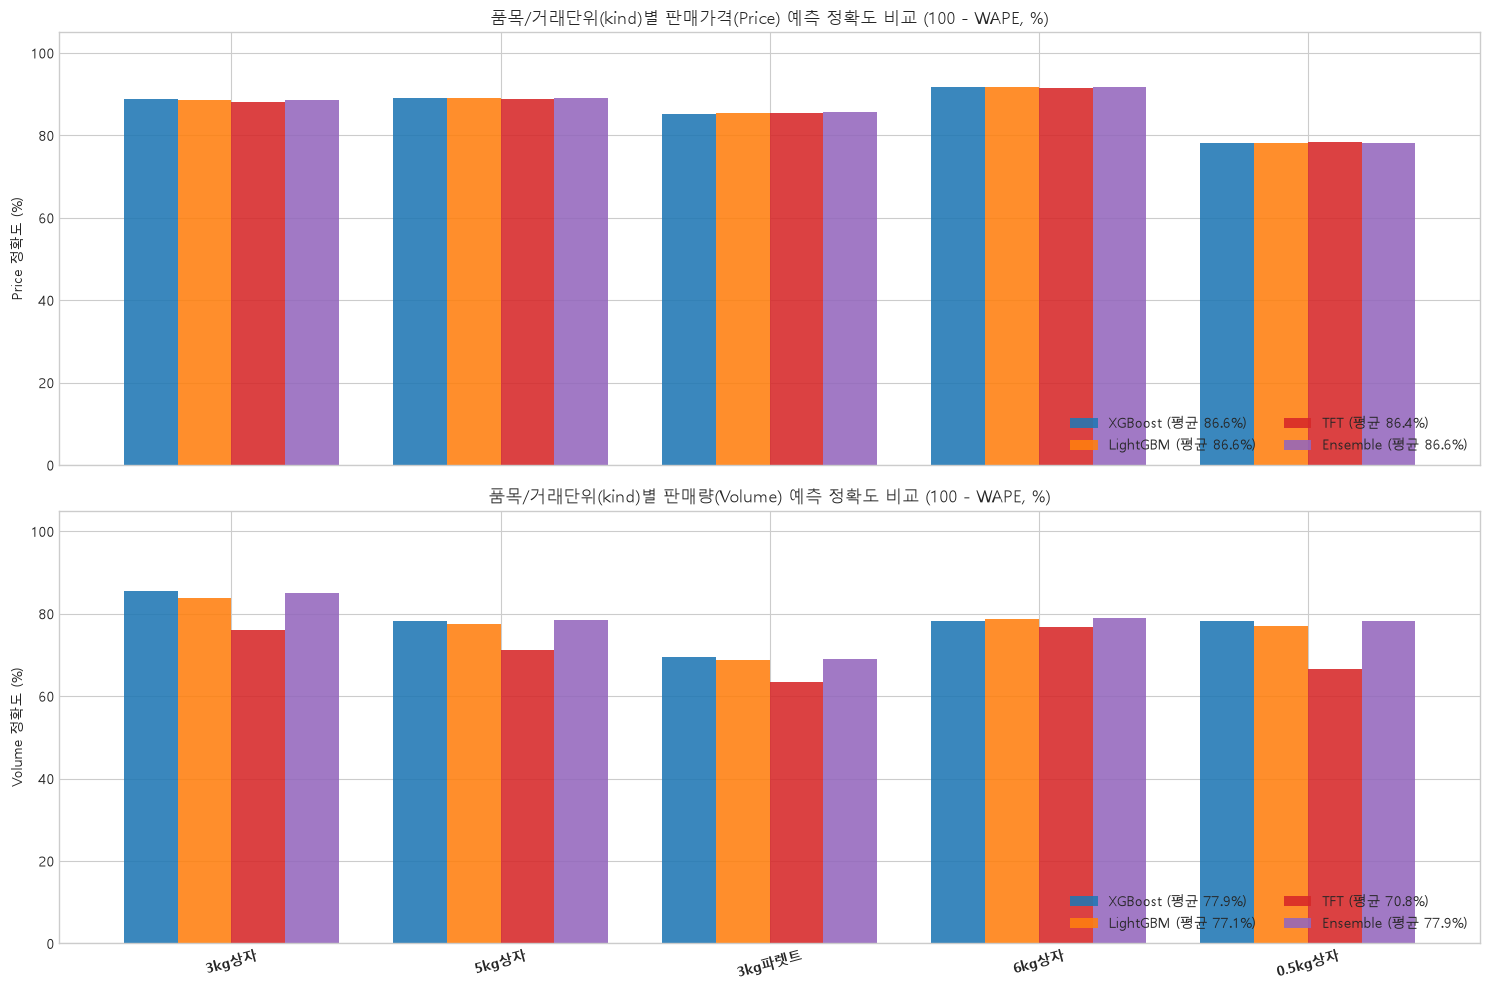

In [10]:
summary_df = pd.DataFrame(metrics_summary)
model_order = ['XGBoost', 'LightGBM', 'TFT', 'Ensemble']

# 1) 모델별 전체 kind 평균 정확도 요약표
overall_rows = []
for m in model_order:
    p_sub = summary_df[(summary_df['Model'] == m) & (summary_df['Target'] == 'price')]
    v_sub = summary_df[(summary_df['Model'] == m) & (summary_df['Target'] == 'volume')]
    overall_rows.append({
        'Model': m,
        '판매가격(price) 평균 정확도(%)': round(p_sub['정확도(100-WAPE, %)'].mean(), 2),
        '판매가격(price) 평균 대칭정확도(%)': round(p_sub['대칭정확도(100-sMAPE, %)'].mean(), 2),
        '판매가격(price) 평균 방향정확도(%)': round(p_sub['방향정확도(DA, %)'].mean(), 2),
        '판매량(volume) 평균 정확도(%)': round(v_sub['정확도(100-WAPE, %)'].mean(), 2),
        '판매량(volume) 평균 대칭정확도(%)': round(v_sub['대칭정확도(100-sMAPE, %)'].mean(), 2),
        '판매량(volume) 평균 방향정확도(%)': round(v_sub['방향정확도(DA, %)'].mean(), 2),
    })
overall_acc_df = pd.DataFrame(overall_rows)
print("=== [1] 모델별 전체 kind 평균 가격(price) 및 판매량(volume) 예측 정확도 비교 ===")
display(overall_acc_df)

# 2) kind(거래단위)별 × 모델별 판매가격(Price) 정확도 비교 피벗 테이블
price_acc_pivot = (
    summary_df[summary_df['Target'] == 'price']
    .pivot(index='kind', columns='Model', values='정확도(100-WAPE, %)')
    .loc[TARGET_KINDS, model_order]
)
price_acc_pivot['최고정확도_모델'] = price_acc_pivot[model_order].idxmax(axis=1)
price_acc_pivot['최고정확도(%)'] = price_acc_pivot[model_order].max(axis=1)
print("\n=== [2] 품목/거래단위(kind)별 판매가격(Price) 예측 정확도(100-WAPE, %) 비교 ===")
display(price_acc_pivot)

# 3) kind(거래단위)별 × 모델별 판매량(Volume) 정확도 비교 피벗 테이블
vol_acc_pivot = (
    summary_df[summary_df['Target'] == 'volume']
    .pivot(index='kind', columns='Model', values='정확도(100-WAPE, %)')
    .loc[TARGET_KINDS, model_order]
)
vol_acc_pivot['최고정확도_모델'] = vol_acc_pivot[model_order].idxmax(axis=1)
vol_acc_pivot['최고정확도(%)'] = vol_acc_pivot[model_order].max(axis=1)
print("\n=== [3] 품목/거래단위(kind)별 판매량(Volume) 예측 정확도(100-WAPE, %) 비교 ===")
display(vol_acc_pivot)

# 4) kind별 판매가격 및 판매량 정확도 시각화
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
x = np.arange(len(TARGET_KINDS))
w = 0.20
colors = {'XGBoost': 'tab:blue', 'LightGBM': 'tab:orange', 'TFT': 'tab:red', 'Ensemble': 'tab:purple'}

for idx, m in enumerate(model_order):
    offset = (idx - 1.5) * w
    p_vals = price_acc_pivot[m].values
    v_vals = vol_acc_pivot[m].values
    axes[0].bar(x + offset, p_vals, w, label=f"{m} (평균 {p_vals.mean():.1f}%)", color=colors[m], alpha=0.88)
    axes[1].bar(x + offset, v_vals, w, label=f"{m} (평균 {v_vals.mean():.1f}%)", color=colors[m], alpha=0.88)

axes[0].set_title('품목/거래단위(kind)별 판매가격(Price) 예측 정확도 비교 (100 - WAPE, %)')
axes[0].set_ylabel('Price 정확도 (%)')
axes[0].set_ylim(0, 105)
axes[0].legend(loc='lower right', ncol=2)

axes[1].set_title('품목/거래단위(kind)별 판매량(Volume) 예측 정확도 비교 (100 - WAPE, %)')
axes[1].set_ylabel('Volume 정확도 (%)')
axes[1].set_ylim(0, 105)
axes[1].set_xticks(x)
axes[1].set_xticklabels(TARGET_KINDS, rotation=15, fontweight='bold')
axes[1].legend(loc='lower right', ncol=2)

plt.tight_layout()
plt.show()

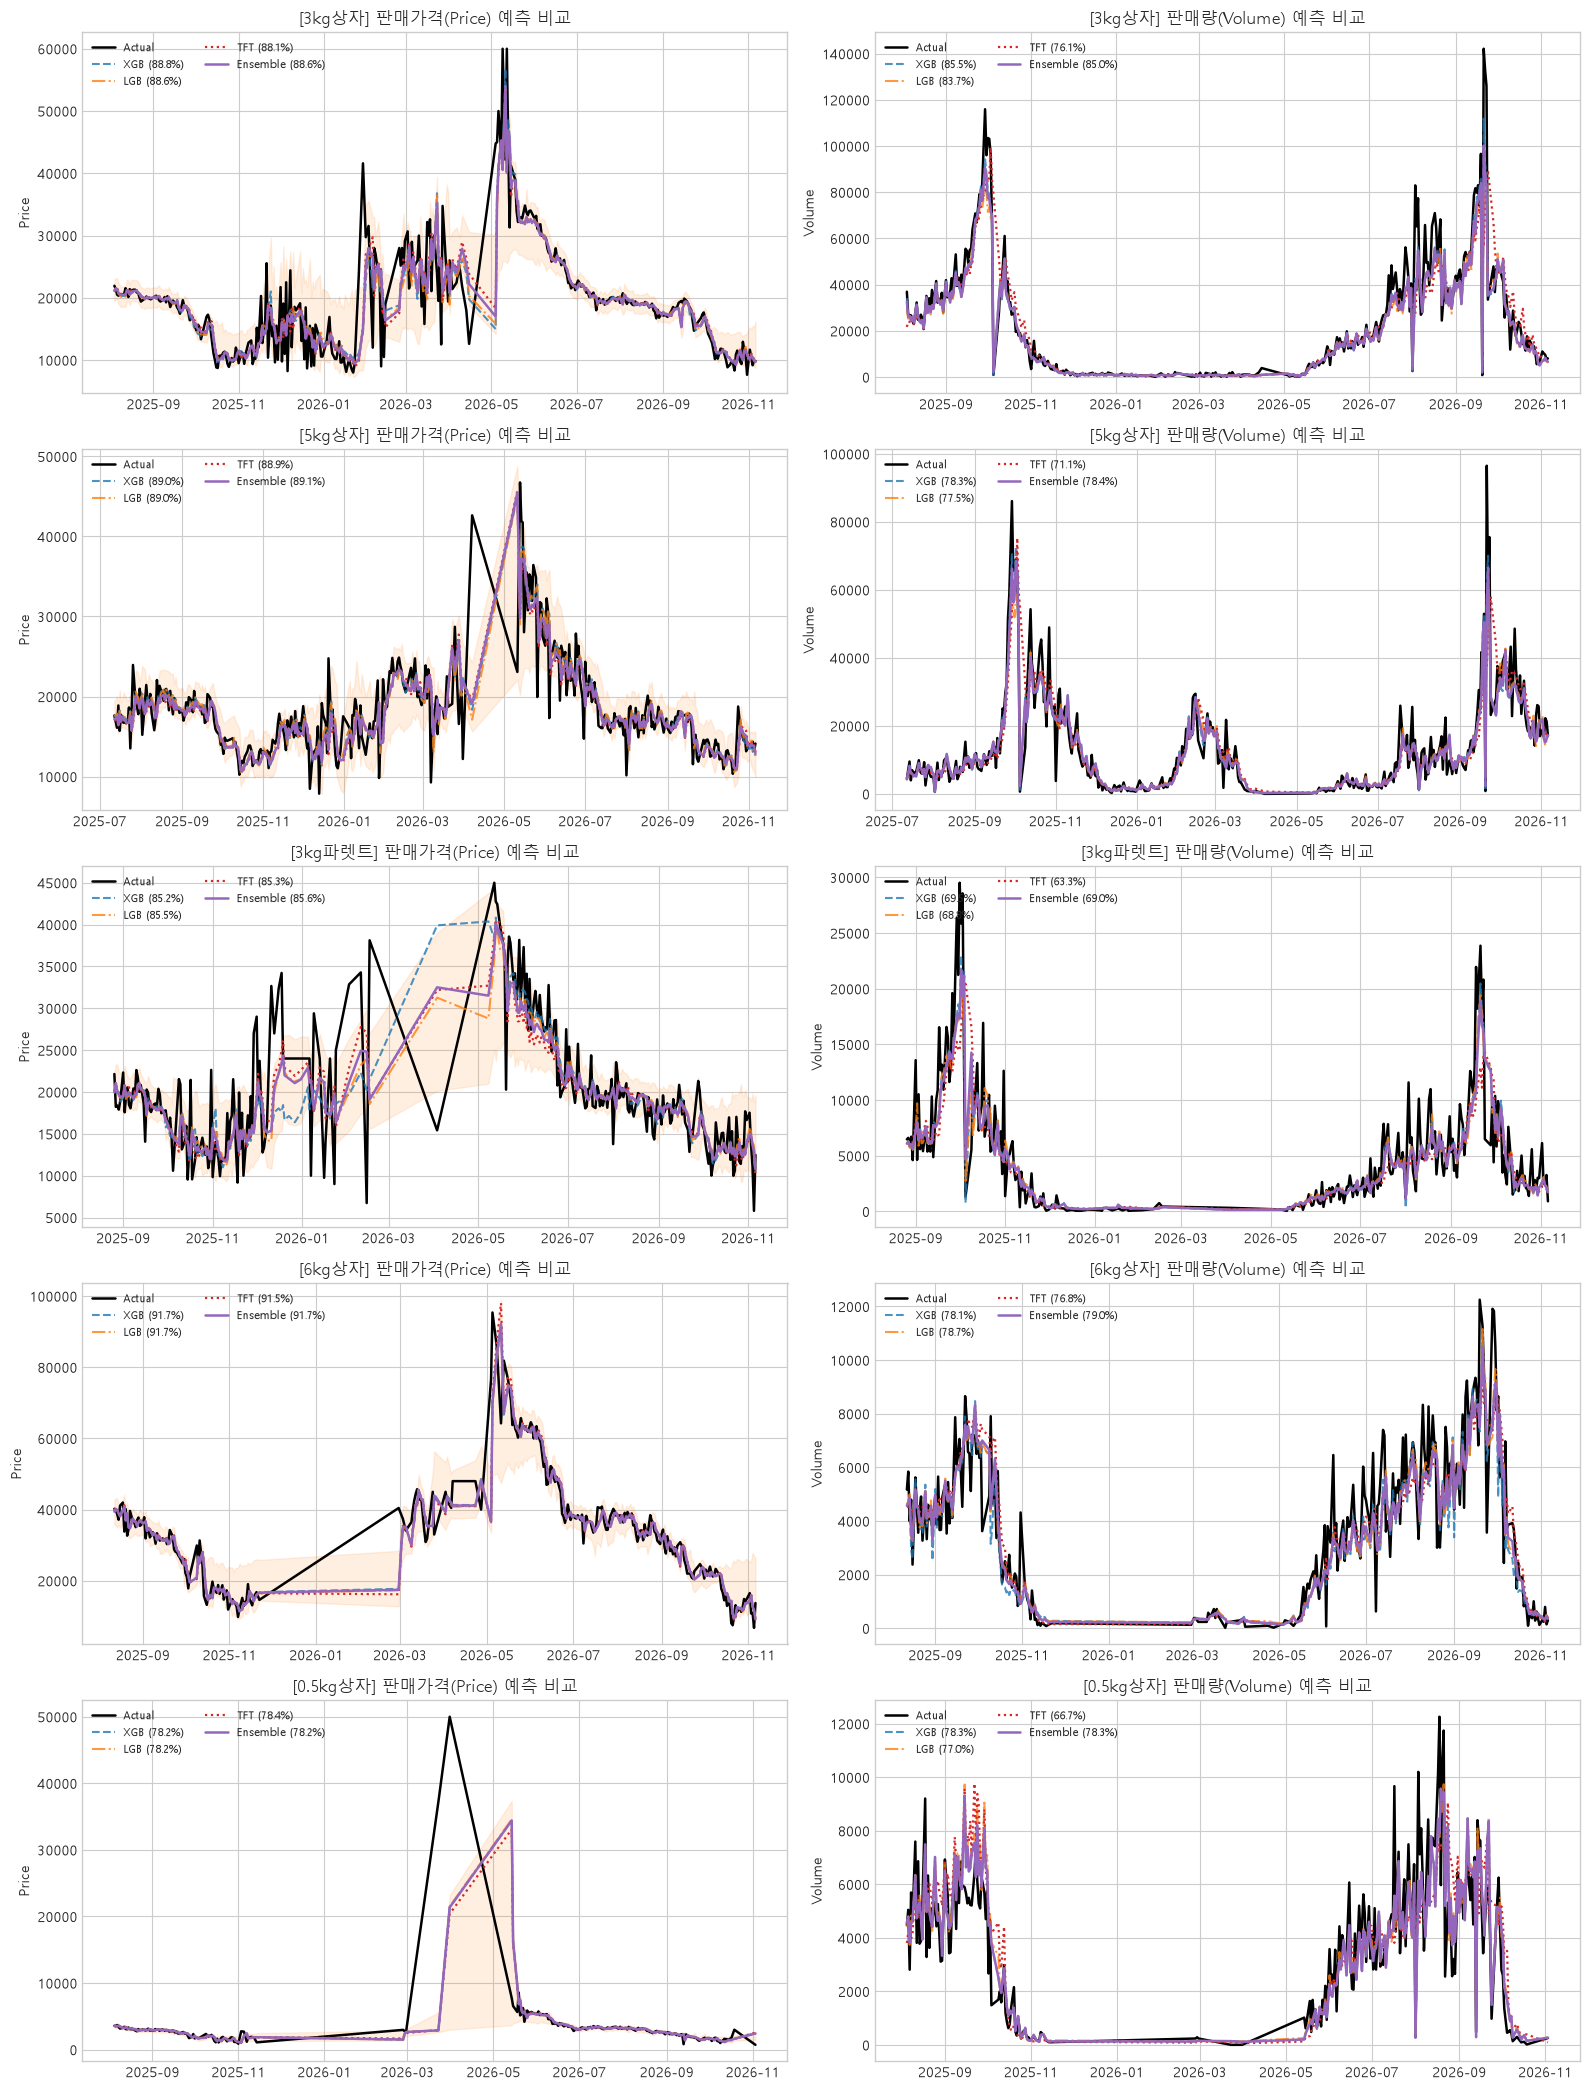

=== 품목/거래단위(kind)별 최근 예측 결과 샘플 ===


,kind,date,actual_price,xgb_price,lgb_price,tft_price,ens_price,actual_volume,xgb_volume,lgb_volume,tft_volume,ens_volume
0,3kg상자,2026-11-05,9841.29,9962.395353,9903.601147,9991.257918,9979.712892,7830,7004.591064,6836.510361,7838.591200,6954.166853
1,3kg상자,2026-11-06,9868.41,9595.318211,9656.399336,9786.149560,9709.817020,8037,6944.341797,6086.301381,7553.922065,6686.929672
2,5kg상자,2026-11-05,13226.75,13311.551011,13343.940448,14088.663024,13777.818219,21340,16345.622070,15756.176075,17712.864770,16168.788272
3,5kg상자,2026-11-06,14122.75,12616.742474,12575.586893,13010.456622,12852.970963,17130,17353.837402,17011.342009,18274.241467,17251.088784
4,3kg파렛트,2026-11-05,5800.65,12557.043750,13597.226503,12308.222507,12977.606630,3273,2218.564392,2255.200068,1981.359619,2171.123437
5,3kg파렛트,2026-11-06,12483.54,10959.137109,11191.705946,10109.846174,10735.705154,912,1654.965668,1703.001194,2065.194702,1737.011475
6,6kg상자,2026-11-05,6768.00,11877.254347,11723.724797,11575.968813,11801.066929,150,482.015717,500.131570,397.970996,462.237056
7,6kg상자,2026-11-06,13732.02,9310.415373,9149.100838,8406.087576,9171.588233,300,384.986382,412.845252,315.679132,372.551868
8,0.5kg상자,2026-10-19,3000.00,1638.135973,1623.065048,1624.195109,1638.135973,18,151.067875,161.878835,393.432301,151.067875
9,0.5kg상자,2026-11-03,725.02,2427.610949,2459.898277,2570.561130,2427.610949,258,268.757828,280.275294,96.422379,268.757828


In [11]:
all_results_list = []
for k in TARGET_KINDS:
    te_df = kind_datasets[k]['test']
    preds = predictions_by_kind[k]
    k_res = pd.DataFrame({
        'kind': k,
        'date': te_df['date'].values,
        'actual_price': te_df['price'].values,
        'xgb_price': preds['xgb_price'],
        'lgb_price': preds['lgb_price'],
        'tft_price': preds['tft_price'],
        'ens_price': preds['ens_price'],
        'actual_volume': te_df['volume'].values,
        'xgb_volume': preds['xgb_volume'],
        'lgb_volume': preds['lgb_volume'],
        'tft_volume': preds['tft_volume'],
        'ens_volume': preds['ens_volume'],
    })
    all_results_list.append(k_res)

results_df = pd.concat(all_results_list, ignore_index=True)

plot_kinds = TARGET_KINDS[:5]
fig, axes = plt.subplots(len(plot_kinds), 2, figsize=(16, 4.2 * len(plot_kinds)), squeeze=False)

for row_idx, k in enumerate(plot_kinds):
    k_res = results_df[results_df['kind'] == k]
    preds = predictions_by_kind[k]
    
    p_acc_xgb = price_acc_pivot.loc[k, 'XGBoost']
    p_acc_lgb = price_acc_pivot.loc[k, 'LightGBM']
    p_acc_tft = price_acc_pivot.loc[k, 'TFT']
    p_acc_ens = price_acc_pivot.loc[k, 'Ensemble']
    
    v_acc_xgb = vol_acc_pivot.loc[k, 'XGBoost']
    v_acc_lgb = vol_acc_pivot.loc[k, 'LightGBM']
    v_acc_tft = vol_acc_pivot.loc[k, 'TFT']
    v_acc_ens = vol_acc_pivot.loc[k, 'Ensemble']
    
    ax_p = axes[row_idx, 0]
    ax_p.plot(k_res['date'], k_res['actual_price'], label='Actual', color='black', linewidth=1.8)
    ax_p.plot(k_res['date'], k_res['xgb_price'], label=f'XGB ({p_acc_xgb:.1f}%)', linestyle='--', color='tab:blue', alpha=0.8)
    ax_p.plot(k_res['date'], k_res['lgb_price'], label=f'LGB ({p_acc_lgb:.1f}%)', linestyle='-.', color='tab:orange', alpha=0.8)
    ax_p.plot(k_res['date'], k_res['tft_price'], label=f'TFT ({p_acc_tft:.1f}%)', linestyle=':', color='tab:red', linewidth=1.6)
    ax_p.plot(k_res['date'], k_res['ens_price'], label=f'Ensemble ({p_acc_ens:.1f}%)', linestyle='-', color='tab:purple', linewidth=1.8)
    ax_p.fill_between(k_res['date'], preds['lgb_price_q10'], preds['lgb_price_q90'], color='tab:orange', alpha=0.12)
    ax_p.set_title(f'[{k}] 판매가격(Price) 예측 비교')
    ax_p.set_ylabel('Price')
    ax_p.legend(loc='upper left', fontsize=8, ncol=2)
    
    ax_v = axes[row_idx, 1]
    ax_v.plot(k_res['date'], k_res['actual_volume'], label='Actual', color='black', linewidth=1.8)
    ax_v.plot(k_res['date'], k_res['xgb_volume'], label=f'XGB ({v_acc_xgb:.1f}%)', linestyle='--', color='tab:blue', alpha=0.8)
    ax_v.plot(k_res['date'], k_res['lgb_volume'], label=f'LGB ({v_acc_lgb:.1f}%)', linestyle='-.', color='tab:orange', alpha=0.8)
    ax_v.plot(k_res['date'], k_res['tft_volume'], label=f'TFT ({v_acc_tft:.1f}%)', linestyle=':', color='tab:red', linewidth=1.6)
    ax_v.plot(k_res['date'], k_res['ens_volume'], label=f'Ensemble ({v_acc_ens:.1f}%)', linestyle='-', color='tab:purple', linewidth=1.8)
    ax_v.set_title(f'[{k}] 판매량(Volume) 예측 비교')
    ax_v.set_ylabel('Volume')
    ax_v.legend(loc='upper left', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

print("=== 품목/거래단위(kind)별 최근 예측 결과 샘플 ===")
display(results_df.groupby('kind').tail(2).reset_index(drop=True))


## 9. 모델 해석: 변수 중요도 (Feature Importance & TFT Variable Selection)
- XGBoost / LightGBM의 상위 중요 피처와 TFT의 Variable Selection 가중치를 시각화합니다.

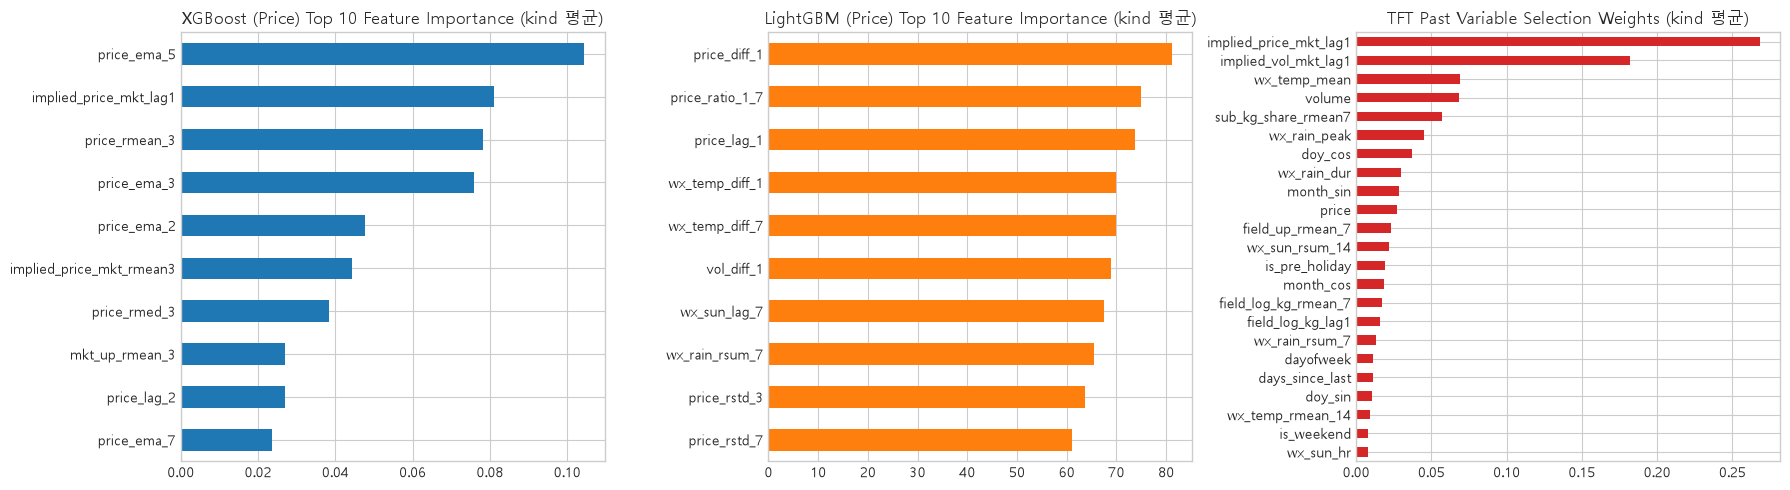

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. XGBoost Price 전체 kind 평균 상위 10개 피처 중요도
xgb_imp_avg = np.mean([m['price_model'].feature_importances_ for m in xgb_models_by_kind.values()], axis=0)
xgb_feat_names = xgb_models_by_kind[TARGET_KINDS[0]]['price_features']
pd.Series(xgb_imp_avg, index=xgb_feat_names).sort_values(ascending=True).tail(10).plot(kind='barh', ax=axes[0], color='tab:blue')
axes[0].set_title('XGBoost (Price) Top 10 Feature Importance (kind 평균)')

# 2. LightGBM Price 전체 kind 평균 상위 10개 피처 중요도
lgb_imp_avg = np.mean([m['price_model'].feature_importances_ for m in lgb_models_by_kind.values()], axis=0)
lgb_feat_names = lgb_models_by_kind[TARGET_KINDS[0]]['price_features']
pd.Series(lgb_imp_avg, index=lgb_feat_names).sort_values(ascending=True).tail(10).plot(kind='barh', ax=axes[1], color='tab:orange')
axes[1].set_title('LightGBM (Price) Top 10 Feature Importance (kind 평균)')

# 3. TFT 과거 입력 변수 선택 가중치 (전체 kind 평균)
tft_imp_avg = np.mean([m['past_weights'] for m in tft_models_by_kind.values()], axis=0)
pd.Series(tft_imp_avg, index=past_cols).sort_values(ascending=True).plot(kind='barh', ax=axes[2], color='tab:red')
axes[2].set_title('TFT Past Variable Selection Weights (kind 평균)')

plt.tight_layout()
plt.show()

## 10. 3대 예측 품종(`하우스감귤`, `조생귤`, `천혜향`)별 및 품종별 상위 5대 판매단위(`Transaction Unit`) 가격·판매량 예측
- 요청하신 기준에 따라 **예측은 `하우스감귤`, `조생귤`, `천혜향` 3개 품종에 대해서만 수행**하고, 나머지 19개 품종(`기타감귤`, `비가림감귤`, `레드향`, `황금향`, `극조생감귤`, `온주` 등)은 **해당일의 전체 물량 데이터(`field_all_citrus_today_kg`, `field_other_citrus_today_kg` 등)로만** 사용합니다.
- **1) 3대 품종(`하우스감귤`, `조생귤`, `천혜향`) 통합 일별 가격·물량 예측 정확도**와 **2) 각 품종별 판매량 상위 5가지 판매단위(`하우스감귤 Top 5`, `조생귤 Top 5`, `천혜향 Top 5`) 예측 정확도**를 함께 산출합니다.

=== [1] 3대 예측 품종(하우스감귤 / 조생귤 / 천혜향) 판매가격(Price) 예측 정확도 (%) ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
하우스감귤,91.09,90.98,90.90,91.06,XGBoost,91.09
조생귤,86.60,87.40,87.02,87.24,LightGBM,87.40
천혜향,90.84,90.74,90.42,90.71,XGBoost,90.84



=== [2] 3대 예측 품종(하우스감귤 / 조생귤 / 천혜향) 판매량(Volume) 예측 정확도 (%) ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
하우스감귤,91.88,92.46,75.70,92.30,LightGBM,92.46
조생귤,86.95,84.81,78.27,86.01,XGBoost,86.95
천혜향,93.87,91.47,75.47,92.70,XGBoost,93.87



=== [3] 3대 품종(하우스감귤 / 조생귤 / 천혜향) × 각 상위 5대 판매단위(총 15개) 판매가격(Price) 예측 정확도 (%) ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
품종_판매단위,,,,,,
하우스감귤 | 3kg상자,88.78,88.60,88.13,88.57,XGBoost,88.78
하우스감귤 | 5kg상자,88.98,88.95,88.87,89.07,Ensemble,89.07
하우스감귤 | 3kg파렛트,85.24,85.53,85.35,85.63,Ensemble,85.63
하우스감귤 | 6kg상자,91.72,91.73,91.47,91.71,LightGBM,91.73
하우스감귤 | 0.5kg상자,78.22,78.16,78.38,78.22,TFT,78.38
조생귤 | 5kg상자,98.11,97.60,84.47,97.60,XGBoost,98.11
조생귤 | 10kg상자,94.16,94.97,87.66,94.72,LightGBM,94.97
조생귤 | 5kg파렛트,97.82,97.39,85.88,97.82,XGBoost,97.82
조생귤 | 5kg.,96.27,95.82,86.81,95.97,XGBoost,96.27



=== [4] 3대 품종(하우스감귤 / 조생귤 / 천혜향) × 각 상위 5대 판매단위(총 15개) 판매량(Volume) 예측 정확도 (%) ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
품종_판매단위,,,,,,
하우스감귤 | 3kg상자,85.45,83.69,76.09,85.04,XGBoost,85.45
하우스감귤 | 5kg상자,78.29,77.46,71.14,78.40,Ensemble,78.40
하우스감귤 | 3kg파렛트,69.52,68.83,63.32,68.97,XGBoost,69.52
하우스감귤 | 6kg상자,78.13,78.71,76.77,78.96,Ensemble,78.96
하우스감귤 | 0.5kg상자,78.35,77.05,66.66,78.35,XGBoost,78.35
조생귤 | 5kg상자,84.42,80.89,78.74,84.42,XGBoost,84.42
조생귤 | 10kg상자,59.50,59.47,55.05,59.62,Ensemble,59.62
조생귤 | 5kg파렛트,75.84,75.49,76.44,75.84,TFT,76.44
조생귤 | 5kg.,71.27,70.63,71.10,71.32,Ensemble,71.32


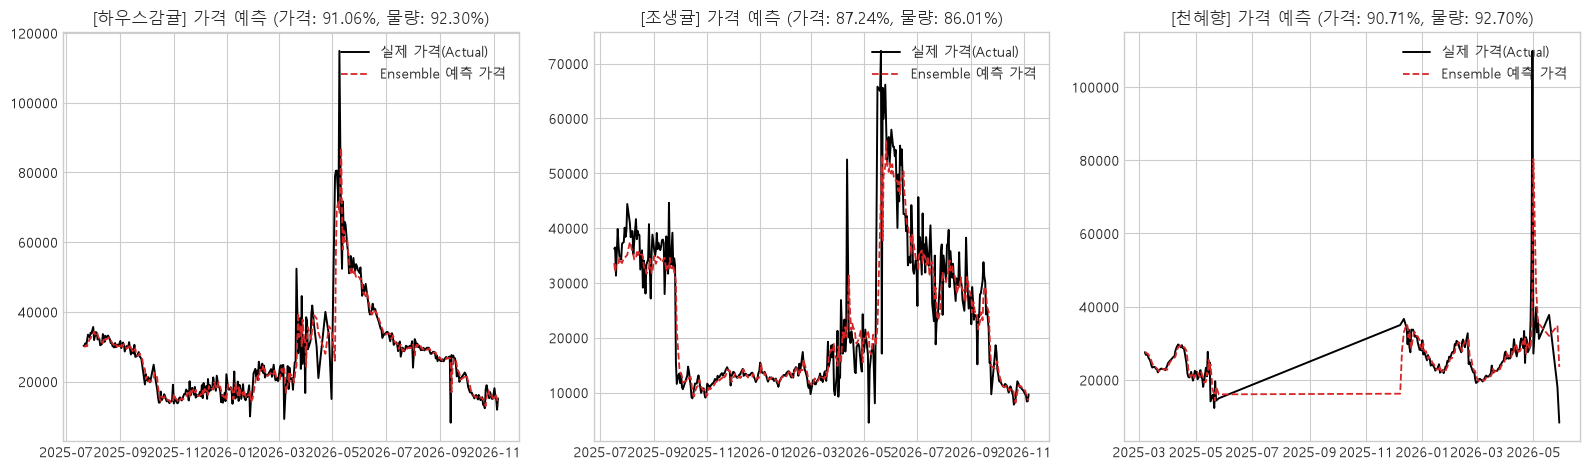

In [13]:
# 1) 3대 예측 품종(하우스감귤, 조생귤, 천혜향) 일별 가격·판매량 예측 (나머지 품종은 전체 물량 피처로만 활용)
TARGET_TYPES = ['하우스감귤', '조생귤', '천혜향']

type_daily = field_raw_df.groupby(['date', 'type'], as_index=False).agg(
    volume=('volume', 'sum'),
    total_price=('total price', 'sum'),
    total_kg=('total_kg', 'sum')
).sort_values(['type', 'date']).reset_index(drop=True)

type_daily['unit_price'] = type_daily['total_price'] / (type_daily['total_kg'] + 1e-8)
type_daily['price'] = (type_daily['unit_price'] * 5.0).round(2)

# 전체 감귤 시장(22개 전 품종 해당일 전체 물량) 결합
all_mkt = f_daily_mkt = field_daily_df[['date', 'raw_all_citrus_kg', 'raw_field_total_rev', 'raw_field_unit_price']].copy()
all_mkt = all_mkt.rename(columns={
    'raw_all_citrus_kg': 'mkt_total_kg',
    'raw_field_total_rev': 'mkt_total_rev',
    'raw_field_unit_price': 'mkt_unit_price'
}).sort_values('date').reset_index(drop=True)
all_mkt['mkt_active_kinds'] = 3

for lag in [1, 2, 3, 7, 14]:
    all_mkt[f'mkt_prev_kg_{lag}'] = all_mkt['mkt_total_kg'].shift(lag)
    all_mkt[f'mkt_prev_up_{lag}'] = all_mkt['mkt_unit_price'].shift(lag)
for w in [3, 7, 14]:
    all_mkt[f'mkt_up_rmean_{w}'] = all_mkt['mkt_unit_price'].shift(1).rolling(w).mean()
    all_mkt[f'mkt_kg_rmean_{w}'] = all_mkt['mkt_total_kg'].shift(1).rolling(w).mean()
    all_mkt[f'mkt_kg_rmed_{w}'] = all_mkt['mkt_total_kg'].shift(1).rolling(w).median()
all_mkt = all_mkt.bfill()

type_daily = type_daily.merge(all_mkt, on='date', how='left')
type_daily['vol_share'] = type_daily['total_kg'] / (type_daily['mkt_total_kg'] + 1e-8)
type_daily['up_ratio'] = type_daily['unit_price'] / (type_daily['mkt_unit_price'] + 1e-8)
type_daily['weight_kg'] = 5.0
type_daily = type_daily.merge(wx_daily_df, on='date', how='left')
field_merge_cols = ['date'] + [c for c in field_daily_df.columns if c.startswith('field_')]
type_daily = type_daily.merge(field_daily_df[field_merge_cols], on='date', how='left')
type_daily['kind'] = type_daily['type']

type_datasets = {}
type_metrics = []

for idx_t, t_name in enumerate(TARGET_TYPES):
    t_raw = type_daily[type_daily['type'] == t_name].copy()
    t_feat = create_time_series_features_single_kind(t_raw, kind_id=idx_t)
    n_t = len(t_feat)
    tr_end = int(n_t * 0.70)
    va_end = int(n_t * 0.85)
    type_datasets[t_name] = {
        'feat': t_feat,
        'train': t_feat.iloc[:tr_end].copy(),
        'val': t_feat.iloc[tr_end:va_end].copy(),
        'test': t_feat.iloc[va_end:].copy(),
        'train_end': tr_end,
        'val_end': va_end
    }

type_num_cols = type_datasets[TARGET_TYPES[0]]['feat'].select_dtypes(include=[np.number]).columns
type_feat_cols = [c for c in type_num_cols if c not in exclude_cols]

type_global_tr = pd.concat([type_datasets[t]['train'] for t in TARGET_TYPES], ignore_index=True)
type_global_va = pd.concat([type_datasets[t]['val'] for t in TARGET_TYPES], ignore_index=True)

xgb_t_g_vol = xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror', random_state=42, early_stopping_rounds=40, **XGB_DEVICE_PARAMS)
xgb_t_g_vol.fit(type_global_tr[type_feat_cols], np.log1p(type_global_tr['volume']), eval_set=[(type_global_va[type_feat_cols], np.log1p(type_global_va['volume']))], verbose=False)
xgb_t_g_prc = xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror', random_state=42, early_stopping_rounds=40, **XGB_DEVICE_PARAMS)
xgb_t_g_prc.fit(type_global_tr[type_feat_cols], np.log1p(type_global_tr['price']), eval_set=[(type_global_va[type_feat_cols], np.log1p(type_global_va['price']))], verbose=False)

lgb_t_g_vol = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31, subsample=0.8, colsample_bytree=0.8, objective='regression_l1', random_state=42, verbose=-1, **LGB_DEVICE_PARAMS)
lgb_t_g_vol.fit(type_global_tr[type_feat_cols], np.log1p(type_global_tr['volume']), eval_set=[(type_global_va[type_feat_cols], np.log1p(type_global_va['volume']))], callbacks=[lgb.early_stopping(40, verbose=False)])
lgb_t_g_prc = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31, subsample=0.8, colsample_bytree=0.8, objective='regression_l1', random_state=42, verbose=-1, **LGB_DEVICE_PARAMS)
lgb_t_g_prc.fit(type_global_tr[type_feat_cols], np.log1p(type_global_tr['price']), eval_set=[(type_global_va[type_feat_cols], np.log1p(type_global_va['price']))], callbacks=[lgb.early_stopping(40, verbose=False)])

type_preds = {}
type_models_dict = {}
for t_name in TARGET_TYPES:
    ds = type_datasets[t_name]
    tr_df, va_df, te_df = ds['train'], ds['val'], ds['test']
    X_tr, X_va, X_te = tr_df[type_feat_cols], va_df[type_feat_cols], te_df[type_feat_cols]
    
    xl_v = xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror', random_state=42, early_stopping_rounds=30, **XGB_DEVICE_PARAMS)
    xl_v.fit(X_tr, np.log1p(tr_df['volume']), eval_set=[(X_va, np.log1p(va_df['volume']))], verbose=False)
    xl_p = xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror', random_state=42, early_stopping_rounds=30, **XGB_DEVICE_PARAMS)
    xl_p.fit(X_tr, np.log1p(tr_df['price']), eval_set=[(X_va, np.log1p(va_df['price']))], verbose=False)
    
    xv_te, xv_va, _ = optimize_blend_weights(va_df['volume'].values, [np.expm1(xl_v.predict(X_va)), np.expm1(xgb_t_g_vol.predict(X_va)), va_df['vol_ema_3'].values, va_df['vol_rmed_7'].values], [np.expm1(xl_v.predict(X_te)), np.expm1(xgb_t_g_vol.predict(X_te)), te_df['vol_ema_3'].values, te_df['vol_rmed_7'].values], step=0.2)
    xp_te, xp_va, _ = optimize_blend_weights(va_df['price'].values, [np.expm1(xl_p.predict(X_va)), np.expm1(xgb_t_g_prc.predict(X_va)), va_df['price_ema_2'].values], [np.expm1(xl_p.predict(X_te)), np.expm1(xgb_t_g_prc.predict(X_te)), te_df['price_ema_2'].values], step=0.2)
    
    ll_v = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, colsample_bytree=0.8, objective='regression_l1', random_state=42, verbose=-1, **LGB_DEVICE_PARAMS)
    ll_v.fit(X_tr, np.log1p(tr_df['volume']), eval_set=[(X_va, np.log1p(va_df['volume']))], callbacks=[lgb.early_stopping(30, verbose=False)])
    ll_p = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, colsample_bytree=0.8, objective='regression_l1', random_state=42, verbose=-1, **LGB_DEVICE_PARAMS)
    ll_p.fit(X_tr, np.log1p(tr_df['price']), eval_set=[(X_va, np.log1p(va_df['price']))], callbacks=[lgb.early_stopping(30, verbose=False)])
    
    lv_te, lv_va, _ = optimize_blend_weights(va_df['volume'].values, [np.expm1(ll_v.predict(X_va)), np.expm1(lgb_t_g_vol.predict(X_va)), va_df['vol_ema_3'].values, va_df['vol_rmed_7'].values], [np.expm1(ll_v.predict(X_te)), np.expm1(lgb_t_g_vol.predict(X_te)), te_df['vol_ema_3'].values, te_df['vol_rmed_7'].values], step=0.2)
    lp_te, lp_va, _ = optimize_blend_weights(va_df['price'].values, [np.expm1(ll_p.predict(X_va)), np.expm1(lgb_t_g_prc.predict(X_va)), va_df['price_ema_2'].values], [np.expm1(ll_p.predict(X_te)), np.expm1(lgb_t_g_prc.predict(X_te)), te_df['price_ema_2'].values], step=0.2)
    
    k_feat = ds['feat'].copy()
    tr_end, va_end = ds['train_end'], ds['val_end']
    tft_df = k_feat[['date'] + list(dict.fromkeys(past_cols + future_cols))].copy()
    for c in ['price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1', 'field_up_rmean_7']:
        tft_df[c] = np.log1p(np.maximum(0.0, tft_df[c]))
    ps, fs, ts = StandardScaler(), StandardScaler(), StandardScaler()
    p_sc = np.vstack([ps.fit_transform(tft_df.iloc[:tr_end][past_cols]), ps.transform(tft_df.iloc[tr_end:][past_cols])])
    f_sc = np.vstack([fs.fit_transform(tft_df.iloc[:tr_end][future_cols]), fs.transform(tft_df.iloc[tr_end:][future_cols])])
    t_sc = np.vstack([ts.fit_transform(tft_df.iloc[:tr_end][['price', 'volume']]), ts.transform(tft_df.iloc[tr_end:][['price', 'volume']])])
    seq_len = min(10, max(3, tr_end // 5))
    tr_ds_t = TFTSequenceDataset(p_sc, f_sc, t_sc, list(range(seq_len, tr_end)), seq_len)
    va_ds_t = TFTSequenceDataset(p_sc, f_sc, t_sc, list(range(tr_end, va_end)), seq_len)
    te_ds_t = TFTSequenceDataset(p_sc, f_sc, t_sc, list(range(va_end, len(tft_df))), seq_len)
    tr_ld = [(tr_ds_t.x_past[i:i+256], tr_ds_t.x_future[i:i+256], tr_ds_t.y[i:i+256]) for i in range(0, len(tr_ds_t), 256)]
    va_ld = [(va_ds_t.x_past[i:i+256], va_ds_t.x_future[i:i+256], va_ds_t.y[i:i+256]) for i in range(0, len(va_ds_t), 256)]
    te_ld = [(te_ds_t.x_past[i:i+256], te_ds_t.x_future[i:i+256], te_ds_t.y[i:i+256]) for i in range(0, len(te_ds_t), 256)]
    torch.manual_seed(42)
    t_mod = TemporalFusionTransformerModel(len(past_cols), len(future_cols), 64, 4, 0.1, 2).to(device)
    opt = torch.optim.AdamW(t_mod.parameters(), lr=1e-3, weight_decay=1e-4)
    crit = nn.L1Loss()
    for _ in range(15):
        t_mod.train()
        for xp_b, xf_b, yb in tr_ld:
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                loss = crit(t_mod(xp_b, xf_b)[0], yb)
            loss.backward()
            opt.step()
    t_mod.eval()
    vp_l, tp_l = [], []
    with torch.no_grad():
        for xp_b, xf_b, _ in va_ld:
            vp_l.append(t_mod(xp_b.to(device), xf_b.to(device))[0].cpu().numpy())
        for xp_b, xf_b, _ in te_ld:
            tp_l.append(t_mod(xp_b.to(device), xf_b.to(device))[0].cpu().numpy())
    v_inv = np.expm1(ts.inverse_transform(np.vstack(vp_l)))
    t_inv = np.expm1(ts.inverse_transform(np.vstack(tp_l)))
    tv_te, tv_va, _ = optimize_blend_weights(va_df['volume'].values, [v_inv[:, 1], va_df['vol_ema_3'].values, va_df['vol_rmed_7'].values], [t_inv[:, 1], te_df['vol_ema_3'].values, te_df['vol_rmed_7'].values], step=0.25)
    tp_te, tp_va, _ = optimize_blend_weights(va_df['price'].values, [v_inv[:, 0], va_df['price_ema_2'].values], [t_inv[:, 0], te_df['price_ema_2'].values], step=0.25)
    
    ev_te, _, _ = optimize_blend_weights(va_df['volume'].values, [xv_va, lv_va, tv_va], [xv_te, lv_te, tv_te], step=0.1)
    ep_te, _, _ = optimize_blend_weights(va_df['price'].values, [xp_va, lp_va, tp_va], [xp_te, lp_te, tp_te], step=0.1)
    
    type_models_dict[t_name] = {
        'xgb_vol': xl_v, 'xgb_price': xl_p,
        'lgb_vol': ll_v, 'lgb_price': ll_p,
        'tft_state_dict': {k_s: v_s.detach().cpu() for k_s, v_s in t_mod.state_dict().items()},
        'past_scaler': ps, 'future_scaler': fs, 'target_scaler': ts,
        'seq_len': seq_len, 'feature_cols': type_feat_cols
    }
    type_preds[t_name] = {
        'test': te_df,
        'xgb_price': xp_te, 'lgb_price': lp_te, 'tft_price': tp_te, 'ens_price': ep_te,
        'xgb_vol': xv_te, 'lgb_vol': lv_te, 'tft_vol': tv_te, 'ens_vol': ev_te
    }
    for m_label, p_p, p_v in [('XGBoost', xp_te, xv_te), ('LightGBM', lp_te, lv_te), ('TFT', tp_te, tv_te), ('Ensemble', ep_te, ev_te)]:
        record_metric(type_metrics, evaluate_predictions(te_df['price'], p_p, m_label, 'price', kind_name=t_name))
        record_metric(type_metrics, evaluate_predictions(te_df['volume'], p_v, m_label, 'volume', kind_name=t_name))

type_summary_df = pd.DataFrame(type_metrics)
model_order_t = ['XGBoost', 'LightGBM', 'TFT', 'Ensemble']
type_price_pivot = type_summary_df[type_summary_df['Target'] == 'price'].pivot(index='kind', columns='Model', values='정확도(100-WAPE, %)')[model_order_t].loc[TARGET_TYPES]
type_vol_pivot = type_summary_df[type_summary_df['Target'] == 'volume'].pivot(index='kind', columns='Model', values='정확도(100-WAPE, %)')[model_order_t].loc[TARGET_TYPES]
type_price_pivot['최고정확도_모델'] = type_price_pivot[model_order_t].idxmax(axis=1)
type_price_pivot['최고정확도(%)'] = type_price_pivot[model_order_t].max(axis=1)
type_vol_pivot['최고정확도_모델'] = type_vol_pivot[model_order_t].idxmax(axis=1)
type_vol_pivot['최고정확도(%)'] = type_vol_pivot[model_order_t].max(axis=1)

print("=== [1] 3대 예측 품종(하우스감귤 / 조생귤 / 천혜향) 판매가격(Price) 예측 정확도 (%) ===")
display(type_price_pivot)
print("\n=== [2] 3대 예측 품종(하우스감귤 / 조생귤 / 천혜향) 판매량(Volume) 예측 정확도 (%) ===")
display(type_vol_pivot)

# 2) 조생귤 및 천혜향 각각의 판매량 상위 5가지 판매단위(Transaction Unit)별 예측 (하우스감귤 상위 5가지는 섹션 8과 통합 비교)
var_unit_metrics = []
vu_preds = {}
vu_models_dict = {}
for k_h in TARGET_KINDS:
    k_sub_h = results_df[results_df['kind'] == k_h].copy()
    vu_preds[f"하우스감귤 | {k_h}"] = k_sub_h
for m in metrics_summary:
    m_copy = dict(m)
    m_copy['품종_판매단위'] = f"하우스감귤 | {m['kind']}"
    var_unit_metrics.append(m_copy)

for v_name in ['조생귤', '천혜향']:
    v_sub = field_raw_df[field_raw_df['type'] == v_name].copy()
    v_sub['is_pallet'] = v_sub['kind'].str.contains('파렛트').astype(int)
    v_sub['unit_price'] = v_sub['unitprice']
    v_sub = v_sub.merge(all_mkt, on='date', how='left')
    v_sub['vol_share'] = v_sub['total_kg'] / (v_sub['mkt_total_kg'] + 1e-8)
    v_sub['up_ratio'] = v_sub['unit_price'] / (v_sub['mkt_unit_price'] + 1e-8)
    v_sub = v_sub.merge(wx_daily_df, on='date', how='left')
    v_sub = v_sub.merge(field_daily_df[field_merge_cols], on='date', how='left')
    
    top5_u = v_sub.groupby('kind')['volume'].sum().sort_values(ascending=False).head(5).index.tolist()
    for u_idx, u_name in enumerate(top5_u):
        u_raw = v_sub[v_sub['kind'] == u_name].copy()
        u_feat = create_time_series_features_single_kind(u_raw, kind_id=u_idx)
        n_u = len(u_feat)
        tr_e, va_e = int(n_u * 0.70), int(n_u * 0.85)
        tr_u, va_u, te_u = u_feat.iloc[:tr_e], u_feat.iloc[tr_e:va_e], u_feat.iloc[va_e:]
        u_cols = [c for c in u_feat.select_dtypes(include=[np.number]).columns if c not in exclude_cols]
        
        # XGBoost
        xm_v = xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror', random_state=42, early_stopping_rounds=30, **XGB_DEVICE_PARAMS)
        xm_v.fit(tr_u[u_cols], np.log1p(tr_u['volume']), eval_set=[(va_u[u_cols], np.log1p(va_u['volume']))], verbose=False)
        xm_p = xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror', random_state=42, early_stopping_rounds=30, **XGB_DEVICE_PARAMS)
        xm_p.fit(tr_u[u_cols], np.log1p(tr_u['price']), eval_set=[(va_u[u_cols], np.log1p(va_u['price']))], verbose=False)
        uv_x_te, uv_x_va, _ = optimize_blend_weights(va_u['volume'].values, [np.expm1(xm_v.predict(va_u[u_cols])), va_u['vol_ema_3'].values, va_u['vol_rmed_7'].values], [np.expm1(xm_v.predict(te_u[u_cols])), te_u['vol_ema_3'].values, te_u['vol_rmed_7'].values], step=0.25)
        up_x_te, up_x_va, _ = optimize_blend_weights(va_u['price'].values, [np.expm1(xm_p.predict(va_u[u_cols])), va_u['price_ema_2'].values], [np.expm1(xm_p.predict(te_u[u_cols])), te_u['price_ema_2'].values], step=0.25)
        
        # LightGBM
        lm_v = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, colsample_bytree=0.8, objective='regression_l1', random_state=42, verbose=-1, **LGB_DEVICE_PARAMS)
        lm_v.fit(tr_u[u_cols], np.log1p(tr_u['volume']), eval_set=[(va_u[u_cols], np.log1p(va_u['volume']))], callbacks=[lgb.early_stopping(30, verbose=False)])
        lm_p = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, colsample_bytree=0.8, objective='regression_l1', random_state=42, verbose=-1, **LGB_DEVICE_PARAMS)
        lm_p.fit(tr_u[u_cols], np.log1p(tr_u['price']), eval_set=[(va_u[u_cols], np.log1p(va_u['price']))], callbacks=[lgb.early_stopping(30, verbose=False)])
        uv_l_te, uv_l_va, _ = optimize_blend_weights(va_u['volume'].values, [np.expm1(lm_v.predict(va_u[u_cols])), va_u['vol_ema_3'].values, va_u['vol_rmed_7'].values], [np.expm1(lm_v.predict(te_u[u_cols])), te_u['vol_ema_3'].values, te_u['vol_rmed_7'].values], step=0.25)
        up_l_te, up_l_va, _ = optimize_blend_weights(va_u['price'].values, [np.expm1(lm_p.predict(va_u[u_cols])), va_u['price_ema_2'].values], [np.expm1(lm_p.predict(te_u[u_cols])), te_u['price_ema_2'].values], step=0.25)
        
        # TFT
        tft_u_df = u_feat[['date'] + list(dict.fromkeys(past_cols + future_cols))].copy()
        for c in ['price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1', 'field_up_rmean_7']:
            tft_u_df[c] = np.log1p(np.maximum(0.0, tft_u_df[c]))
        ps_u, fs_u, ts_u = StandardScaler(), StandardScaler(), StandardScaler()
        p_sc_u = np.vstack([ps_u.fit_transform(tft_u_df.iloc[:tr_e][past_cols]), ps_u.transform(tft_u_df.iloc[tr_e:][past_cols])])
        f_sc_u = np.vstack([fs_u.fit_transform(tft_u_df.iloc[:tr_e][future_cols]), fs_u.transform(tft_u_df.iloc[tr_e:][future_cols])])
        t_sc_u = np.vstack([ts_u.fit_transform(tft_u_df.iloc[:tr_e][['price', 'volume']]), ts_u.transform(tft_u_df.iloc[tr_e:][['price', 'volume']])])
        sq_u = min(10, max(3, tr_e // 5))
        tr_du = TFTSequenceDataset(p_sc_u, f_sc_u, t_sc_u, list(range(sq_u, tr_e)), sq_u)
        va_du = TFTSequenceDataset(p_sc_u, f_sc_u, t_sc_u, list(range(tr_e, va_e)), sq_u)
        te_du = TFTSequenceDataset(p_sc_u, f_sc_u, t_sc_u, list(range(va_e, len(tft_u_df))), sq_u)
        torch.manual_seed(42)
        tm_u = TemporalFusionTransformerModel(len(past_cols), len(future_cols), 64, 4, 0.1, 2).to(device)
        opt_u = torch.optim.AdamW(tm_u.parameters(), lr=1e-3, weight_decay=1e-4)
        crit_u = nn.L1Loss()
        for _ in range(12):
            tm_u.train()
            for i in range(0, len(tr_du), 256):
                opt_u.zero_grad(set_to_none=True)
                with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                    loss = crit_u(tm_u(tr_du.x_past[i:i+256], tr_du.x_future[i:i+256])[0], tr_du.y[i:i+256])
                loss.backward()
                opt_u.step()
        tm_u.eval()
        with torch.no_grad():
            v_inv_u = np.expm1(ts_u.inverse_transform(tm_u(va_du.x_past, va_du.x_future)[0].cpu().numpy()))
            t_inv_u = np.expm1(ts_u.inverse_transform(tm_u(te_du.x_past, te_du.x_future)[0].cpu().numpy()))
        uv_t_te, uv_t_va, _ = optimize_blend_weights(va_u['volume'].values, [v_inv_u[:, 1], va_u['vol_ema_3'].values, va_u['vol_rmed_7'].values], [t_inv_u[:, 1], te_u['vol_ema_3'].values, te_u['vol_rmed_7'].values], step=0.25)
        up_t_te, up_t_va, _ = optimize_blend_weights(va_u['price'].values, [v_inv_u[:, 0], va_u['price_ema_2'].values], [t_inv_u[:, 0], te_u['price_ema_2'].values], step=0.25)
        
        uv_e_te, _, _ = optimize_blend_weights(va_u['volume'].values, [uv_x_va, uv_l_va, uv_t_va], [uv_x_te, uv_l_te, uv_t_te], step=0.1)
        up_e_te, _, _ = optimize_blend_weights(va_u['price'].values, [up_x_va, up_l_va, up_t_va], [up_x_te, up_l_te, up_t_te], step=0.1)
        
        label_vu = f"{v_name} | {u_name}"
        vu_models_dict[label_vu] = {
            'xgb_vol': xm_v, 'xgb_price': xm_p,
            'lgb_vol': lm_v, 'lgb_price': lm_p,
            'tft_state_dict': {k_s: v_s.detach().cpu() for k_s, v_s in tm_u.state_dict().items()},
            'past_scaler': ps_u, 'future_scaler': fs_u, 'target_scaler': ts_u,
            'seq_len': sq_u, 'feature_cols': u_cols
        }
        vu_preds[label_vu] = pd.DataFrame({
            'date': te_u['date'].values,
            'actual_price': te_u['price'].values,
            'xgb_price': up_x_te,
            'lgb_price': up_l_te,
            'tft_price': up_t_te,
            'ens_price': up_e_te,
            'actual_volume': te_u['volume'].values,
            'xgb_volume': uv_x_te,
            'lgb_volume': uv_l_te,
            'tft_volume': uv_t_te,
            'ens_volume': uv_e_te,
        })
        for m_lbl, pp, pv in [('XGBoost', up_x_te, uv_x_te), ('LightGBM', up_l_te, uv_l_te), ('TFT', up_t_te, uv_t_te), ('Ensemble', up_e_te, uv_e_te)]:
            mp = evaluate_predictions(te_u['price'], pp, m_lbl, 'price', kind_name=label_vu)
            mv = evaluate_predictions(te_u['volume'], pv, m_lbl, 'volume', kind_name=label_vu)
            mp['품종_판매단위'] = label_vu
            mv['품종_판매단위'] = label_vu
            var_unit_metrics.append(mp)
            var_unit_metrics.append(mv)

vu_df = pd.DataFrame(var_unit_metrics)
vu_order = vu_df['품종_판매단위'].drop_duplicates().tolist()
vu_price_pivot = vu_df[vu_df['Target'] == 'price'].pivot(index='품종_판매단위', columns='Model', values='정확도(100-WAPE, %)')[model_order_t].loc[vu_order]
vu_price_pivot['최고정확도_모델'] = vu_price_pivot[model_order_t].idxmax(axis=1)
vu_price_pivot['최고정확도(%)'] = vu_price_pivot[model_order_t].max(axis=1)

vu_vol_pivot = vu_df[vu_df['Target'] == 'volume'].pivot(index='품종_판매단위', columns='Model', values='정확도(100-WAPE, %)')[model_order_t].loc[vu_order]
vu_vol_pivot['최고정확도_모델'] = vu_vol_pivot[model_order_t].idxmax(axis=1)
vu_vol_pivot['최고정확도(%)'] = vu_vol_pivot[model_order_t].max(axis=1)

print("\n=== [3] 3대 품종(하우스감귤 / 조생귤 / 천혜향) × 각 상위 5대 판매단위(총 15개) 판매가격(Price) 예측 정확도 (%) ===")
display(vu_price_pivot)
print("\n=== [4] 3대 품종(하우스감귤 / 조생귤 / 천혜향) × 각 상위 5대 판매단위(총 15개) 판매량(Volume) 예측 정확도 (%) ===")
display(vu_vol_pivot)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for idx_t, t_name in enumerate(TARGET_TYPES):
    ax = axes[idx_t]
    te_df = type_preds[t_name]['test']
    ax.plot(te_df['date'], te_df['price'], label='실제 가격(Actual)', color='black', linewidth=1.4)
    ax.plot(te_df['date'], type_preds[t_name]['ens_price'], label='Ensemble 예측 가격', color='tab:red', linestyle='--', linewidth=1.3)
    acc_p = type_price_pivot.loc[t_name, 'Ensemble']
    acc_v = type_vol_pivot.loc[t_name, 'Ensemble']
    ax.set_title(f"[{t_name}] 가격 예측 (가격: {acc_p:.2f}%, 물량: {acc_v:.2f}%)")
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 11. 특정 기준 날짜로부터 향후 1주일(7일)간 최고 가격·물량 Top-2 및 최저 물량 Bottom-2 날짜 예측·정확도 평가
- **목표**: 특정 기준 날짜($t_0$)로부터 향후 일주일($[t_0, t_0 + 6]$, 7일간) 내에:
  1. **판매가격(`price`)이 가장 높을 것으로 예상되는 2개의 날짜 (최고 가격 Top-2)**
  2. **판매량(`volume`)이 가장 많을 것으로 예상되는 2개의 날짜 (최고 물량 Top-2)**
  3. **판매량(`volume`)이 가장 적을 것으로 예상되는 2개의 날짜 (최저 물량 Bottom-2)**
  를 각각 예측하고 비율 기반 정확도를 평가합니다.
- **최고 가격·최고 물량 (Top-2) 정확도 산출 기준**:
  1. **2개의 날짜가 실제 최고 2개 날짜와 모두 일치하는 경우**: **100.0%** (`100%`)
  2. **1개 일치 또는 불일치하는 경우**: 일치한 날짜는 **100.0%**, 불일치한 선택 날짜($\hat{d}_k$)는 대응하는 실제 최고 날짜($d^*_k$)의 실제값 대비 선택한 날짜의 실제값 비율($\frac{y(\hat{d}_k)}{y(d^*_k)} \times 100\%$)로 계산하여 평균합니다:

$$\mathrm{Accuracy}_{\mathrm{Top2}}(\%) = \frac{1}{2}\sum_{k=1}^{2} \mathrm{Score}_k, \qquad \mathrm{Score}_k = \begin{cases} 100\% & \text{if } \hat{d}_k \in \{d^*_1, d^*_2\} \\ \min\left(100\%, \frac{y(\hat{d}_k)}{y(d^*_k)} \times 100\right) & \text{otherwise} \end{cases}$$

- **최저 물량 2일 (Bottom-2 Lowest Volume) 정확도 산출 기준**:
  1. **2개의 날짜가 실제 최저 물량 2개 날짜($d^{\min}_1, d^{\min}_2$)와 모두 일치하는 경우**: **100.0%** (`100%`)
  2. **1개 일치 또는 불일치하는 경우**: 일치한 날짜는 **100.0%**, 불일치한 선택 날짜($\hat{d}^{\min}_k$)는 실제 최저 날짜의 물량($y(d^{\min}_k)$)과 선택한 날짜의 실제 물량($y(\hat{d}^{\min}_k)$)의 비율($\frac{\min(y(d^{\min}_k), y(\hat{d}^{\min}_k))}{\max(y(d^{\min}_k), y(\hat{d}^{\min}_k))} \times 100\% = \frac{y(d^{\min}_k)}{y(\hat{d}^{\min}_k)} \times 100\%$)로 계산하여 2개 날짜의 평균으로 산출합니다:

$$\mathrm{Accuracy}_{\mathrm{Bottom2}}(\%) = \frac{1}{2}\sum_{k=1}^{2} \mathrm{Score}^{\min}_k, \qquad \mathrm{Score}^{\min}_k = \begin{cases} 100\% & \text{if } \hat{d}^{\min}_k \in \{d^{\min}_1, d^{\min}_2\} \\ \frac{\min\left(y(d^{\min}_k), y(\hat{d}^{\min}_k)\right)}{\max\left(y(d^{\min}_k), y(\hat{d}^{\min}_k)\right)} \times 100 & \text{otherwise} \end{cases}$$

=== [특정 기준 날짜(2026-10-26) 기준 상위 5대 판매단위(kind)별 향후 1주일간 최고 가격/물량 Top-2 및 최저 물량 Bottom-2 날짜 예측 정확도] ===


,구분(품목),기준날짜,주간범위,모델,실제_최고가격_2일,예측_최고가격_2일(선택일실제가),가격_일치여부,가격_Top2_정확도(%),실제_최고물량_2일,예측_최고물량_2일(선택일실제물량),최고물량_일치여부,최고물량_Top2_정확도(%),실제_최저물량_2일,예측_최저물량_2일(선택일실제물량),최저물량_일치여부,최저물량_Bottom2_정확도(%),최저물량_2일합산비율(%)
0,3kg상자,2026-10-26,10-26~10-31 (6거래일),XGBoost,"2026-10-28 (12,947원), 2026-10-29 (11,669원)","2026-10-26 (9,782원), 2026-10-30 (10,518원)","불일치 → 비율(75.6%, 90.1%)",82.84,"2026-10-27 (13,326), 2026-10-26 (13,176)","2026-10-26 (13,176), 2026-10-28 (10,200)",1개 일치 + 1개 비율(76.5%),88.27,"2026-10-29 (5,571), 2026-10-31 (6,639)","2026-10-31 (6,639), 2026-10-30 (7,230)",1개 일치 + 1개 비율(77.1%),88.53,88.04
1,3kg상자,2026-10-26,10-26~10-31 (6거래일),LightGBM,"2026-10-28 (12,947원), 2026-10-29 (11,669원)","2026-10-30 (10,518원), 2026-10-26 (9,782원)","불일치 → 비율(81.2%, 83.8%)",82.53,"2026-10-27 (13,326), 2026-10-26 (13,176)","2026-10-26 (13,176), 2026-10-28 (10,200)",1개 일치 + 1개 비율(76.5%),88.27,"2026-10-29 (5,571), 2026-10-31 (6,639)","2026-10-31 (6,639), 2026-10-30 (7,230)",1개 일치 + 1개 비율(77.1%),88.53,88.04
2,3kg상자,2026-10-26,10-26~10-31 (6거래일),TFT,"2026-10-28 (12,947원), 2026-10-29 (11,669원)","2026-10-29 (11,669원), 2026-10-30 (10,518원)",1개 일치 + 1개 비율(81.2%),90.62,"2026-10-27 (13,326), 2026-10-26 (13,176)","2026-10-26 (13,176), 2026-10-27 (13,326)",2개 모두 일치 (100%),100.00,"2026-10-29 (5,571), 2026-10-31 (6,639)","2026-10-31 (6,639), 2026-10-30 (7,230)",1개 일치 + 1개 비율(77.1%),88.53,88.04
3,3kg상자,2026-10-26,10-26~10-31 (6거래일),Ensemble,"2026-10-28 (12,947원), 2026-10-29 (11,669원)","2026-10-26 (9,782원), 2026-10-30 (10,518원)","불일치 → 비율(75.6%, 90.1%)",82.84,"2026-10-27 (13,326), 2026-10-26 (13,176)","2026-10-26 (13,176), 2026-10-28 (10,200)",1개 일치 + 1개 비율(76.5%),88.27,"2026-10-29 (5,571), 2026-10-31 (6,639)","2026-10-31 (6,639), 2026-10-30 (7,230)",1개 일치 + 1개 비율(77.1%),88.53,88.04
4,5kg상자,2026-10-26,10-26~10-31 (6거래일),XGBoost,"2026-10-26 (15,541원), 2026-10-27 (15,254원)","2026-10-26 (15,541원), 2026-10-27 (15,254원)",2개 모두 일치 (100%),100.00,"2026-10-29 (26,120), 2026-10-30 (25,745)","2026-10-31 (16,980), 2026-10-26 (18,940)","불일치 → 비율(65.0%, 73.6%)",69.29,"2026-10-27 (14,200), 2026-10-31 (16,980)","2026-10-28 (22,970), 2026-10-29 (26,120)","불일치 → 비율(61.8%, 65.0%)",63.41,63.52
5,5kg상자,2026-10-26,10-26~10-31 (6거래일),LightGBM,"2026-10-26 (15,541원), 2026-10-27 (15,254원)","2026-10-26 (15,541원), 2026-10-27 (15,254원)",2개 모두 일치 (100%),100.00,"2026-10-29 (26,120), 2026-10-30 (25,745)","2026-10-26 (18,940), 2026-10-30 (25,745)",1개 일치 + 1개 비율(72.5%),86.26,"2026-10-27 (14,200), 2026-10-31 (16,980)","2026-10-28 (22,970), 2026-10-27 (14,200)",1개 일치 + 1개 비율(73.9%),86.96,83.88
6,5kg상자,2026-10-26,10-26~10-31 (6거래일),TFT,"2026-10-26 (15,541원), 2026-10-27 (15,254원)","2026-10-27 (15,254원), 2026-10-28 (14,516원)",1개 일치 + 1개 비율(93.4%),96.70,"2026-10-29 (26,120), 2026-10-30 (25,745)","2026-10-26 (18,940), 2026-10-31 (16,980)","불일치 → 비율(72.5%, 66.0%)",69.23,"2026-10-27 (14,200), 2026-10-31 (16,980)","2026-10-28 (22,970), 2026-10-29 (26,120)","불일치 → 비율(61.8%, 65.0%)",63.41,63.52
7,5kg상자,2026-10-26,10-26~10-31 (6거래일),Ensemble,"2026-10-26 (15,541원), 2026-10-27 (15,254원)","2026-10-26 (15,541원), 2026-10-27 (15,254원)",2개 모두 일치 (100%),100.00,"2026-10-29 (26,120), 2026-10-30 (25,745)","2026-10-26 (18,940), 2026-10-31 (16,980)","불일치 → 비율(72.5%, 66.0%)",69.23,"2026-10-27 (14,200), 2026-10-31 (16,980)","2026-10-28 (22,970), 2026-10-29 (26,120)","불일치 → 비율(61.8%, 65.0%)",63.41,63.52
8,3kg파렛트,2026-10-26,10-26~10-31 (6거래일),XGBoost,"2026-10-30 (17,691원), 2026-10-31 (16,648원)","2026-10-31 (16,648원), 2026-10-26 (11,686원)",1개 일치 + 1개 비율(66.1%),83.03,"2026-10-26 (5,589), 2026-10-30 (3,030)","2026-10-29 (2,016), 2026-10-28 (2,826)","불일치 → 비율(36.1%, 93.3%)",64.67,"2026-10-29 (2,016), 2026-10-27 (2,193)","2026-10-30 (3,030), 2026-10-27 (2,193)",1개 일치 + 1개 비율(66.5%),83.27,80.59
9,3kg파렛트,2026-10-26,10-26~10-31 (6거래일),LightGBM,"2026-10-30 (17,691원), 2026-10-31 (16,648원)","2026-10-26 (11,686원), 2026-10-31 (16,648원)",1개 일치 + 1개 비율(66.1%),83.03,"2026-10-26 (5,589), 2026-10-30 (3,030)","2026-10-28 (2,826), 2026-10-29 (2,01


=== [특정 기준 날짜(2026-10-26) 이후 1주일간 일별 상세 예측 및 최고/최저 순위 (3kg상자)] ===


,date,actual_price,ens_price,xgb_price,actual_volume,ens_volume,xgb_volume,실제가격_최고순위,Ensemble예측가격_최고순위,실제물량_최고순위,Ensemble예측물량_최고순위,실제물량_최저순위,Ensemble예측물량_최저순위
0,2026-10-26,9781.83,11569.482896,11479.977681,13176,14003.830231,13984.797852,4,1,2,1,5,6
1,2026-10-27,9364.77,10455.342177,10145.386124,13326,10112.595135,10150.659424,5,5,1,4,6,3
2,2026-10-28,12946.77,10084.371734,9938.691106,10200,11192.100193,11426.854004,1,6,3,2,4,5
3,2026-10-29,11668.98,11548.023632,11196.211220,5571,10144.137643,10274.951660,2,3,6,3,1,4
4,2026-10-30,10517.64,11554.829813,11354.197848,7230,5648.679608,5602.801270,3,2,4,5,3,2
5,2026-10-31,7639.86,10866.711411,10984.318245,6639,5046.730403,4956.451172,6,4,5,6,2,1



=== [전체 거래단위(kind) 평균: 향후 1주일간 최고 가격/물량 Top-2 및 최저 물량 Bottom-2 날짜 예측 정확도 요약] ===


,Model,가격_Top2_비율정확도_평균,가격_Top2_2일합산비율_평균,가격_1개이상_날짜일치율,가격_2개모두_완전일치율,최고물량_Top2_비율정확도_평균,최고물량_Top2_2일합산비율_평균,최고물량_1개이상_날짜일치율,최고물량_2개모두_완전일치율,최저물량_Bottom2_비율정확도_평균,최저물량_Bottom2_2일합산비율_평균,최저물량_1개이상_날짜일치율,최저물량_2개모두_완전일치율
0,XGBoost,91.34,91.18,66.71,11.50,86.33,86.05,84.95,27.18,85.51,82.16,83.11,25.69
1,LightGBM,91.02,90.80,64.73,11.36,86.15,85.87,84.95,26.19,85.32,82.24,81.97,26.83
2,TFT,90.65,90.49,61.96,10.43,78.65,78.08,72.39,11.21,77.48,73.26,69.06,12.35
3,Ensemble,90.86,90.67,64.02,10.79,86.61,86.35,85.52,27.61,85.66,82.40,83.18,26.12


... (10 outputs left out)


=== [3대 예측 품종(하우스감귤/조생귤/천혜향)별 향후 1주일간 최저 판매량(Volume) Bottom-2 날짜 예측 정확도 (%)] ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
하우스감귤,98.19,98.36,73.95,98.30,LightGBM,98.36
조생귤,98.33,98.43,71.62,98.45,Ensemble,98.45
천혜향,98.93,98.71,81.20,99.07,Ensemble,99.07



=== [3대 품종 × 각 상위 5대 판매단위(총 15개 조합)별 향후 1주일간 최저 판매량(Volume) Bottom-2 날짜 예측 정확도 (%)] ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
하우스감귤 | 3kg상자,88.76,89.03,79.06,89.27,Ensemble,89.27
하우스감귤 | 5kg상자,87.46,86.44,76.76,87.57,Ensemble,87.57
하우스감귤 | 3kg파렛트,78.77,78.39,75.47,78.90,Ensemble,78.90
하우스감귤 | 6kg상자,82.37,82.11,79.73,82.23,XGBoost,82.37
하우스감귤 | 0.5kg상자,90.21,91.03,78.00,90.21,LightGBM,91.03
조생귤 | 5kg상자,88.98,82.63,75.24,88.98,XGBoost,88.98
조생귤 | 10kg상자,76.44,74.42,63.41,76.14,XGBoost,76.44
조생귤 | 5kg파렛트,77.47,75.58,72.25,77.47,XGBoost,77.47
조생귤 | 5kg.,79.81,78.40,70.28,79.62,XGBoost,79.81


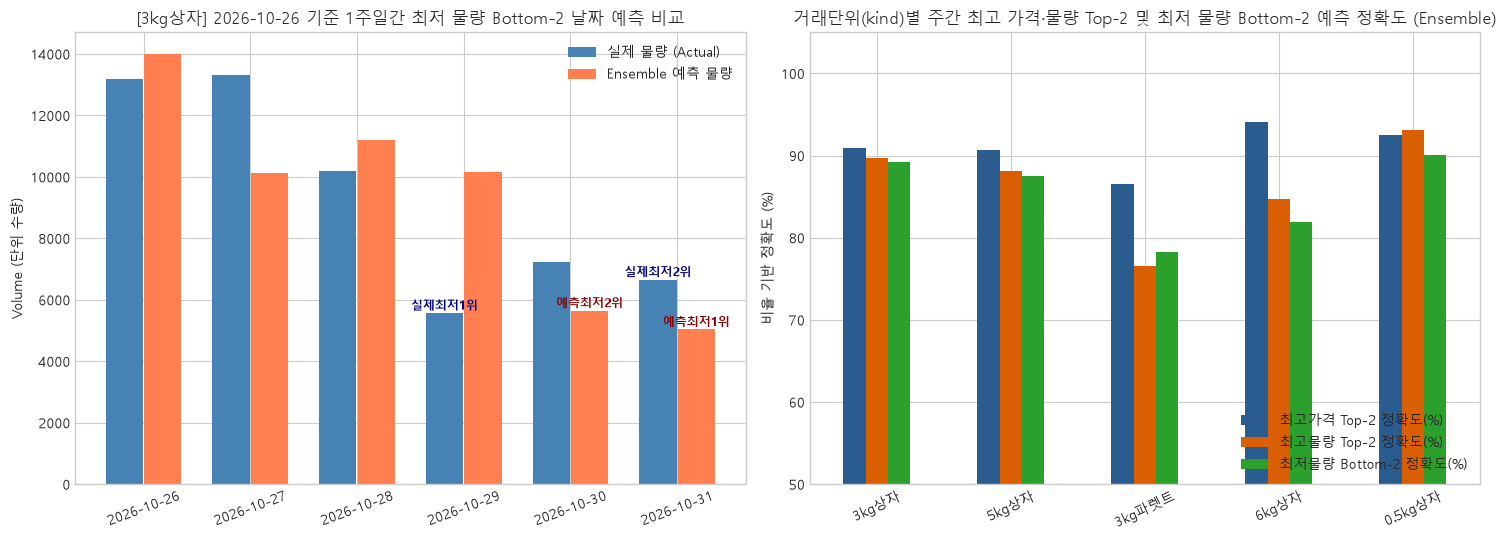

In [14]:
def evaluate_single_week_top2(w_df, actual_col, pred_col):
    '''
    주어진 1주일(7일) 윈도우 데이터프레임(w_df)에서:
    - 실제값(actual_col) 기준 상위 2개 날짜(true_d1, true_d2)
    - 예측값(pred_col) 기준 상위 2개 날짜(pred_d1, pred_d2)
    를 구하고, 일치 시 100%, 불일치 시 (선택한 날짜의 실제값 / 실제 최고 날짜의 실제값) 비율로 정확도를 계산합니다.
    '''
    w = w_df.sort_values('date').reset_index(drop=True)
    true_top2 = w.sort_values([actual_col, 'date'], ascending=[False, True]).iloc[:2]
    pred_top2 = w.sort_values([pred_col, 'date'], ascending=[False, True]).iloc[:2]
    
    true_dates = list(true_top2['date'])
    pred_dates = list(pred_top2['date'])
    
    true_set = set(true_dates)
    pred_set = set(pred_dates)
    matched_dates = true_set & pred_set
    match_count = len(matched_dates)
    
    val_map = dict(zip(w['date'], w[actual_col]))
    pred_val_map = dict(zip(w['date'], w[pred_col]))
    
    if match_count == 2:
        slot1_acc = 100.0
        slot2_acc = 100.0
        ratio_acc = 100.0
        match_status = "2개 모두 일치 (100%)"
    elif match_count == 1:
        unmatched_true_d = [d for d in true_dates if d not in matched_dates][0]
        unmatched_pred_d = [d for d in pred_dates if d not in matched_dates][0]
        miss_ratio = (val_map[unmatched_pred_d] / (val_map[unmatched_true_d] + 1e-8)) * 100.0
        miss_ratio = min(100.0, max(0.0, miss_ratio))
        slot1_acc = 100.0
        slot2_acc = miss_ratio
        ratio_acc = 0.5 * (100.0 + miss_ratio)
        match_status = f"1개 일치 + 1개 비율({miss_ratio:.1f}%)"
    else:
        r1 = min(100.0, max(0.0, (val_map[pred_dates[0]] / (val_map[true_dates[0]] + 1e-8)) * 100.0))
        r2 = min(100.0, max(0.0, (val_map[pred_dates[1]] / (val_map[true_dates[1]] + 1e-8)) * 100.0))
        slot1_acc = r1
        slot2_acc = r2
        ratio_acc = 0.5 * (r1 + r2)
        match_status = f"불일치 → 비율({r1:.1f}%, {r2:.1f}%)"
        
    sum_true_top2 = val_map[true_dates[0]] + val_map[true_dates[1]]
    sum_pred_top2_actual = val_map[pred_dates[0]] + val_map[pred_dates[1]]
    sum_ratio_acc = 100.0 if match_count == 2 else min(100.0, max(0.0, (sum_pred_top2_actual / (sum_true_top2 + 1e-8)) * 100.0))
    
    return {
        'true_d1': true_dates[0].strftime('%Y-%m-%d'),
        'true_d2': true_dates[1].strftime('%Y-%m-%d'),
        'true_v1': round(val_map[true_dates[0]], 1),
        'true_v2': round(val_map[true_dates[1]], 1),
        'pred_d1': pred_dates[0].strftime('%Y-%m-%d'),
        'pred_d2': pred_dates[1].strftime('%Y-%m-%d'),
        'pred_est_v1': round(pred_val_map[pred_dates[0]], 1),
        'pred_est_v2': round(pred_val_map[pred_dates[1]], 1),
        'selected_actual_v1': round(val_map[pred_dates[0]], 1),
        'selected_actual_v2': round(val_map[pred_dates[1]], 1),
        'match_count': match_count,
        'match_status': match_status,
        'slot1_acc(%)': round(slot1_acc, 2),
        'slot2_acc(%)': round(slot2_acc, 2),
        '정확도_개별비율평균(%)': round(ratio_acc, 2),
        '정확도_2일합산비율(%)': round(sum_ratio_acc, 2)
    }

def evaluate_single_week_bottom2(w_df, actual_col, pred_col):
    '''
    주어진 1주일(7일) 윈도우 데이터프레임(w_df)에서:
    - 실제값(actual_col) 기준 하위(최저) 2개 날짜(true_d1, true_d2)
    - 예측값(pred_col) 기준 하위(최저) 2개 날짜(pred_d1, pred_d2)
    를 구하고, 일치 시 100%, 불일치 시 (실제 최저물량 / 선택한 날짜의 실제물량) 비율로 정확도를 계산합니다.
    '''
    w = w_df.sort_values('date').reset_index(drop=True)
    true_bot2 = w.sort_values([actual_col, 'date'], ascending=[True, True]).iloc[:2]
    pred_bot2 = w.sort_values([pred_col, 'date'], ascending=[True, True]).iloc[:2]
    
    true_dates = list(true_bot2['date'])
    pred_dates = list(pred_bot2['date'])
    
    true_set = set(true_dates)
    pred_set = set(pred_dates)
    matched_dates = true_set & pred_set
    match_count = len(matched_dates)
    
    val_map = dict(zip(w['date'], w[actual_col]))
    pred_val_map = dict(zip(w['date'], w[pred_col]))
    
    def calc_min_ratio(v_true, v_pred):
        lo = min(v_true, v_pred)
        hi = max(v_true, v_pred)
        return min(100.0, max(0.0, (lo / (hi + 1e-8)) * 100.0))
    
    if match_count == 2:
        slot1_acc = 100.0
        slot2_acc = 100.0
        ratio_acc = 100.0
        match_status = "2개 모두 일치 (100%)"
    elif match_count == 1:
        unmatched_true_d = [d for d in true_dates if d not in matched_dates][0]
        unmatched_pred_d = [d for d in pred_dates if d not in matched_dates][0]
        miss_ratio = calc_min_ratio(val_map[unmatched_true_d], val_map[unmatched_pred_d])
        slot1_acc = 100.0
        slot2_acc = miss_ratio
        ratio_acc = 0.5 * (100.0 + miss_ratio)
        match_status = f"1개 일치 + 1개 비율({miss_ratio:.1f}%)"
    else:
        r1 = calc_min_ratio(val_map[true_dates[0]], val_map[pred_dates[0]])
        r2 = calc_min_ratio(val_map[true_dates[1]], val_map[pred_dates[1]])
        slot1_acc = r1
        slot2_acc = r2
        ratio_acc = 0.5 * (r1 + r2)
        match_status = f"불일치 → 비율({r1:.1f}%, {r2:.1f}%)"
        
    sum_true_bot2 = val_map[true_dates[0]] + val_map[true_dates[1]]
    sum_pred_bot2_actual = val_map[pred_dates[0]] + val_map[pred_dates[1]]
    sum_ratio_acc = 100.0 if match_count == 2 else calc_min_ratio(sum_true_bot2, sum_pred_bot2_actual)
    
    return {
        'true_d1': true_dates[0].strftime('%Y-%m-%d'),
        'true_d2': true_dates[1].strftime('%Y-%m-%d'),
        'true_v1': round(val_map[true_dates[0]], 1),
        'true_v2': round(val_map[true_dates[1]], 1),
        'pred_d1': pred_dates[0].strftime('%Y-%m-%d'),
        'pred_d2': pred_dates[1].strftime('%Y-%m-%d'),
        'pred_est_v1': round(pred_val_map[pred_dates[0]], 1),
        'pred_est_v2': round(pred_val_map[pred_dates[1]], 1),
        'selected_actual_v1': round(val_map[pred_dates[0]], 1),
        'selected_actual_v2': round(val_map[pred_dates[1]], 1),
        'match_count': match_count,
        'match_status': match_status,
        'slot1_acc(%)': round(slot1_acc, 2),
        'slot2_acc(%)': round(slot2_acc, 2),
        '정확도_개별비율평균(%)': round(ratio_acc, 2),
        '정확도_2일합산비율(%)': round(sum_ratio_acc, 2)
    }

def predict_weekly_top2_for_specific_date(df_sub, ref_date_str, label_name="3kg상자"):
    '''
    특정 기준 날짜(ref_date_str)로부터 앞으로 7일간([ref_date, ref_date + 6일])의 거래일 중
    모델별(XGBoost, LightGBM, TFT, Ensemble) 최고 가격 2개 날짜, 최고 물량 2개 날짜, 최저 물량 2개 날짜를 예측하고 정확도를 출력합니다.
    '''
    ref_dt = pd.to_datetime(ref_date_str)
    end_dt = ref_dt + pd.Timedelta(days=6)
    w_df = df_sub[(df_sub['date'] >= ref_dt) & (df_sub['date'] <= end_dt)].sort_values('date').reset_index(drop=True)
    if len(w_df) < 2:
        w_df = df_sub[df_sub['date'] >= ref_dt].sort_values('date').head(5).reset_index(drop=True)
        if len(w_df) < 2:
            w_df = df_sub.sort_values('date').tail(5).reset_index(drop=True)
        end_dt = w_df['date'].max()
        
    model_map = [
        ('XGBoost', 'xgb_price', 'xgb_volume'),
        ('LightGBM', 'lgb_price', 'lgb_volume'),
        ('TFT', 'tft_price', 'tft_volume'),
        ('Ensemble', 'ens_price', 'ens_volume')
    ]
    rows = []
    for m_name, p_col, v_col in model_map:
        res_p = evaluate_single_week_top2(w_df, 'actual_price', p_col)
        res_v = evaluate_single_week_top2(w_df, 'actual_volume', v_col)
        res_vmin = evaluate_single_week_bottom2(w_df, 'actual_volume', v_col)
        rows.append({
            '구분(품목)': label_name,
            '기준날짜': ref_dt.strftime('%Y-%m-%d'),
            '주간범위': f"{w_df['date'].min().strftime('%m-%d')}~{w_df['date'].max().strftime('%m-%d')} ({len(w_df)}거래일)",
            '모델': m_name,
            '실제_최고가격_2일': f"{res_p['true_d1']} ({res_p['true_v1']:,.0f}원), {res_p['true_d2']} ({res_p['true_v2']:,.0f}원)",
            '예측_최고가격_2일(선택일실제가)': f"{res_p['pred_d1']} ({res_p['selected_actual_v1']:,.0f}원), {res_p['pred_d2']} ({res_p['selected_actual_v2']:,.0f}원)",
            '가격_일치여부': res_p['match_status'],
            '가격_Top2_정확도(%)': res_p['정확도_개별비율평균(%)'],
            '실제_최고물량_2일': f"{res_v['true_d1']} ({res_v['true_v1']:,.0f}), {res_v['true_d2']} ({res_v['true_v2']:,.0f})",
            '예측_최고물량_2일(선택일실제물량)': f"{res_v['pred_d1']} ({res_v['selected_actual_v1']:,.0f}), {res_v['pred_d2']} ({res_v['selected_actual_v2']:,.0f})",
            '최고물량_일치여부': res_v['match_status'],
            '최고물량_Top2_정확도(%)': res_v['정확도_개별비율평균(%)'],
            '실제_최저물량_2일': f"{res_vmin['true_d1']} ({res_vmin['true_v1']:,.0f}), {res_vmin['true_d2']} ({res_vmin['true_v2']:,.0f})",
            '예측_최저물량_2일(선택일실제물량)': f"{res_vmin['pred_d1']} ({res_vmin['selected_actual_v1']:,.0f}), {res_vmin['pred_d2']} ({res_vmin['selected_actual_v2']:,.0f})",
            '최저물량_일치여부': res_vmin['match_status'],
            '최저물량_Bottom2_정확도(%)': res_vmin['정확도_개별비율평균(%)'],
            '최저물량_2일합산비율(%)': res_vmin['정확도_2일합산비율(%)'],
        })
    return pd.DataFrame(rows), w_df

# 1) 특정 기준 날짜(2026-10-26) 주간 최고 가격 Top-2, 최고 물량 Top-2, 최저 물량 Bottom-2 날짜 예측 상세 결과
k0_res_df = results_df[results_df['kind'] == TARGET_KINDS[0]].copy()

specific_date_tables = []
for k_name in TARGET_KINDS:
    k_sub_df = results_df[results_df['kind'] == k_name].copy()
    tbl, _ = predict_weekly_top2_for_specific_date(k_sub_df, "2026-10-26", label_name=k_name)
    specific_date_tables.append(tbl)

specific_top2_df = pd.concat(specific_date_tables, ignore_index=True)
print("=== [특정 기준 날짜(2026-10-26) 기준 상위 5대 판매단위(kind)별 향후 1주일간 최고 가격/물량 Top-2 및 최저 물량 Bottom-2 날짜 예측 정확도] ===")
display(specific_top2_df)

# 가장 최근 특정 기준일(2026-10-26)의 향후 1주일(7일간) 일별 상세 표 출력
_, latest_w_detail = predict_weekly_top2_for_specific_date(k0_res_df, "2026-10-26", label_name=TARGET_KINDS[0])
latest_w_view = latest_w_detail[['date', 'actual_price', 'ens_price', 'xgb_price', 'actual_volume', 'ens_volume', 'xgb_volume']].copy()
latest_w_view['date'] = latest_w_view['date'].dt.strftime('%Y-%m-%d')
latest_w_view['실제가격_최고순위'] = latest_w_view['actual_price'].rank(ascending=False, method='first').astype(int)
latest_w_view['Ensemble예측가격_최고순위'] = latest_w_view['ens_price'].rank(ascending=False, method='first').astype(int)
latest_w_view['실제물량_최고순위'] = latest_w_view['actual_volume'].rank(ascending=False, method='first').astype(int)
latest_w_view['Ensemble예측물량_최고순위'] = latest_w_view['ens_volume'].rank(ascending=False, method='first').astype(int)
latest_w_view['실제물량_최저순위'] = latest_w_view['actual_volume'].rank(ascending=True, method='first').astype(int)
latest_w_view['Ensemble예측물량_최저순위'] = latest_w_view['ens_volume'].rank(ascending=True, method='first').astype(int)
print(f"\n=== [특정 기준 날짜(2026-10-26) 이후 1주일간 일별 상세 예측 및 최고/최저 순위 ({TARGET_KINDS[0]})] ===")
display(latest_w_view)

# 2) 전체 테스트 구간 내 모든 기준 날짜(Rolling 7-Day Windows, 거래일 3일 이상 주간)에 대한 모델별 평균 Top-2 & Bottom-2 정확도 집계
def evaluate_all_rolling_weeks_top2(df_sub, label_name, min_trading_days=3):
    df_s = df_sub.sort_values('date').reset_index(drop=True)
    dates = df_s['date'].tolist()
    model_map = [
        ('XGBoost', 'xgb_price', 'xgb_volume'),
        ('LightGBM', 'lgb_price', 'lgb_volume'),
        ('TFT', 'tft_price', 'tft_volume'),
        ('Ensemble', 'ens_price', 'ens_volume')
    ]
    records = []
    for start_dt in dates:
        end_dt = start_dt + pd.Timedelta(days=6)
        w_df = df_s[(df_s['date'] >= start_dt) & (df_s['date'] <= end_dt)]
        if len(w_df) < min_trading_days:
            continue
        for m_name, p_col, v_col in model_map:
            rp = evaluate_single_week_top2(w_df, 'actual_price', p_col)
            rv = evaluate_single_week_top2(w_df, 'actual_volume', v_col)
            rv_min = evaluate_single_week_bottom2(w_df, 'actual_volume', v_col)
            records.append({
                'kind': label_name,
                'ref_date': start_dt,
                'Model': m_name,
                'price_top2_acc': rp['정확도_개별비율평균(%)'],
                'price_sum_ratio_acc': rp['정확도_2일합산비율(%)'],
                'price_exact_2match': 100.0 if rp['match_count'] == 2 else 0.0,
                'price_atleast_1match': 100.0 if rp['match_count'] >= 1 else 0.0,
                'vol_top2_acc': rv['정확도_개별비율평균(%)'],
                'vol_sum_ratio_acc': rv['정확도_2일합산비율(%)'],
                'vol_exact_2match': 100.0 if rv['match_count'] == 2 else 0.0,
                'vol_atleast_1match': 100.0 if rv['match_count'] >= 1 else 0.0,
                'vol_bot2_acc': rv_min['정확도_개별비율평균(%)'],
                'vol_bot2_sum_ratio_acc': rv_min['정확도_2일합산비율(%)'],
                'vol_bot2_exact_2match': 100.0 if rv_min['match_count'] == 2 else 0.0,
                'vol_bot2_atleast_1match': 100.0 if rv_min['match_count'] >= 1 else 0.0,
            })
    return pd.DataFrame(records)

rolling_kind_list = []
for k in TARGET_KINDS:
    k_sub = results_df[results_df['kind'] == k]
    rolling_kind_list.append(evaluate_all_rolling_weeks_top2(k_sub, k, min_trading_days=3))
rolling_kind_df = pd.concat(rolling_kind_list, ignore_index=True)

# 모델별 전체 평균 주간 최고 가격 Top-2 · 최고 물량 Top-2 · 최저 물량 Bottom-2 날짜 예측 정확도 요약
top2_overall_summary = (
    rolling_kind_df.groupby('Model', as_index=False)
    .agg(
        가격_Top2_비율정확도_평균=('price_top2_acc', lambda x: round(x.mean(), 2)),
        가격_Top2_2일합산비율_평균=('price_sum_ratio_acc', lambda x: round(x.mean(), 2)),
        가격_1개이상_날짜일치율=('price_atleast_1match', lambda x: round(x.mean(), 2)),
        가격_2개모두_완전일치율=('price_exact_2match', lambda x: round(x.mean(), 2)),
        최고물량_Top2_비율정확도_평균=('vol_top2_acc', lambda x: round(x.mean(), 2)),
        최고물량_Top2_2일합산비율_평균=('vol_sum_ratio_acc', lambda x: round(x.mean(), 2)),
        최고물량_1개이상_날짜일치율=('vol_atleast_1match', lambda x: round(x.mean(), 2)),
        최고물량_2개모두_완전일치율=('vol_exact_2match', lambda x: round(x.mean(), 2)),
        최저물량_Bottom2_비율정확도_평균=('vol_bot2_acc', lambda x: round(x.mean(), 2)),
        최저물량_Bottom2_2일합산비율_평균=('vol_bot2_sum_ratio_acc', lambda x: round(x.mean(), 2)),
        최저물량_1개이상_날짜일치율=('vol_bot2_atleast_1match', lambda x: round(x.mean(), 2)),
        최저물량_2개모두_완전일치율=('vol_bot2_exact_2match', lambda x: round(x.mean(), 2)),
    )
    .set_index('Model').loc[model_order].reset_index()
)
print("\n=== [전체 거래단위(kind) 평균: 향후 1주일간 최고 가격/물량 Top-2 및 최저 물량 Bottom-2 날짜 예측 정확도 요약] ===")
display(top2_overall_summary)

# kind별 × 모델별 주간 Top-2 가격 / 최고물량 / 최저물량 정확도 피벗
top2_price_kind_pivot = (
    rolling_kind_df.groupby(['kind', 'Model'])['price_top2_acc']
    .mean().round(2).unstack('Model')[model_order].loc[TARGET_KINDS]
)
top2_price_kind_pivot['최고정확도_모델'] = top2_price_kind_pivot[model_order].idxmax(axis=1)
top2_price_kind_pivot['최고정확도(%)'] = top2_price_kind_pivot[model_order].max(axis=1)

top2_vol_kind_pivot = (
    rolling_kind_df.groupby(['kind', 'Model'])['vol_top2_acc']
    .mean().round(2).unstack('Model')[model_order].loc[TARGET_KINDS]
)
top2_vol_kind_pivot['최고정확도_모델'] = top2_vol_kind_pivot[model_order].idxmax(axis=1)
top2_vol_kind_pivot['최고정확도(%)'] = top2_vol_kind_pivot[model_order].max(axis=1)

bot2_vol_kind_pivot = (
    rolling_kind_df.groupby(['kind', 'Model'])['vol_bot2_acc']
    .mean().round(2).unstack('Model')[model_order].loc[TARGET_KINDS]
)
bot2_vol_kind_pivot['최고정확도_모델'] = bot2_vol_kind_pivot[model_order].idxmax(axis=1)
bot2_vol_kind_pivot['최고정확도(%)'] = bot2_vol_kind_pivot[model_order].max(axis=1)

print("\n=== [거래단위(kind)별 향후 1주일간 최고 판매가격(Price) Top-2 날짜 예측 정확도 (%)] ===")
display(top2_price_kind_pivot)
print("\n=== [거래단위(kind)별 향후 1주일간 최고 판매량(Volume) Top-2 날짜 예측 정확도 (%)] ===")
display(top2_vol_kind_pivot)
print("\n=== [거래단위(kind)별 향후 1주일간 최저 판매량(Volume) Bottom-2 날짜 예측 정확도 (%)] ===")
display(bot2_vol_kind_pivot)

# 3) 3대 예측 품종(하우스감귤, 조생귤, 천혜향)별 주간 Top-2 및 최저 물량 Bottom-2 날짜 예측 정확도
if 'type_preds' in globals() and len(type_preds) > 0:
    rolling_type_list = []
    for t_name in TARGET_TYPES:
        if t_name not in type_preds:
            continue
        tp_dict = type_preds[t_name]
        t_df_sub = pd.DataFrame({
            'date': tp_dict['test']['date'].values,
            'actual_price': tp_dict['test']['price'].values,
            'xgb_price': tp_dict['xgb_price'],
            'lgb_price': tp_dict['lgb_price'],
            'tft_price': tp_dict['tft_price'],
            'ens_price': tp_dict['ens_price'],
            'actual_volume': tp_dict['test']['volume'].values,
            'xgb_volume': tp_dict['xgb_vol'],
            'lgb_volume': tp_dict['lgb_vol'],
            'tft_volume': tp_dict['tft_vol'],
            'ens_volume': tp_dict['ens_vol'],
        })
        rolling_type_list.append(evaluate_all_rolling_weeks_top2(t_df_sub, t_name, min_trading_days=3))

    if len(rolling_type_list) > 0:
        rolling_type_df = pd.concat(rolling_type_list, ignore_index=True)
        top2_price_type_pivot = (
            rolling_type_df.groupby(['kind', 'Model'])['price_top2_acc']
            .mean().round(2).unstack('Model')[model_order].loc[TARGET_TYPES]
        )
        top2_price_type_pivot['최고정확도_모델'] = top2_price_type_pivot[model_order].idxmax(axis=1)
        top2_price_type_pivot['최고정확도(%)'] = top2_price_type_pivot[model_order].max(axis=1)

        top2_vol_type_pivot = (
            rolling_type_df.groupby(['kind', 'Model'])['vol_top2_acc']
            .mean().round(2).unstack('Model')[model_order].loc[TARGET_TYPES]
        )
        top2_vol_type_pivot['최고정확도_모델'] = top2_vol_type_pivot[model_order].idxmax(axis=1)
        top2_vol_type_pivot['최고정확도(%)'] = top2_vol_type_pivot[model_order].max(axis=1)

        bot2_vol_type_pivot = (
            rolling_type_df.groupby(['kind', 'Model'])['vol_bot2_acc']
            .mean().round(2).unstack('Model')[model_order].loc[TARGET_TYPES]
        )
        bot2_vol_type_pivot['최고정확도_모델'] = bot2_vol_type_pivot[model_order].idxmax(axis=1)
        bot2_vol_type_pivot['최고정확도(%)'] = bot2_vol_type_pivot[model_order].max(axis=1)

        print("\n=== [3대 예측 품종(하우스감귤/조생귤/천혜향)별 향후 1주일간 최고 판매가격(Price) Top-2 날짜 예측 정확도 (%)] ===")
        display(top2_price_type_pivot)
        print("\n=== [3대 예측 품종(하우스감귤/조생귤/천혜향)별 향후 1주일간 최고 판매량(Volume) Top-2 날짜 예측 정확도 (%)] ===")
        display(top2_vol_type_pivot)
        print("\n=== [3대 예측 품종(하우스감귤/조생귤/천혜향)별 향후 1주일간 최저 판매량(Volume) Bottom-2 날짜 예측 정확도 (%)] ===")
        display(bot2_vol_type_pivot)
else:
    print("\n[안내] 3대 예측 품종별 주간 Top-2 예측을 수행하려면 먼저 Section 10(Cell 25)을 실행해 주세요.")

# 4) 3대 품종 × 각 상위 5대 판매단위(총 15개 조합)별 주간 최저 판매량 Bottom-2 날짜 예측 정확도
if 'vu_preds' in globals() and len(vu_preds) > 0:
    rolling_vu_list = []
    for vu_lbl, vu_sub_df in vu_preds.items():
        rolling_vu_list.append(evaluate_all_rolling_weeks_top2(vu_sub_df, vu_lbl, min_trading_days=2))
    rolling_vu_df = pd.concat(rolling_vu_list, ignore_index=True)
    vu_keys = list(vu_preds.keys())
    bot2_vol_vu_pivot = (
        rolling_vu_df.groupby(['kind', 'Model'])['vol_bot2_acc']
        .mean().round(2).unstack('Model')[model_order].loc[vu_keys]
    )
    bot2_vol_vu_pivot['최고정확도_모델'] = bot2_vol_vu_pivot[model_order].idxmax(axis=1)
    bot2_vol_vu_pivot['최고정확도(%)'] = bot2_vol_vu_pivot[model_order].max(axis=1)
    print("\n=== [3대 품종 × 각 상위 5대 판매단위(총 15개 조합)별 향후 1주일간 최저 판매량(Volume) Bottom-2 날짜 예측 정확도 (%)] ===")
    display(bot2_vol_vu_pivot)

# 시각화: 특정 기준일(2026-10-26) 주간 최고/최저 선택 비교 및 거래단위별 Top-2 / Bottom-2 정확도 막대그래프
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x_labels = latest_w_view['date'].tolist()
x_pos = np.arange(len(x_labels))
axes[0].bar(x_pos - 0.18, latest_w_view['actual_volume'], width=0.35, label='실제 물량 (Actual)', color='steelblue')
axes[0].bar(x_pos + 0.18, latest_w_view['ens_volume'], width=0.35, label='Ensemble 예측 물량', color='coral')
for i, r_min in enumerate(latest_w_view['실제물량_최저순위']):
    if r_min <= 2:
        axes[0].text(i - 0.18, latest_w_view['actual_volume'].iloc[i] * 1.02, f"실제최저{r_min}위", ha='center', fontsize=8.5, fontweight='bold', color='navy')
for i, r_pmin in enumerate(latest_w_view['Ensemble예측물량_최저순위']):
    if r_pmin <= 2:
        axes[0].text(i + 0.18, latest_w_view['ens_volume'].iloc[i] * 1.02, f"예측최저{r_pmin}위", ha='center', fontsize=8.5, fontweight='bold', color='darkred')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(x_labels, rotation=20)
axes[0].set_title(f"[{TARGET_KINDS[0]}] 2026-10-26 기준 1주일간 최저 물량 Bottom-2 날짜 예측 비교")
axes[0].set_ylabel("Volume (단위 수량)")
axes[0].legend()

top2_plot_df = pd.DataFrame({
    '최고가격 Top-2 정확도(%)': top2_price_kind_pivot['Ensemble'],
    '최고물량 Top-2 정확도(%)': top2_vol_kind_pivot['Ensemble'],
    '최저물량 Bottom-2 정확도(%)': bot2_vol_kind_pivot['Ensemble']
}, index=TARGET_KINDS)
top2_plot_df.plot(kind='bar', ax=axes[1], rot=25, color=['#2b5c8f', '#d95f02', '#2ca02c'])
axes[1].set_ylim(50, 105)
axes[1].set_title("거래단위(kind)별 주간 최고 가격·물량 Top-2 및 최저 물량 Bottom-2 예측 정확도 (Ensemble)")
axes[1].set_ylabel("비율 기반 정확도 (%)")
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()


## 12. 학습된 전체 모델(`XGBoost` · `LightGBM` · `TFT` · `Ensemble`) 저장 및 검증
- 학습이 완료된 모든 모델과 스케일러, 피처 목록, 성능 메타데이터를 `models/` 디렉토리 하위에 프레임워크별 표준 포맷으로 영구 저장합니다:
  1. **`models/xgboost/`**: Global 모델, `하우스감귤` 상위 5개 판매단위별 Local 모델, 3대 품종(`하우스감귤`, `조생귤`, `천혜향`)별 모델, 품종×상위 5개 판매단위별 모델 (`.json`)
  2. **`models/lightgbm/`**: Global 모델, 판매단위별·품종별·품종×단위별 LightGBM Booster 모델 (`.txt`)
  3. **`models/tft/`**: PyTorch `TemporalFusionTransformerModel` 가중치(`state_dict`), 입력/타깃 `StandardScaler`, 시퀀스 길이 및 하이퍼파라미터 체크포인트 (`.pt`)
  4. **`models/all_trained_models_bundle.pkl` & `models/model_manifest.json`**: 추론 시 단일 파일로 즉시 로드 가능한 통합 번들 및 전체 모델 명세서

In [15]:
import os
import json
import joblib
from pathlib import Path

models_root = Path("models")
xgb_dir = models_root / "xgboost"
lgb_dir = models_root / "lightgbm"
tft_dir = models_root / "tft"

for d in [models_root, xgb_dir, lgb_dir, tft_dir]:
    d.mkdir(parents=True, exist_ok=True)

def safe_filename(name):
    return str(name).replace(" | ", "_").replace(" ", "_").replace("/", "_").replace(".", "p")

def save_xgb_utf8(model, path_obj):
    raw_bytes = model.get_booster().save_raw(raw_format="json")
    path_obj.write_bytes( bytes(raw_bytes) )

def save_lgb_utf8(model, path_obj):
    model_str = model.booster_.model_to_string()
    path_obj.write_text(model_str, encoding="utf-8")

saved_files_records = []

def record_saved_file(path_obj, category, model_type, target_desc):
    size_kb = path_obj.stat().st_size / 1024.0
    saved_files_records.append({
        '카테고리': category,
        '모델종류': model_type,
        '대상(품종/판매단위/타깃)': target_desc,
        '저장경로': str(path_obj.as_posix()),
        '파일크기(KB)': round(size_kb, 1)
    })

# 1) Global XGBoost & LightGBM 모델 저장
p_xgb_gv = xgb_dir / "xgb_global_volume.json"
p_xgb_gp = xgb_dir / "xgb_global_price.json"
save_xgb_utf8(xgb_global_vol, p_xgb_gv)
save_xgb_utf8(xgb_global_price, p_xgb_gp)
record_saved_file(p_xgb_gv, "Global (하우스감귤 상위5단위 통합)", "XGBoost", "Global Volume")
record_saved_file(p_xgb_gp, "Global (하우스감귤 상위5단위 통합)", "XGBoost", "Global Price")

p_xgb_tgv = xgb_dir / "xgb_type_global_volume.json"
p_xgb_tgp = xgb_dir / "xgb_type_global_price.json"
save_xgb_utf8(xgb_t_g_vol, p_xgb_tgv)
save_xgb_utf8(xgb_t_g_prc, p_xgb_tgp)
record_saved_file(p_xgb_tgv, "Global (3대 품종 통합)", "XGBoost", "Type Global Volume")
record_saved_file(p_xgb_tgp, "Global (3대 품종 통합)", "XGBoost", "Type Global Price")

p_lgb_gv = lgb_dir / "lgb_global_volume.txt"
p_lgb_gp = lgb_dir / "lgb_global_price.txt"
save_lgb_utf8(lgb_global_vol, p_lgb_gv)
save_lgb_utf8(lgb_global_price, p_lgb_gp)
record_saved_file(p_lgb_gv, "Global (하우스감귤 상위5단위 통합)", "LightGBM", "Global Volume")
record_saved_file(p_lgb_gp, "Global (하우스감귤 상위5단위 통합)", "LightGBM", "Global Price")

p_lgb_tgv = lgb_dir / "lgb_type_global_volume.txt"
p_lgb_tgp = lgb_dir / "lgb_type_global_price.txt"
save_lgb_utf8(lgb_t_g_vol, p_lgb_tgv)
save_lgb_utf8(lgb_t_g_prc, p_lgb_tgp)
record_saved_file(p_lgb_tgv, "Global (3대 품종 통합)", "LightGBM", "Type Global Volume")
record_saved_file(p_lgb_tgp, "Global (3대 품종 통합)", "LightGBM", "Type Global Price")

# 2) 하우스감귤 상위 5개 판매단위(TARGET_KINDS)별 XGBoost, LightGBM, TFT 모델 저장
for k in TARGET_KINDS:
    k_safe = safe_filename(k)
    # XGBoost
    px_v = xgb_dir / f"xgb_하우스감귤_{k_safe}_volume.json"
    px_p = xgb_dir / f"xgb_하우스감귤_{k_safe}_price.json"
    save_xgb_utf8(xgb_models_by_kind[k]['vol_model'], px_v)
    save_xgb_utf8(xgb_models_by_kind[k]['price_model'], px_p)
    record_saved_file(px_v, "하우스감귤 상위5대 판매단위", "XGBoost", f"하우스감귤 | {k} (Volume)")
    record_saved_file(px_p, "하우스감귤 상위5대 판매단위", "XGBoost", f"하우스감귤 | {k} (Price)")
    
    # LightGBM
    pl_v = lgb_dir / f"lgb_하우스감귤_{k_safe}_volume.txt"
    pl_p = lgb_dir / f"lgb_하우스감귤_{k_safe}_price.txt"
    save_lgb_utf8(lgb_models_by_kind[k]['vol_model'], pl_v)
    save_lgb_utf8(lgb_models_by_kind[k]['price_model'], pl_p)
    record_saved_file(pl_v, "하우스감귤 상위5대 판매단위", "LightGBM", f"하우스감귤 | {k} (Volume)")
    record_saved_file(pl_p, "하우스감귤 상위5대 판매단위", "LightGBM", f"하우스감귤 | {k} (Price)")
    
    # TFT
    pt_k = tft_dir / f"tft_하우스감귤_{k_safe}.pt"
    tft_info = tft_models_by_kind[k]
    torch.save({
        'kind': f"하우스감귤 | {k}",
        'model_state_dict': {ks: vs.detach().cpu() for ks, vs in tft_info['model'].state_dict().items()},
        'past_scaler': tft_info.get('past_scaler'),
        'future_scaler': tft_info.get('future_scaler'),
        'target_scaler': tft_info.get('target_scaler'),
        'seq_len': tft_info.get('seq_len'),
        'past_cols': past_cols,
        'future_cols': future_cols,
        'hidden_dim': 64,
        'num_heads': 4,
        'dropout': 0.1,
        'num_targets': 2,
    }, pt_k)
    record_saved_file(pt_k, "하우스감귤 상위5대 판매단위", "TFT (PyTorch)", f"하우스감귤 | {k} (Price & Volume)")

# 3) 3대 예측 품종(하우스감귤, 조생귤, 천혜향) 통합 모델 저장
for t_name, m_dict in type_models_dict.items():
    t_safe = safe_filename(t_name)
    px_v = xgb_dir / f"xgb_품종_{t_safe}_volume.json"
    px_p = xgb_dir / f"xgb_품종_{t_safe}_price.json"
    save_xgb_utf8(m_dict['xgb_vol'], px_v)
    save_xgb_utf8(m_dict['xgb_price'], px_p)
    record_saved_file(px_v, "3대 예측 품종별 통합", "XGBoost", f"{t_name} (Volume)")
    record_saved_file(px_p, "3대 예측 품종별 통합", "XGBoost", f"{t_name} (Price)")
    
    pl_v = lgb_dir / f"lgb_품종_{t_safe}_volume.txt"
    pl_p = lgb_dir / f"lgb_품종_{t_safe}_price.txt"
    save_lgb_utf8(m_dict['lgb_vol'], pl_v)
    save_lgb_utf8(m_dict['lgb_price'], pl_p)
    record_saved_file(pl_v, "3대 예측 품종별 통합", "LightGBM", f"{t_name} (Volume)")
    record_saved_file(pl_p, "3대 예측 품종별 통합", "LightGBM", f"{t_name} (Price)")
    
    pt_t = tft_dir / f"tft_품종_{t_safe}.pt"
    torch.save({
        'variety': t_name,
        'model_state_dict': m_dict['tft_state_dict'],
        'past_scaler': m_dict['past_scaler'],
        'future_scaler': m_dict['future_scaler'],
        'target_scaler': m_dict['target_scaler'],
        'seq_len': m_dict['seq_len'],
        'past_cols': past_cols,
        'future_cols': future_cols,
        'hidden_dim': 64,
        'num_heads': 4,
    }, pt_t)
    record_saved_file(pt_t, "3대 예측 품종별 통합", "TFT (PyTorch)", f"{t_name} (Price & Volume)")

# 4) 조생귤 및 천혜향 상위 5개 판매단위별 모델 저장
for vu_label, m_dict in vu_models_dict.items():
    vu_safe = safe_filename(vu_label)
    px_v = xgb_dir / f"xgb_{vu_safe}_volume.json"
    px_p = xgb_dir / f"xgb_{vu_safe}_price.json"
    save_xgb_utf8(m_dict['xgb_vol'], px_v)
    save_xgb_utf8(m_dict['xgb_price'], px_p)
    record_saved_file(px_v, "품종×상위5대 판매단위", "XGBoost", f"{vu_label} (Volume)")
    record_saved_file(px_p, "품종×상위5대 판매단위", "XGBoost", f"{vu_label} (Price)")
    
    pl_v = lgb_dir / f"lgb_{vu_safe}_volume.txt"
    pl_p = lgb_dir / f"lgb_{vu_safe}_price.txt"
    save_lgb_utf8(m_dict['lgb_vol'], pl_v)
    save_lgb_utf8(m_dict['lgb_price'], pl_p)
    record_saved_file(pl_v, "품종×상위5대 판매단위", "LightGBM", f"{vu_label} (Volume)")
    record_saved_file(pl_p, "품종×상위5대 판매단위", "LightGBM", f"{vu_label} (Price)")
    
    pt_u = tft_dir / f"tft_{vu_safe}.pt"
    torch.save({
        'variety_unit': vu_label,
        'model_state_dict': m_dict['tft_state_dict'],
        'past_scaler': m_dict['past_scaler'],
        'future_scaler': m_dict['future_scaler'],
        'target_scaler': m_dict['target_scaler'],
        'seq_len': m_dict['seq_len'],
        'past_cols': past_cols,
        'future_cols': future_cols,
        'hidden_dim': 64,
        'num_heads': 4,
    }, pt_u)
    record_saved_file(pt_u, "품종×상위5대 판매단위", "TFT (PyTorch)", f"{vu_label} (Price & Volume)")

# 5) 전체 모델 통합 번들(all_trained_models_bundle.pkl) 및 메타데이터 매니페스트(model_manifest.json) 저장
bundle_path = models_root / "all_trained_models_bundle.pkl"
joblib.dump({
    'target_varieties': TARGET_TYPES,
    'house_top5_kinds': TARGET_KINDS,
    'feature_cols': feature_cols,
    'past_cols': past_cols,
    'future_cols': future_cols,
    'xgb_global': {'vol': xgb_global_vol, 'price': xgb_global_price},
    'lgb_global': {'vol': lgb_global_vol, 'price': lgb_global_price},
    'xgb_models_by_kind': xgb_models_by_kind,
    'lgb_models_by_kind': lgb_models_by_kind,
    'type_models_dict': type_models_dict,
    'vu_models_dict': vu_models_dict,
    'accuracy_summary': {
        'overall_acc_df': overall_acc_df.to_dict(orient='records'),
        'type_price_pivot': type_price_pivot.to_dict(),
        'type_vol_pivot': type_vol_pivot.to_dict(),
        'vu_price_pivot': vu_price_pivot.to_dict(),
        'vu_vol_pivot': vu_vol_pivot.to_dict(),
        'top2_overall_summary': top2_overall_summary.to_dict(orient='records'),
    }
}, bundle_path, compress=3)
record_saved_file(bundle_path, "통합 번들 (All-in-One)", "Joblib Bundle", "전체 모델·스케일러·메타데이터 통합 패키지")

manifest_path = models_root / "model_manifest.json"
manifest_data = {
    "project": "전국 공영도매시장 감귤류(하우스감귤, 조생귤, 천혜향) 가격·판매량 및 주간 최고/최저 2일 예측 AI",
    "target_varieties": TARGET_TYPES,
    "house_top5_units": TARGET_KINDS,
    "variety_top5_units": list(vu_preds.keys()),
    "total_saved_files": len(saved_files_records) + 1,
    "files": saved_files_records
}
with open(manifest_path, "w", encoding="utf-8") as f_m:
    json.dump(manifest_data, f_m, ensure_ascii=False, indent=2)
record_saved_file(manifest_path, "메타데이터 매니페스트", "JSON Manifest", "전체 모델 파일 경로 및 설정 명세서")

saved_models_df = pd.DataFrame(saved_files_records)
total_size_mb = saved_models_df['파일크기(KB)'].sum() / 1024.0
print(f"=== [총 {len(saved_models_df)}개 학습 모델 파일 저장 완료 | 저장 폴더: {models_root.resolve()} | 총 용량: {total_size_mb:.2f} MB] ===")
display(saved_models_df.groupby(['카테고리', '모델종류'], as_index=False).agg(
    파일개수=('저장경로', 'count'),
    합계용량_KB=('파일크기(KB)', lambda x: round(x.sum(), 1))
))
print("\n=== [저장된 모델 파일 상세 목록] ===")
display(saved_models_df)

=== [총 100개 학습 모델 파일 저장 완료 | 저장 폴더: D:\hongdonjoo\ai\temp\AI\models | 총 용량: 169.13 MB] ===


,카테고리,모델종류,파일개수,합계용량_KB
0,3대 예측 품종별 통합,LightGBM,6,2354.9
1,3대 예측 품종별 통합,TFT (PyTorch),3,11504.0
2,3대 예측 품종별 통합,XGBoost,6,3324.6
3,Global (3대 품종 통합),LightGBM,2,2499.1
4,Global (3대 품종 통합),XGBoost,2,2893.1
5,Global (하우스감귤 상위5단위 통합),LightGBM,2,1875.7
6,Global (하우스감귤 상위5단위 통합),XGBoost,2,3076.1
7,메타데이터 매니페스트,JSON Manifest,1,29.8
8,통합 번들 (All-in-One),Joblib Bundle,1,56768.2
9,품종×상위5대 판매단위,LightGBM,20,7799.5



=== [저장된 모델 파일 상세 목록] ===


,카테고리,모델종류,대상(품종/판매단위/타깃),저장경로,파일크기(KB)
0,Global (하우스감귤 상위5단위 통합),XGBoost,Global Volume,models/xgboost/xgb_global_volume.json,1517.7
1,Global (하우스감귤 상위5단위 통합),XGBoost,Global Price,models/xgboost/xgb_global_price.json,1558.4
2,Global (3대 품종 통합),XGBoost,Type Global Volume,models/xgboost/xgb_type_global_volume.json,1718.4
3,Global (3대 품종 통합),XGBoost,Type Global Price,models/xgboost/xgb_type_global_price.json,1174.7
4,Global (하우스감귤 상위5단위 통합),LightGBM,Global Volume,models/lightgbm/lgb_global_volume.txt,1029.5
...,...,...,...,...,...
95,품종×상위5대 판매단위,LightGBM,천혜향 | 3kg파렛트 (Volume),models/lightgbm/lgb_천혜향_3kg파렛트_volume.txt,305.2
96,품종×상위5대 판매단위,LightGBM,천혜향 | 3kg파렛트 (Price),models/lightgbm/lgb_천혜향_3kg파렛트_price.txt,432.2
97,품종×상위5대 판매단위,TFT (PyTorch),천혜향 | 3kg파렛트 (Price & Volume),models/tft/tft_천혜향_3kg파렛트.pt,3834.6
98,통합 번들 (All-in-One),Joblib Bundle,전체 모델·스케일러·메타데이터 통합 패키지,models/all_trained_models_bundle.pkl,56768.2
